In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (
    train_test_split,
    TimeSeriesSplit,
    GridSearchCV
)
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay,
    PrecisionRecallDisplay
)


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks


import shap
from sklearn.inspection import permutation_importance

In [2]:

path = '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/'

circuits = pd.read_csv(path + 'circuits.csv', na_values=['\\N'])
constructors = pd.read_csv(path + 'constructors.csv', na_values=['\\N'])
constructor_results = pd.read_csv(path + 'constructor_results.csv', na_values=['\\N'])
constructor_standings = pd.read_csv(path + 'constructor_standings.csv', na_values=['\\N'])
drivers = pd.read_csv(path + 'drivers.csv', na_values=['\\N'])
driver_standings = pd.read_csv(path + 'driver_standings.csv', na_values=['\\N'])
races = pd.read_csv(path + 'races.csv', na_values=['\\N'])
results = pd.read_csv(path + 'results.csv', na_values=['\\N'])
qualifying = pd.read_csv(path + 'qualifying.csv', na_values=['\\N'])
lap_times = pd.read_csv(path + 'lap_times.csv', na_values=['\\N'])
pit_stops = pd.read_csv(path + 'pit_stops.csv', na_values=['\\N'])
sprint_results = pd.read_csv(path + 'sprint_results.csv', na_values=['\\N'])
seasons = pd.read_csv(path + 'seasons.csv', na_values=['\\N'])
status = pd.read_csv(path + 'status.csv', na_values=['\\N'])





In [3]:
circuits.head()


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


In [4]:
circuits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


In [5]:
constructors.head()

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


In [6]:
constructors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   constructorId   212 non-null    int64 
 1   constructorRef  212 non-null    object
 2   name            212 non-null    object
 3   nationality     212 non-null    object
 4   url             212 non-null    object
dtypes: int64(1), object(4)
memory usage: 8.4+ KB


In [7]:
constructor_results.head()

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


In [8]:
constructor_results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                17 non-null     object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB


In [9]:
constructor_standings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  object 
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB


In [10]:
constructor_standings.head()

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


In [11]:
drivers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   driverId     861 non-null    int64  
 1   driverRef    861 non-null    object 
 2   number       59 non-null     float64
 3   code         104 non-null    object 
 4   forename     861 non-null    object 
 5   surname      861 non-null    object 
 6   dob          861 non-null    object 
 7   nationality  861 non-null    object 
 8   url          861 non-null    object 
dtypes: float64(1), int64(1), object(7)
memory usage: 60.7+ KB


In [12]:
drivers.head()

,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44.0,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,NaN,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6.0,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14.0,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,NaN,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen


In [13]:
driver_standings.head()

,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


In [14]:
driver_standings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34863 entries, 0 to 34862
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driverStandingsId  34863 non-null  int64  
 1   raceId             34863 non-null  int64  
 2   driverId           34863 non-null  int64  
 3   points             34863 non-null  float64
 4   position           34863 non-null  int64  
 5   positionText       34863 non-null  object 
 6   wins               34863 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 1.9+ MB


In [15]:
races.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   raceId       1125 non-null   int64 
 1   year         1125 non-null   int64 
 2   round        1125 non-null   int64 
 3   circuitId    1125 non-null   int64 
 4   name         1125 non-null   object
 5   date         1125 non-null   object
 6   time         394 non-null    object
 7   url          1125 non-null   object
 8   fp1_date     90 non-null     object
 9   fp1_time     68 non-null     object
 10  fp2_date     90 non-null     object
 11  fp2_time     68 non-null     object
 12  fp3_date     72 non-null     object
 13  fp3_time     53 non-null     object
 14  quali_date   90 non-null     object
 15  quali_time   68 non-null     object
 16  sprint_date  18 non-null     object
 17  sprint_time  15 non-null     object
dtypes: int64(4), object(14)
memory usage: 158.3+ KB


In [16]:
races.head()

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


In [18]:
results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   float64
 17  statusId    

In [19]:
qualifying.head()

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [20]:
qualifying.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   qualifyId      10494 non-null  int64 
 1   raceId         10494 non-null  int64 
 2   driverId       10494 non-null  int64 
 3   constructorId  10494 non-null  int64 
 4   number         10494 non-null  int64 
 5   position       10494 non-null  int64 
 6   q1             10338 non-null  object
 7   q2             5847 non-null   object
 8   q3             3629 non-null   object
dtypes: int64(6), object(3)
memory usage: 738.0+ KB


In [21]:
lap_times.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   raceId        589081 non-null  int64 
 1   driverId      589081 non-null  int64 
 2   lap           589081 non-null  int64 
 3   position      589081 non-null  int64 
 4   time          589081 non-null  object
 5   milliseconds  589081 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 27.0+ MB


In [22]:
lap_times.head()

,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342


In [23]:
pit_stops.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   raceId        11371 non-null  int64 
 1   driverId      11371 non-null  int64 
 2   stop          11371 non-null  int64 
 3   lap           11371 non-null  int64 
 4   time          11371 non-null  object
 5   duration      11371 non-null  object
 6   milliseconds  11371 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 622.0+ KB


In [24]:
pit_stops.head() 

,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842


In [25]:
sprint_results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1.0,1,1,3,17,25:38.426,1538426.0,14.0,1:30.013,1
1,2,1061,1,131,44,1,2.0,2,2,2,17,+1.430,1539856.0,17.0,1:29.937,1
2,3,1061,822,131,77,3,3.0,3,3,1,17,+7.502,1545928.0,17.0,1:29.958,1
3,4,1061,844,6,16,4,4.0,4,4,0,17,+11.278,1549704.0,16.0,1:30.163,1
4,5,1061,846,1,4,6,5.0,5,5,0,17,+24.111,1562537.0,16.0,1:30.566,1


In [26]:
sprint_results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    float64
 7   positionText    360 non-null    object 
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time            340 non-null    object 
 12  milliseconds    340 non-null    float64
 13  fastestLap      351 non-null    float64
 14  fastestLapTime  351 non-null    object 
 15  statusId        360 non-null    int64  
dtypes: float64(3), int64(10), object(3)
memory usage: 45.1+ KB


In [27]:
seasons.head()

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


In [28]:
seasons.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   year    75 non-null     int64 
 1   url     75 non-null     object
dtypes: int64(1), object(1)
memory usage: 1.3+ KB


In [29]:
status.head()

,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


In [30]:
status.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   statusId  139 non-null    int64 
 1   status    139 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.3+ KB


In [31]:
# Part 1: Exploratory Data Analysis (EDA)

## 1.1 Initial Dataset Overview

# Before performing data cleaning, we examine the structure and size of the 14 relational Formula 1 datasets. This initial exploration helps identify differences in table sizes and provides an overview of the available data.

# Store the datasets in a dictionary for easier exploration
datasets = {
    "circuits": circuits,
    "constructors": constructors,
    "constructor_results": constructor_results,
    "constructor_standings": constructor_standings,
    "drivers": drivers,
    "driver_standings": driver_standings,
    "races": races,
    "results": results,
    "qualifying": qualifying,
    "lap_times": lap_times,
    "pit_stops": pit_stops,
    "sprint_results": sprint_results,
    "seasons": seasons,
    "status": status
}

# Create a summary of each table
dataset_overview = pd.DataFrame([
    {
        "Table": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isna().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    }
    for name, df in datasets.items()
])

display(dataset_overview)


,Table,Rows,Columns,Missing Values,Duplicate Rows
0,circuits,77,9,0,0
1,constructors,212,5,0,0
2,constructor_results,12625,5,12608,0
3,constructor_standings,13391,7,0,0
4,drivers,861,9,1559,0
5,driver_standings,34863,7,0,0
6,races,1125,18,11349,0
7,results,26759,18,122887,0
8,qualifying,10494,9,11668,0
9,lap_times,589081,6,0,0


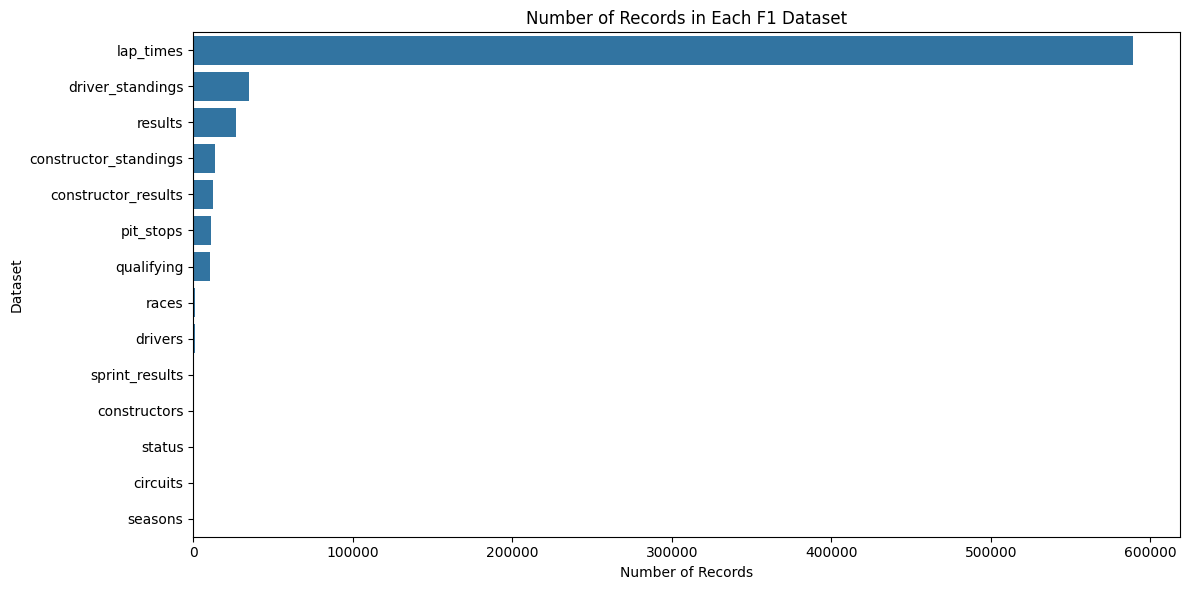

In [32]:
### Initial EDA Findings
# The dataset consists of 14 relational tables with significantly different sizes.
# The `lap_times` table contains the largest number of records (589,081), reflecting the multiple lap observations recorded for each driver during a race. In contrast, smaller reference tables, such as `seasons` and `circuits`, contain relatively few records.
# Several tables contain substantial missing data. In particular, `results`, `qualifying`, and `races` have high numbers of missing values. These require further investigation to distinguish historical data limitations, structurally unavailable measurements, and values requiring cleaning.
# No exact duplicate rows were detected across the 14 tables. However, additional primary-key, foreign-key, and driver–race uniqueness checks are still required.

plt.figure(figsize=(12, 6))

sns.barplot(
    data=dataset_overview.sort_values("Rows", ascending=False),
    x="Rows",
    y="Table"
)

plt.title("Number of Records in Each F1 Dataset")
plt.xlabel("Number of Records")
plt.ylabel("Dataset")
plt.tight_layout()
plt.show()


In [33]:

## 1.2 Missing Value Analysis
# We examine the proportion of missing values in each dataset before applying cleaning operations.

# Calculate missing-value statistics before cleaning

missing_summary = pd.DataFrame([
    {
        "Table": name,
        "Total Cells": df.size,
        "Missing Values": df.isna().sum().sum(),
        "Missing Percentage": (
            df.isna().sum().sum() / df.size * 100
            if df.size > 0 else 0
        )
    }
    for name, df in datasets.items()
])

missing_summary = missing_summary.sort_values(
    "Missing Percentage", ascending=False
)

display(missing_summary.round(2))


,Table,Total Cells,Missing Values,Missing Percentage
6,races,20250,11349,56.04
7,results,481662,122887,25.51
4,drivers,7749,1559,20.12
2,constructor_results,63125,12608,19.97
8,qualifying,94446,11668,12.35
11,sprint_results,5760,73,1.27
5,driver_standings,244041,0,0.00
3,constructor_standings,93737,0,0.00
0,circuits,693,0,0.00
1,constructors,1060,0,0.00


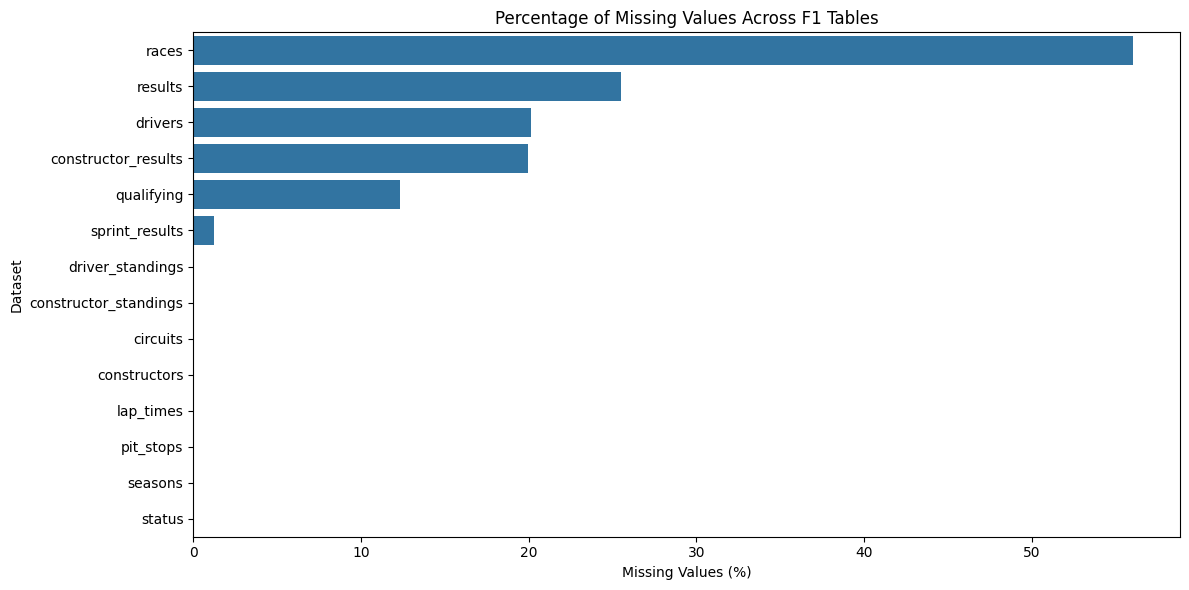

In [34]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_summary,
    x="Missing Percentage",
    y="Table"
)

plt.title("Percentage of Missing Values Across F1 Tables")
plt.xlabel("Missing Values (%)")
plt.ylabel("Dataset")

plt.tight_layout()
plt.show()


In [35]:
### Missing Value Analysis: Findings
# The missing-value analysis revealed substantial differences in data completeness across the 14 Formula 1 tables.
# The `races` table has the highest overall missingness (56.04%), followed by `results` (25.51%), `drivers` (20.12%), `constructor_results` (19.97%), and `qualifying` (12.35%). Eight tables contain no missing values.
# A closer examination of `results` revealed particularly high missingness in timing-related attributes. The `time` and `milliseconds` columns each have 71.30% missing values, while fastest-lap attributes have approximately 68–69% missingness.
# These missing values may reflect historical limitations in data collection, race retirements, or measurements that were not applicable to certain records. Their causes require further investigation before cleaning decisions are made.
# Importantly, the `positionOrder` column contains no missing values and can be used to construct the binary podium prediction target.
# Therefore, rows should not be removed solely because post-race timing measurements or official finishing positions are unavailable. Missing values will be handled according to column meaning, historical coverage, and their relevance to the prediction task.

# Missing values by column for the results table

results_missing = pd.DataFrame({
    "Missing Count": results.isna().sum(),
    "Missing Percentage": results.isna().mean() * 100
})

results_missing = results_missing[
    results_missing["Missing Count"] > 0
].sort_values("Missing Percentage", ascending=False)

display(results_missing.round(2))


,Missing Count,Missing Percentage
milliseconds,19079,71.30
time,19079,71.30
fastestLapTime,18507,69.16
fastestLap,18507,69.16
fastestLapSpeed,18507,69.16
rank,18249,68.20
position,10953,40.93
number,6,0.02


In [36]:

## 1.3 Historical Qualifying Data Coverage
# We investigate how qualifying data availability varies across Formula 1 seasons. This helps identify historical coverage limitations and their potential impact on feature engineering.

# Identify races with qualifying records

qualifying_coverage = races[
    ["raceId", "year"]
].merge(
    qualifying[["raceId", "driverId"]],
    on="raceId",
    how="left"
)

# Calculate the proportion of race entrants
# who have a qualifying record in each season

race_entries = results[
    ["raceId", "driverId"]
].drop_duplicates()

race_entries = race_entries.merge(
    races[["raceId", "year"]],
    on="raceId",
    how="left"
)

qualifying_keys = qualifying[
    ["raceId", "driverId"]
].drop_duplicates()

race_entries = race_entries.merge(
    qualifying_keys.assign(has_qualifying=1),
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

race_entries["has_qualifying"] = (
    race_entries["has_qualifying"]
    .fillna(0)
)

coverage_by_year = (
    race_entries.groupby("year")["has_qualifying"]
    .mean()
    .mul(100)
    .reset_index(name="Coverage Percentage")
)

display(coverage_by_year)


,year,Coverage Percentage
0,1950,0.000000
1,1951,0.000000
2,1952,0.000000
3,1953,0.000000
4,1954,0.000000
...,...,...
70,2020,100.000000
71,2021,99.772727
72,2022,100.000000
73,2023,100.000000


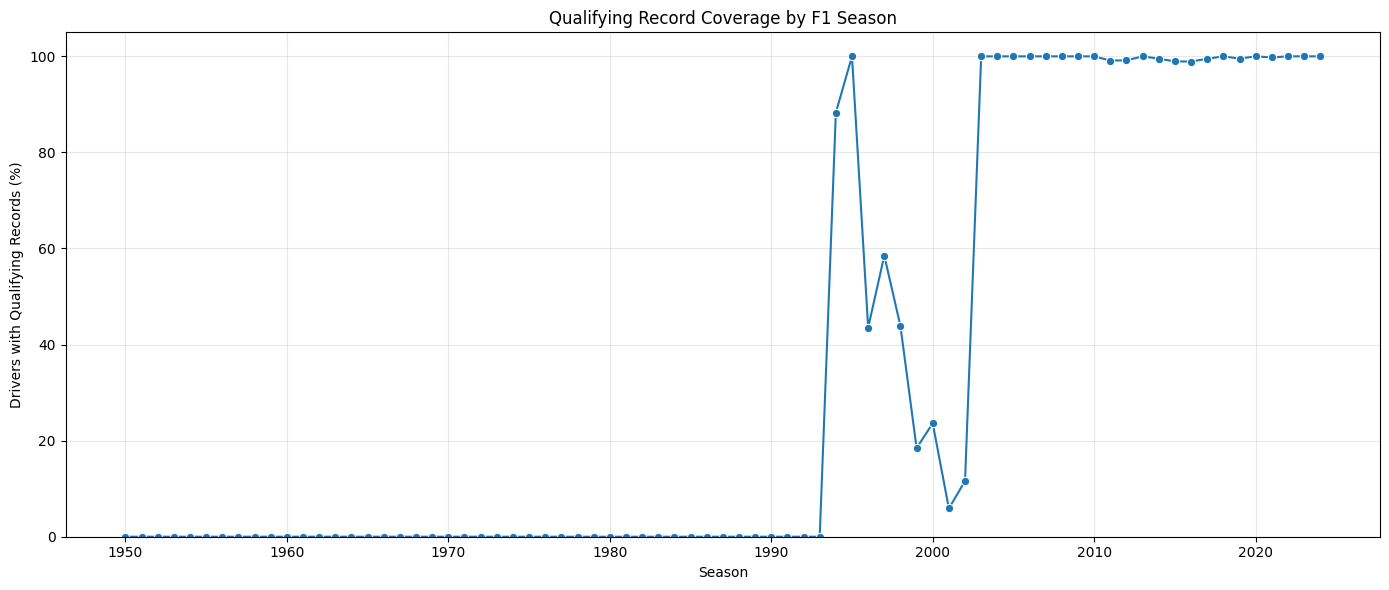

In [37]:
### Historical Qualifying Coverage: Findings
# The analysis reveals substantial historical variation in qualifying data availability.
# Between 1950 and 1993, no matching qualifying records were found in the dataset. From 1994 to 2002, qualifying record coverage fluctuated considerably, indicating inconsistent historical availability.
# From 2003 onward, coverage becomes approximately complete, with nearly 100% of driver–race entries having matching qualifying records.
# These results demonstrate historical qualifying-coverage drift, an important limitation for developing predictive models across multiple Formula 1 eras.
# Consequently, qualifying-based features cannot be treated as uniformly available throughout the dataset. Starting-grid position may provide an alternative source of pre-race information for older seasons, while qualifying-specific attributes require additional missing-data analysis.
# The final feature-engineering strategy must account for these historical differences without using information unavailable before the race.

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=coverage_by_year,
    x="year",
    y="Coverage Percentage",
    marker="o"
)

plt.title("Qualifying Record Coverage by F1 Season")
plt.xlabel("Season")
plt.ylabel("Drivers with Qualifying Records (%)")

plt.ylim(0, 105)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [38]:

## 1.4 Data Integrity Auditing
### Primary-Key Validation
# Before cleaning and joining the relational tables, we validate the uniqueness and completeness of their primary keys. This helps identify potential data-integrity issues that could affect subsequent analysis.


# Candidate primary keys for the 14 F1 tables

primary_keys = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": ["resultId"],
    "seasons": ["year"],
    "status": ["statusId"]
}

pk_audit = []

for name, key_columns in primary_keys.items():
    df = datasets[name]

    null_keys = df[key_columns].isna().any(axis=1).sum()
    duplicate_keys = df.duplicated(
        subset=key_columns
    ).sum()

    pk_audit.append({
        "Table": name,
        "Primary Key": ", ".join(key_columns),
        "Null Keys": null_keys,
        "Duplicate Keys": duplicate_keys,
        "Valid": null_keys == 0 and duplicate_keys == 0
    })

pk_audit_df = pd.DataFrame(pk_audit)

display(pk_audit_df)


### Primary-Key Audit Findings
# The primary-key validation was performed across all 14 relational tables.
# All tables passed the audit, with zero null or duplicate values in their candidate primary keys.
# For tables containing repeated observations, composite keys were used. In particular, `lap_times` was validated using (`raceId`, `driverId`, `lap`), while `pit_stops` was validated using (`raceId`, `driverId`, `stop`).
# These results confirm that the tested keys uniquely identify the records in their respective tables.
# However, primary-key validity does not guarantee referential integrity. Foreign-key relationships must also be examined to identify records referencing nonexistent entities.


,Table,Primary Key,Null Keys,Duplicate Keys,Valid
0,circuits,circuitId,0,0,True
1,constructors,constructorId,0,0,True
2,constructor_results,constructorResultsId,0,0,True
3,constructor_standings,constructorStandingsId,0,0,True
4,drivers,driverId,0,0,True
5,driver_standings,driverStandingsId,0,0,True
6,races,raceId,0,0,True
7,results,resultId,0,0,True
8,qualifying,qualifyId,0,0,True
9,lap_times,"raceId, driverId, lap",0,0,True


In [39]:

### Foreign-Key Validation
# Foreign-key integrity is checked to verify that references between the relational tables are consistent.
# For each relationship, we compare the foreign-key values in the child table against the corresponding primary-key values in the parent table.
# This helps identify orphan records that could cause missing information or unexpected behavior during table joins.


# Foreign-key relationships:
# (child table, foreign key, parent table, parent key)

foreign_keys = [
    ("races", "circuitId", "circuits", "circuitId"),

    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),

    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),

    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),

    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),

    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),

    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),

    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),

    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),

    ("races", "year", "seasons", "year")
]

fk_audit = []

for child, fk, parent, pk in foreign_keys:

    child_values = datasets[child][fk]
    parent_values = datasets[parent][pk]

    missing_fk = child_values.isna().sum()

    invalid_fk = (
        child_values.notna()
        & ~child_values.isin(parent_values.dropna())
    ).sum()

    fk_audit.append({
        "Child Table": child,
        "Foreign Key": fk,
        "Parent Table": parent,
        "Null References": missing_fk,
        "Invalid References": invalid_fk,
        "Valid": invalid_fk == 0
    })

fk_audit_df = pd.DataFrame(fk_audit)

display(fk_audit_df)

print(
    "Relationships with invalid references:",
    (fk_audit_df["Invalid References"] > 0).sum()
)


### Foreign-Key Audit Findings
# Foreign-key validation was performed across 22 relationships connecting the Formula 1 relational tables.
# All 22 relationships passed the integrity checks, with zero null references and zero invalid references.
# These findings indicate that the tested relationships are consistent and that all foreign-key values successfully reference existing records in their corresponding parent tables.
# Although the tested relationships satisfy referential integrity requirements, additional checks are needed to identify duplicated driver–race combinations and determine whether historical shared-drive records violate the required modeling-table granularity.


,Child Table,Foreign Key,Parent Table,Null References,Invalid References,Valid
0,races,circuitId,circuits,0,0,True
1,results,raceId,races,0,0,True
2,results,driverId,drivers,0,0,True
3,results,constructorId,constructors,0,0,True
4,results,statusId,status,0,0,True
5,qualifying,raceId,races,0,0,True
6,qualifying,driverId,drivers,0,0,True
7,qualifying,constructorId,constructors,0,0,True
8,driver_standings,raceId,races,0,0,True
9,driver_standings,driverId,drivers,0,0,True


Relationships with invalid references: 0


In [40]:

## 1.5 Driver–Race Duplicate Investigation
# The prediction task requires one observation for each driver participating in a race.
# Although `resultId` is unique, the combination of `raceId` and `driverId` may not be unique because of historical shared-drive practices.
# We investigate these duplicate combinations before selecting and justifying a deduplication strategy.


# Identify driver-race combinations appearing more than once

driver_race_counts = (
    results.groupby(["raceId", "driverId"])
    .size()
    .reset_index(name="record_count")
)

duplicate_driver_races = driver_race_counts[
    driver_race_counts["record_count"] > 1
].copy()

print(
    "Total result records:",
    len(results)
)

print(
    "Unique driver-race combinations:",
    len(driver_race_counts)
)

print(
    "Duplicate driver-race combinations:",
    len(duplicate_driver_races)
)

print(
    "Extra rows beyond one per driver-race:",
    len(results) - len(driver_race_counts)
)

display(duplicate_driver_races.head(20))


Total result records: 26759
Unique driver-race combinations: 26668
Duplicate driver-race combinations: 85
Extra rows beyond one per driver-race: 91


,raceId,driverId,record_count
13659,540,229,2
17821,717,373,2
18222,733,465,2
18445,742,475,2
18532,745,418,2
18553,746,475,2
18982,766,541,2
19080,770,479,2
19170,774,566,2
19210,776,581,2


In [41]:

# Retrieve all records belonging to duplicate driver-race groups

duplicate_details = results.merge(
    duplicate_driver_races[
        ["raceId", "driverId"]
    ],
    on=["raceId", "driverId"],
    how="inner"
)

# Add race year and driver name for easier interpretation

duplicate_details = duplicate_details.merge(
    races[["raceId", "year", "name"]],
    on="raceId",
    how="left"
)

duplicate_details = duplicate_details.merge(
    drivers[["driverId", "forename", "surname"]],
    on="driverId",
    how="left"
)

duplicate_details = duplicate_details.sort_values(
    ["year", "raceId", "driverId", "resultId"]
)

display(
    duplicate_details[
        [
            "year",
            "name",
            "forename",
            "surname",
            "raceId",
            "driverId",
            "resultId",
            "grid",
            "positionOrder",
            "points",
            "statusId"
        ]
    ].head(30)
)


,year,name,forename,surname,raceId,driverId,resultId,grid,positionOrder,points,statusId
84,1950,Indianapolis 500,Tony,Bettenhausen,835,529,20097,8,31,0.0,67
88,1950,Indianapolis 500,Tony,Bettenhausen,835,529,20179,9,5,1.0,12
85,1950,French Grand Prix,Louis,Rosier,838,627,20143,6,12,0.0,25
89,1950,French Grand Prix,Louis,Rosier,838,627,20182,15,6,0.0,18
86,1950,Italian Grand Prix,Juan,Fangio,839,579,20164,1,15,1.0,6
91,1950,Italian Grand Prix,Juan,Fangio,839,579,20184,7,13,0.0,5
87,1950,Italian Grand Prix,Alberto,Ascari,839,647,20166,2,17,0.0,5
90,1950,Italian Grand Prix,Alberto,Ascari,839,647,20183,6,2,3.0,1
81,1951,French Grand Prix,Juan,Fangio,828,579,19928,1,11,0.0,115
92,1951,French Grand Prix,Juan,Fangio,828,579,20186,7,1,5.0,1


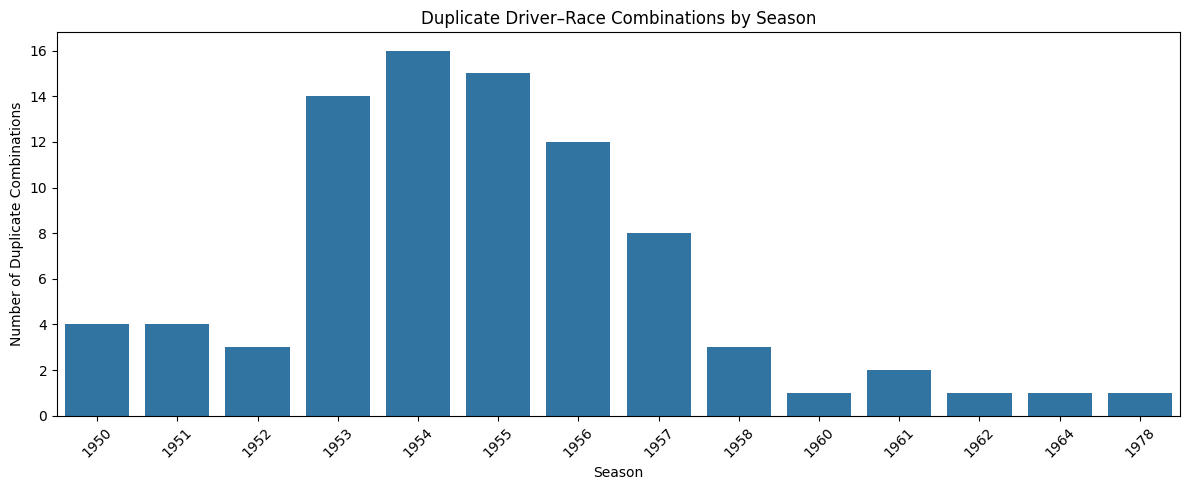

In [42]:

### Duplicate Driver–Race Analysis
# The `results` table contains 26,759 records but only 26,668 unique driver–race combinations. A total of 85 driver–race combinations appear more than once, resulting in 91 additional records.
# The duplicate records are concentrated primarily in early Formula 1 seasons, consistent with historical shared-drive practices.
# Because the prediction is performed before the race starts, deduplication should avoid selecting records based on their final finishing position. We first investigate the available starting-grid information to assess whether a reproducible selection rule can be applied.


duplicate_years = duplicate_driver_races.merge(
    races[["raceId", "year"]],
    on="raceId",
    how="left"
)

duplicates_by_year = (
    duplicate_years.groupby("year")
    .size()
    .reset_index(name="Duplicate Combinations")
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=duplicates_by_year,
    x="year",
    y="Duplicate Combinations"
)

plt.title("Duplicate Driver–Race Combinations by Season")
plt.xlabel("Season")
plt.ylabel("Number of Duplicate Combinations")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [43]:
# Additional Check to investigate:
# More than two records: Some drivers may appear in several records for one race.
# Multiple positive grid positions: Selecting the smallest grid does not necessarily identify which car the driver originally drove.
# Conflicting podium labels: The choice of record could change whether the driver is labeled as a podium finisher.

# Examine the structure of duplicate groups

duplicate_group_audit = (
    duplicate_details
    .groupby(["raceId", "driverId"])
    .agg(
        year=("year", "first"),
        driver=("surname", "first"),
        records=("resultId", "size"),
        positive_grid_entries=("grid", lambda x: (x > 0).sum()),
        zero_grid_entries=("grid", lambda x: (x == 0).sum()),
        distinct_grid_positions=("grid", "nunique"),
        distinct_podium_labels=(
            "positionOrder",
            lambda x: (x <= 3).nunique()
        )
    )
    .reset_index()
)

display(duplicate_group_audit.head(20))

print(
    "Groups with more than two records:",
    (duplicate_group_audit["records"] > 2).sum()
)

print(
    "Groups with multiple positive grid positions:",
    (duplicate_group_audit["positive_grid_entries"] > 1).sum()
)

print(
    "Groups with conflicting podium labels:",
    (duplicate_group_audit["distinct_podium_labels"] > 1).sum()
)


### Duplicate Investigation Findings and Cleaning Strategy
# The investigation identified 85 duplicated driver–race combinations, corresponding to 91 additional records beyond the required one-row-per-driver-race structure.
# Of these duplicated groups, six contain more than two records, while 82 contain multiple positive starting-grid positions. Additionally, 21 groups contain conflicting podium labels, meaning that different records for the same driver and race may indicate different finishing outcomes.
# These findings are consistent with historical Formula 1 shared-drive practices and demonstrate why simple deduplication is insufficient without a documented selection rule.
# For the modeling table, a deterministic grid-based selection strategy is adopted. Records with positive grid positions are prioritized, followed by the smallest positive grid position and then the smallest resultId in case of ties.
# This strategy avoids selecting records based directly on post-race finishing performance. Nevertheless, it is a practical approximation and may not always recover the driver's original car or overall official classification. The resulting historical label uncertainty is acknowledged as a limitation.


,raceId,driverId,year,driver,records,positive_grid_entries,zero_grid_entries,distinct_grid_positions,distinct_podium_labels
0,540,229,1978,Ertl,2,0,2,1,1
1,717,373,1964,Clark,2,2,0,1,1
2,733,465,1962,Greene,2,0,2,1,1
3,742,475,1961,Moss,2,2,0,2,1
4,745,418,1961,Gregory,2,2,0,2,1
5,746,475,1960,Moss,2,2,0,2,2
6,766,541,1958,Flockhart,2,0,2,1,1
7,770,479,1958,Brooks,2,2,0,2,1
8,774,566,1958,Shelby,2,2,0,2,1
9,776,581,1957,Collins,2,2,0,2,1


Groups with more than two records: 6
Groups with multiple positive grid positions: 82
Groups with conflicting podium labels: 21


In [44]:

## Deduplication


# Preserve the original results DataFrame
results_clean = results.copy()

# Prioritize positive grid positions
results_clean["grid_priority"] = (
    results_clean["grid"] <= 0
).astype(int)

# Sort records using our documented selection rule
results_clean = results_clean.sort_values(
    by=[
        "raceId",
        "driverId",
        "grid_priority",
        "grid",
        "resultId"
    ]
)

# Keep one record per driver-race combination
results_clean = results_clean.drop_duplicates(
    subset=["raceId", "driverId"],
    keep="first"
)

# Remove temporary helper column
results_clean = (
    results_clean
    .drop(columns=["grid_priority"])
    .reset_index(drop=True)
)

print("Original rows:", len(results))
print("Cleaned rows:", len(results_clean))
print("Removed rows:", len(results) - len(results_clean))

print(
    "Remaining duplicate driver-race combinations:",
    results_clean.duplicated(
        ["raceId", "driverId"]
    ).sum()
)


Original rows: 26759
Cleaned rows: 26668
Removed rows: 91
Remaining duplicate driver-race combinations: 0


In [45]:

# Compare podium-label counts before and after deduplication

original_podium_count = (
    results["positionOrder"] <= 3
).sum()

cleaned_podium_count = (
    results_clean["positionOrder"] <= 3
).sum()

comparison = pd.DataFrame({
    "Dataset": ["Original", "Deduplicated"],
    "Rows": [len(results), len(results_clean)],
    "Podium Rows": [
        original_podium_count,
        cleaned_podium_count
    ]
})

comparison["Podium Rate (%)"] = (
    comparison["Podium Rows"]
    / comparison["Rows"] * 100
)

display(comparison.round(2))


### Deduplication Results
# The grid-based deduplication strategy reduced the results table from 26,759 to 26,668 records by removing 91 additional driver–race entries.
# After cleaning, no duplicate (`raceId`, `driverId`) combinations remained, satisfying the required modeling-table granularity.
# The number of podium-labeled records decreased from 3,397 to 3,378, while the overall podium rate changed slightly from 12.69% to 12.67%.
# The small change in the overall class distribution suggests that deduplication had a limited aggregate effect on podium frequency. However, 21 duplicated groups originally contained conflicting podium labels, so uncertainty remains for some historical driver–race outcomes.
# The selected grid-based rule is therefore documented as a reproducible approximation rather than a definitive reconstruction of historical shared-drive results.


,Dataset,Rows,Podium Rows,Podium Rate (%)
0,Original,26759,3397,12.69
1,Deduplicated,26668,3378,12.67


In [46]:

## 1.6 Missing-Value Sentinel Handling and Data Type Conversion
# The original CSV files use the literal `\N` to represent missing information.
# During CSV loading, this placeholder was converted into a missing value using Pandas.
# We now verify that no sentinel strings remain, create independent working copies of the datasets, and convert date and lap-time columns into suitable data types.
# These operations preserve the original datasets and avoid modifying raw source files.


# Create independent copies of the original tables
cleaned_datasets = {
    name: df.copy()
    for name, df in datasets.items()
}

# Use the deduplicated results table
cleaned_datasets["results"] = results_clean.copy()

# Check for any remaining literal \N placeholders
sentinel_audit = []

for name, df in cleaned_datasets.items():

    # Check textual columns only
    text_columns = df.select_dtypes(
        include=["object", "string"]
    ).columns

    sentinel_count = (
        df[text_columns]
        .eq("\\N")
        .sum()
        .sum()
    )

    sentinel_audit.append({
        "Table": name,
        "Remaining Sentinels": int(sentinel_count)
    })

    # Replace any remaining sentinels with NaN
    cleaned_datasets[name] = df.replace(
        "\\N", np.nan
    )

sentinel_audit_df = pd.DataFrame(sentinel_audit)

display(sentinel_audit_df)


,Table,Remaining Sentinels
0,circuits,0
1,constructors,0
2,constructor_results,0
3,constructor_standings,0
4,drivers,0
5,driver_standings,0
6,races,0
7,results,0
8,qualifying,0
9,lap_times,0


In [47]:

# Convert date columns to datetime

date_columns = {
    "drivers": ["dob"],
    "races": [
        "date",
        "fp1_date",
        "fp2_date",
        "fp3_date",
        "quali_date",
        "sprint_date"
    ]
}

for table_name, columns in date_columns.items():
    for column in columns:
        cleaned_datasets[table_name][column] = pd.to_datetime(
            cleaned_datasets[table_name][column],
            errors="coerce"
        )

# Verify converted data types
print("Driver date of birth:")
print(cleaned_datasets["drivers"]["dob"].dtype)

print("\nRace date:")
print(cleaned_datasets["races"]["date"].dtype)


### Sentinel Handling and Date Conversion Findings
# The sentinel audit confirmed that all 14 tables contained zero remaining literal `\N` placeholders after loading. This indicates that the initial CSV-loading procedure successfully converted these placeholders into Pandas missing values.
# Date-related columns were subsequently converted from strings into datetime representations using `pd.to_datetime()`.
# Validation confirmed that the driver date-of-birth (`dob`) and race date (`date`) columns now use the `datetime64[ns]` datatype.
# All transformations were performed on independent DataFrame copies to preserve the original data. Additional validation is performed to determine whether date parsing introduced any new missing values.


Driver date of birth:
datetime64[ns]

Race date:
datetime64[ns]


In [48]:

## 1.7 Time Conversion and Semantic Typing
# Lap-time values are originally stored as strings representing minutes and seconds.
# To enable numerical analysis, qualifying times and recorded lap durations are converted into seconds.
# The conversion preserves missing values and handles parsing failures explicitly. New numeric columns are created so that the original string representations remain available for comparison.


# Convert lap-time strings to numeric seconds

def lap_time_to_seconds(value):
    if pd.isna(value):
        return np.nan

    try:
        parts = str(value).split(":")

        if len(parts) == 2:
            minutes = float(parts[0])
            seconds = float(parts[1])

            return minutes * 60 + seconds

        return np.nan

    except (ValueError, TypeError):
        return np.nan


In [49]:

# Convert qualifying lap times

for column in ["q1", "q2", "q3"]:
    cleaned_datasets["qualifying"][column + "_seconds"] = (
        cleaned_datasets["qualifying"][column]
        .apply(lap_time_to_seconds)
    )

# Convert lap_times duration in milliseconds to seconds

cleaned_datasets["lap_times"]["lap_time_seconds"] = (
    pd.to_numeric(
        cleaned_datasets["lap_times"]["milliseconds"],
        errors="coerce"
    ) / 1000
)

# Convert pit stop duration in milliseconds to seconds

cleaned_datasets["pit_stops"]["duration_seconds"] = (
    pd.to_numeric(
        cleaned_datasets["pit_stops"]["milliseconds"],
        errors="coerce"
    ) / 1000
)

# Display example conversions

display(
    cleaned_datasets["qualifying"][
        ["q1", "q1_seconds", "q2", "q2_seconds", "q3", "q3_seconds"]
    ].head(10)
)

display(
    cleaned_datasets["lap_times"][
        ["time", "milliseconds", "lap_time_seconds"]
    ].head(5)
)


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236
5,1:26.427,86.427,1:26.101,86.101,1:28.527,88.527
6,1:26.295,86.295,1:26.059,86.059,1:28.687,88.687
7,1:26.381,86.381,1:26.063,86.063,1:29.041,89.041
8,1:26.919,86.919,1:26.164,86.164,1:29.593,89.593
9,1:26.702,86.702,1:25.842,85.842,NaN,NaN


,time,milliseconds,lap_time_seconds
0,1:38.109,98109,98.109
1,1:33.006,93006,93.006
2,1:32.713,92713,92.713
3,1:32.803,92803,92.803
4,1:32.342,92342,92.342


In [50]:

# Check conversion results

conversion_audit = []

for column in ["q1", "q2", "q3"]:
    original = cleaned_datasets["qualifying"][column]
    converted = cleaned_datasets["qualifying"][column + "_seconds"]

    conversion_audit.append({
        "Column": column,
        "Original Non-Null": original.notna().sum(),
        "Converted Non-Null": converted.notna().sum(),
        "New Parsing Failures": (
            original.notna() & converted.isna()
        ).sum()
    })

display(pd.DataFrame(conversion_audit))

# Check whether date parsing introduced missing values

date_audit = []

for table_name, columns in date_columns.items():
    for column in columns:
        before = datasets[table_name][column]
        after = cleaned_datasets[table_name][column]

        date_audit.append({
            "Table": table_name,
            "Column": column,
            "Before Missing": before.isna().sum(),
            "After Missing": after.isna().sum(),
            "New Missing": (
                before.notna() & after.isna()
            ).sum()
        })

display(pd.DataFrame(date_audit))


### Semantic Data Type Conversion: Findings
# Qualifying lap times were converted from minute-second strings into numeric seconds to support subsequent statistical analysis.
# The conversion was successful for all available qualifying records. Specifically, 10,338 Q1 times, 5,847 Q2 times, and 3,629 Q3 times were converted without introducing any additional missing values.
# Recorded lap durations and pit-stop durations were also converted from milliseconds into seconds.
# Date-related attributes were converted into datetime representations. Validation showed that these conversions introduced no additional missing values.
# The original string representations were preserved, while new numeric columns were created for time-based analysis.
# The differences in Q1, Q2, and Q3 availability should not automatically be treated as data-quality errors because qualifying participation varies between sessions and historical formats.
# These transformations improve data consistency while preserving the original information and existing missing-value patterns.


,Column,Original Non-Null,Converted Non-Null,New Parsing Failures
0,q1,10338,10338,0
1,q2,5847,5847,0
2,q3,3629,3629,0


,Table,Column,Before Missing,After Missing,New Missing
0,drivers,dob,0,0,0
1,races,date,0,0,0
2,races,fp1_date,1035,1035,0
3,races,fp2_date,1035,1035,0
4,races,fp3_date,1053,1053,0
5,races,quali_date,1035,1035,0
6,races,sprint_date,1107,1107,0


In [51]:

## 1.8 Post-Cleaning Exploratory Data Analysis
# After performing deduplication, missing-value handling, and semantic datatype conversion, we compare the original and cleaned datasets.
# The objective is to quantify the impact of preprocessing on dataset size, missingness, and the distribution of the podium prediction target.
# We also validate that the cleaned results table satisfies the required one-row-per-driver-race structure.


# Compare row counts before and after cleaning

cleaning_comparison = []

for name in datasets:

    original_df = datasets[name]
    cleaned_df = cleaned_datasets[name]

    cleaning_comparison.append({
        "Table": name,
        "Original Rows": len(original_df),
        "Cleaned Rows": len(cleaned_df),
        "Rows Removed": len(original_df) - len(cleaned_df),
        "Original Missing": int(original_df.isna().sum().sum()),
        "Cleaned Missing": int(
            cleaned_df[
                original_df.columns
            ].isna().sum().sum()
        )
    })

cleaning_comparison_df = pd.DataFrame(cleaning_comparison)

display(cleaning_comparison_df)


,Table,Original Rows,Cleaned Rows,Rows Removed,Original Missing,Cleaned Missing
0,circuits,77,77,0,0,0
1,constructors,212,212,0,0,0
2,constructor_results,12625,12625,0,12608,12608
3,constructor_standings,13391,13391,0,0,0
4,drivers,861,861,0,1559,1559
5,driver_standings,34863,34863,0,0,0
6,races,1125,1125,0,11349,11349
7,results,26759,26668,91,122887,122332
8,qualifying,10494,10494,0,11668,11668
9,lap_times,589081,589081,0,0,0


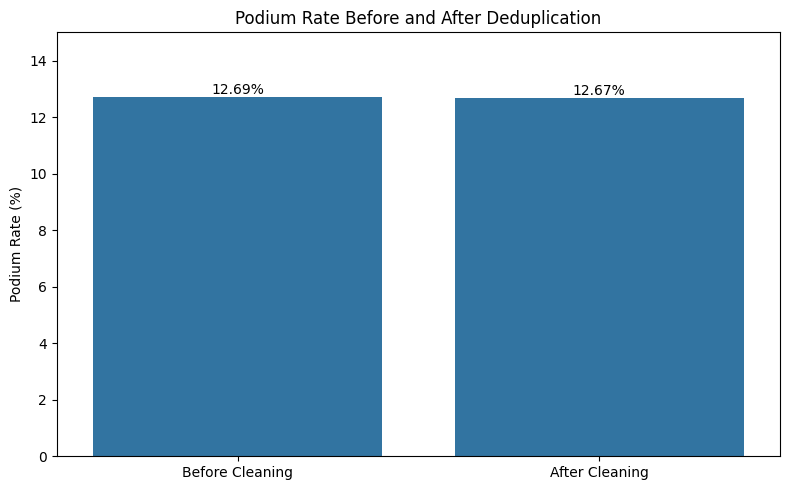

,Dataset,Podium Rate (%)
0,Before Cleaning,12.695
1,After Cleaning,12.667


In [52]:

# Compare podium rates before and after cleaning

podium_comparison = pd.DataFrame({
    "Dataset": ["Before Cleaning", "After Cleaning"],
    "Podium Rate (%)": [
        (results["positionOrder"] <= 3).mean() * 100,
        (
            cleaned_datasets["results"]["positionOrder"] <= 3
        ).mean() * 100
    ]
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=podium_comparison,
    x="Dataset",
    y="Podium Rate (%)"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Podium Rate Before and After Deduplication")
plt.ylabel("Podium Rate (%)")
plt.xlabel("")

plt.ylim(0, 15)
plt.tight_layout()
plt.show()

display(podium_comparison.round(3))


In [53]:

# Final validation of cleaned results

final_results = cleaned_datasets["results"]

assert final_results.duplicated(
    ["raceId", "driverId"]
).sum() == 0, "Duplicate driver-race combinations remain."

assert final_results["raceId"].notna().all(), \
    "Missing race identifiers detected."

assert final_results["driverId"].notna().all(), \
    "Missing driver identifiers detected."

assert final_results["positionOrder"].notna().all(), \
    "Missing target values detected."

assert len(final_results) == 26668, \
    "Unexpected number of records after cleaning."

print("All final validation checks passed.")
print("Cleaned records:", len(final_results))
print(
    "Unique driver-race combinations:",
    final_results[["raceId", "driverId"]]
    .drop_duplicates().shape[0]
)


## 1.9 EDA and Data Cleaning Summary
# The initial exploratory analysis examined 14 relational Formula 1 tables and identified considerable differences in dataset size, completeness, and historical coverage.
# Missing-value analysis revealed that the races, results, drivers, constructor_results, and qualifying tables contained substantial missing information. Historical qualifying analysis further demonstrated that qualifying record coverage varies significantly across seasons, becoming approximately complete from 2003 onward.
# Primary-key validation found no null or duplicate candidate keys across the 14 tables. Foreign-key auditing also confirmed that all 22 tested relationships contained valid, non-null references.
# The results table initially contained 26,759 records but only 26,668 unique driver–race combinations. A total of 91 extra records were removed using a documented grid-based selection rule. This produced a table with exactly one record per driver–race combination.
# Deduplication reduced the podium rate slightly from 12.695% to 12.667%. However, some historical shared-drive entries had conflicting podium labels, meaning that the selected outcomes should be interpreted with caution.
# Missing-value sentinels were standardized, dates were converted to datetime representations, and qualifying lap times and recorded durations were converted into numeric seconds. Validation confirmed that these conversions introduced no additional missing values in the tested date and qualifying-time columns.
# Post-cleaning checks confirmed that the cleaned results table contains 26,668 unique driver–race records with no remaining duplicate combinations.
# The cleaned tables provide a consistent foundation for subsequent relational analysis and feature engineering. Nevertheless, historical data limitations, missing measurements, and uncertainty in shared-drive records must be considered during downstream modeling.


All final validation checks passed.
Cleaned records: 26668
Unique driver-race combinations: 26668


In [54]:

# Verify that the cleaned tables are available
# for the next stage of the project.

print("Cleaned tables:", len(cleaned_datasets))

print(
    "Cleaned results shape:",
    cleaned_datasets["results"].shape
)

print(
    "Qualifying columns:",
    cleaned_datasets["qualifying"].columns.tolist()
)

print(
    "Duplicate driver-race entries:",
    cleaned_datasets["results"]
    .duplicated(["raceId", "driverId"])
    .sum()
)


Cleaned tables: 14
Cleaned results shape: (26668, 18)
Qualifying columns: ['qualifyId', 'raceId', 'driverId', 'constructorId', 'number', 'position', 'q1', 'q2', 'q3', 'q1_seconds', 'q2_seconds', 'q3_seconds']
Duplicate driver-race entries: 0


In [55]:
# Prepare cleaned datasets for Member 2
results_clean = cleaned_datasets["results"]
qualifying_clean = cleaned_datasets["qualifying"]
races_clean = cleaned_datasets["races"]

In [56]:
print("Available cleaned datasets:")
print(list(cleaned_datasets.keys()))

Available cleaned datasets:
['circuits', 'constructors', 'constructor_results', 'constructor_standings', 'drivers', 'driver_standings', 'races', 'results', 'qualifying', 'lap_times', 'pit_stops', 'sprint_results', 'seasons', 'status']


In [57]:
tables = ['results', 'races', 'circuits', 'qualifying']

for table in tables:
    df = cleaned_datasets[table]

    print(f"\n{'='*50}")
    print(f"TABLE: {table}")
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    print(f"\nFirst 3 rows:")
    display(df.head(3))


TABLE: results
Shape: (26668, 18)
Columns: ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId']

First 3 rows:


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,7573,1,1,1,1.0,18,NaN,D,20,0.0,58,NaN,NaN,39.0,13.0,1:29.020,214.455,2
1,7563,1,2,2,6.0,9,10.0,10,10,0.0,58,+7.085,5662869.0,48.0,5.0,1:28.283,216.245,1
2,7559,1,3,3,16.0,5,6.0,6,6,3.0,58,+5.722,5661506.0,48.0,1.0,1:27.706,217.668,1



TABLE: races
Shape: (1125, 18)
Columns: ['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'time', 'url', 'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date', 'quali_time', 'sprint_date', 'sprint_time']

First 3 rows:


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN



TABLE: circuits
Shape: (77, 9)
Columns: ['circuitId', 'circuitRef', 'name', 'location', 'country', 'lat', 'lng', 'alt', 'url']

First 3 rows:


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.9680,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.7380,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.5106,7,http://en.wikipedia.org/wiki/Bahrain_Internati...



TABLE: qualifying
Shape: (10494, 12)
Columns: ['qualifyId', 'raceId', 'driverId', 'constructorId', 'number', 'position', 'q1', 'q2', 'q3', 'q1_seconds', 'q2_seconds', 'q3_seconds']

First 3 rows:


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714,86.572,85.187,86.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869,86.103,85.315,86.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079,85.664,85.452,87.079


In [58]:


# Select relevant columns
results_df = cleaned_datasets['results'][
    ['raceId', 'driverId', 'grid', 'positionOrder']
].copy()

races_df = cleaned_datasets['races'][
    ['raceId', 'year', 'circuitId']
].copy()

circuits_df = cleaned_datasets['circuits'][
    ['circuitId', 'name']
].copy()

qualifying_df = cleaned_datasets['qualifying'][
    ['raceId', 'driverId', 'position']
].copy()

# Rename columns to avoid confusion
circuits_df = circuits_df.rename(
    columns={'name': 'circuit_name'}
)

qualifying_df = qualifying_df.rename(
    columns={'position': 'qualifying_position'}
)

# Multi-hop joins
q1_df = (
    results_df
    .merge(races_df, on='raceId', how='left', validate='many_to_one')
    .merge(circuits_df, on='circuitId', how='left', validate='many_to_one')
    .merge(
        qualifying_df,
        on=['raceId', 'driverId'],
        how='left',
        validate='many_to_one'
    )
)

print("Final shape:", q1_df.shape)

display(q1_df.head())

print("\nMissing values:")
print(q1_df.isna().sum())

print("\nDuplicate driver-race pairs:")
print(q1_df.duplicated(['raceId', 'driverId']).sum())

Final shape: (26668, 8)


,raceId,driverId,grid,positionOrder,year,circuitId,circuit_name,qualifying_position
0,1,1,18,20,2009,1,Albert Park Grand Prix Circuit,15.0
1,1,2,9,10,2009,1,Albert Park Grand Prix Circuit,11.0
2,1,3,5,6,2009,1,Albert Park Grand Prix Circuit,5.0
3,1,4,10,5,2009,1,Albert Park Grand Prix Circuit,12.0
4,1,5,12,19,2009,1,Albert Park Grand Prix Circuit,14.0



Missing values:
raceId                     0
driverId                   0
grid                       0
positionOrder              0
year                       0
circuitId                  0
circuit_name               0
qualifying_position    16174
dtype: int64

Duplicate driver-race pairs:
0


In [59]:
# Inspect starting grid values
print("Grid position distribution:")
display(
    q1_df['grid']
    .value_counts()
    .sort_index()
    .head(12)
)

print("\nRecords with grid = 0:")
print((q1_df['grid'] == 0).sum())

print("\nRecords starting from the front row:")
print(q1_df['grid'].isin([1, 2]).sum())

Grid position distribution:


grid
0     1635
1     1135
2     1124
3     1126
4     1130
5     1128
6     1120
7     1127
8     1128
9     1127
10    1123
11    1128
Name: count, dtype: int64


Records with grid = 0:
1635

Records starting from the front row:
2259


In [60]:
# Create podium indicator
q1_df['podium'] = q1_df['positionOrder'] <= 3

# Separate the two F1 eras
q1_df['era'] = q1_df['year'].apply(
    lambda year: 'Pre-2014' if year < 2014 else '2014 onwards'
)

# Select actual front-row starters
front_row_df = q1_df[
    q1_df['grid'].isin([1, 2])
].copy()

# Calculate conversion rates by circuit and era
circuit_conversion = (
    front_row_df
    .groupby(['circuitId', 'circuit_name', 'era'])
    .agg(
        front_row_starts=('podium', 'size'),
        podium_finishes=('podium', 'sum')
    )
    .reset_index()
)

circuit_conversion['conversion_rate'] = (
    circuit_conversion['podium_finishes']
    / circuit_conversion['front_row_starts']
    * 100
)

# Display the top 10 circuits in each era
for era in ['Pre-2014', '2014 onwards']:
    print(f"\nTop 10 circuits: {era}")

    top_10 = (
        circuit_conversion[
            circuit_conversion['era'] == era
        ]
        .sort_values(
            ['conversion_rate', 'front_row_starts'],
            ascending=[False, False]
        )
        .head(10)
    )

    display(top_10)


Top 10 circuits: Pre-2014


,circuitId,circuit_name,era,front_row_starts,podium_finishes,conversion_rate
90,69,Circuit of the Americas,Pre-2014,4,4,100.000000
48,31,Donington Park,Pre-2014,2,2,100.000000
84,64,Ain Diab,Pre-2014,2,2,100.000000
85,65,Pescara Circuit,Pre-2014,2,2,100.000000
88,68,Buddh International Circuit,Pre-2014,6,5,83.333333
14,8,Circuit de Nevers Magny-Cours,Pre-2014,36,29,80.555556
9,5,Istanbul Park,Pre-2014,14,11,78.571429
61,41,Dijon-Prenois,Pre-2014,12,9,75.000000
45,28,Okayama International Circuit,Pre-2014,4,3,75.000000
39,22,Suzuka Circuit,Pre-2014,50,35,70.000000



Top 10 circuits: 2014 onwards


,circuitId,circuit_name,era,front_row_starts,podium_finishes,conversion_rate
99,79,Miami International Autodrome,2014 onwards,6,6,100.000000
95,75,Autódromo Internacional do Algarve,2014 onwards,4,4,100.000000
100,80,Las Vegas Strip Street Circuit,2014 onwards,4,4,100.000000
96,76,Autodromo Internazionale del Mugello,2014 onwards,2,2,100.000000
38,22,Suzuka Circuit,2014 onwards,18,16,88.888889
58,39,Circuit Park Zandvoort,2014 onwards,8,7,87.500000
97,77,Jeddah Corniche Circuit,2014 onwards,8,7,87.500000
40,24,Yas Marina Circuit,2014 onwards,22,19,86.363636
2,2,Sepang International Circuit,2014 onwards,7,6,85.714286
10,6,Circuit de Monaco,2014 onwards,20,17,85.000000


In [61]:
# Minimum number of front-row starts
MIN_STARTS = 10

# Filter circuits with sufficient observations
circuit_conversion_filtered = circuit_conversion[
    circuit_conversion['front_row_starts'] >= MIN_STARTS
].copy()

# Display top 10 circuits for each era
for era in ['Pre-2014', '2014 onwards']:

    print(f"\nTop circuits with at least {MIN_STARTS} front-row starts: {era}")

    top_10 = (
        circuit_conversion_filtered[
            circuit_conversion_filtered['era'] == era
        ]
        .sort_values(
            ['conversion_rate', 'front_row_starts'],
            ascending=[False, False]
        )
        .head(10)
    )

    display(
        top_10[
            ['circuit_name', 'front_row_starts',
             'podium_finishes', 'conversion_rate']
        ]
    )

print("\nNumber of eligible circuits by era:")
display(
    circuit_conversion_filtered.groupby('era')['circuitId'].nunique()
)


Top circuits with at least 10 front-row starts: Pre-2014


,circuit_name,front_row_starts,podium_finishes,conversion_rate
14,Circuit de Nevers Magny-Cours,36,29,80.555556
9,Istanbul Park,14,11,78.571429
61,Dijon-Prenois,12,9,75.000000
39,Suzuka Circuit,50,35,70.000000
3,Sepang International Circuit,30,21,70.000000
20,Hungaroring,56,38,67.857143
5,Bahrain International Circuit,18,12,66.666667
44,Autódromo do Estoril,26,17,65.384615
7,Circuit de Barcelona-Catalunya,46,30,65.217391
30,Shanghai International Circuit,20,13,65.000000



Top circuits with at least 10 front-row starts: 2014 onwards


,circuit_name,front_row_starts,podium_finishes,conversion_rate
38,Suzuka Circuit,18,16,88.888889
40,Yas Marina Circuit,22,19,86.363636
10,Circuit de Monaco,20,17,85.000000
6,Circuit de Barcelona-Catalunya,22,18,81.818182
22,Circuit de Spa-Francorchamps,22,18,81.818182
93,Sochi Autodrom,16,13,81.250000
89,Circuit of the Americas,20,16,80.000000
31,Autódromo José Carlos Pace,19,15,78.947368
29,Shanghai International Circuit,14,11,78.571429
12,Circuit Gilles Villeneuve,18,14,77.777778



Number of eligible circuits by era:


era
2014 onwards    19
Pre-2014        45
Name: circuitId, dtype: int64

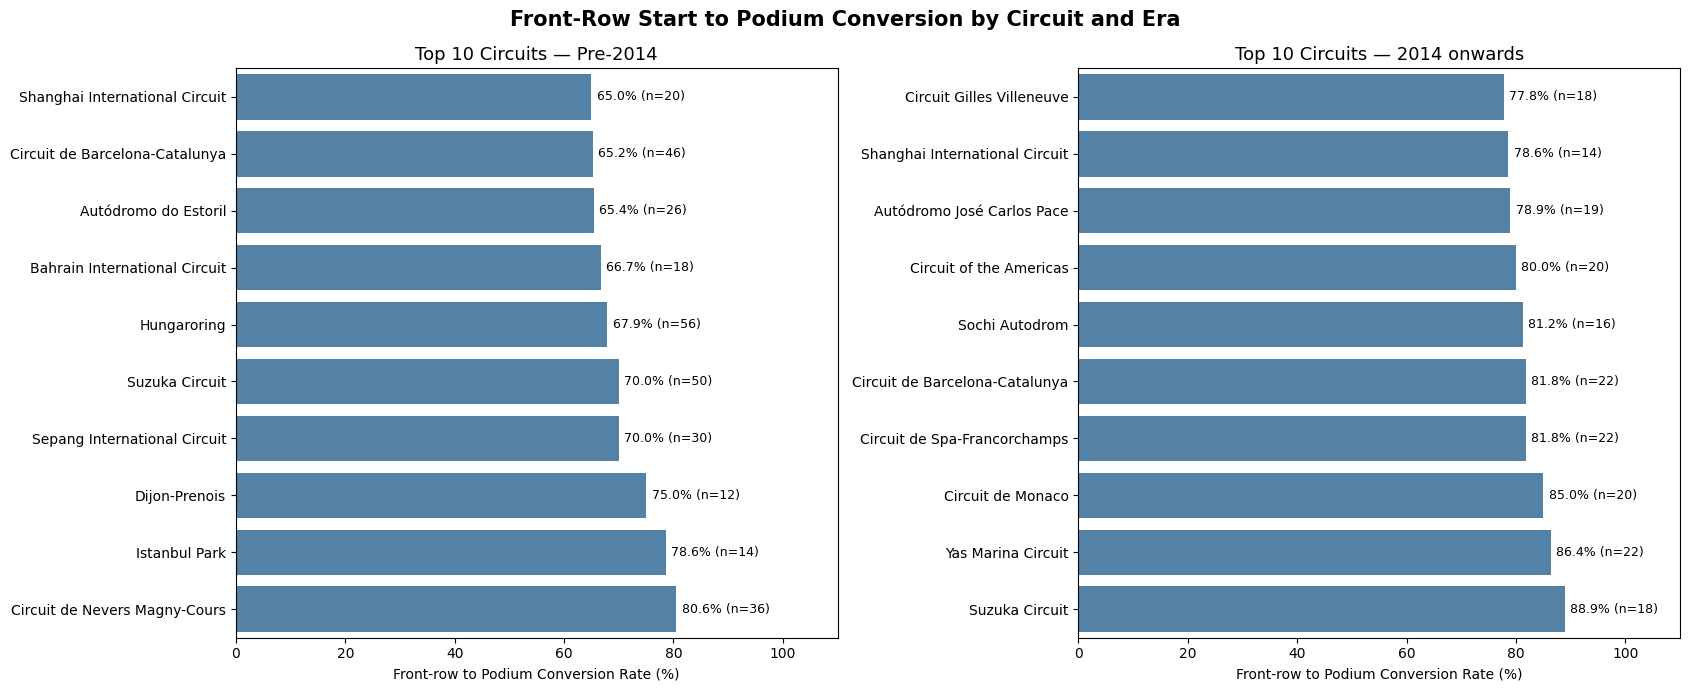

In [62]:


fig, axes = plt.subplots(1, 2, figsize=(17, 7))

eras = ['Pre-2014', '2014 onwards']

for ax, era in zip(axes, eras):

    top_10 = (
        circuit_conversion_filtered[
            circuit_conversion_filtered['era'] == era
        ]
        .sort_values('conversion_rate', ascending=False)
        .head(10)
        .sort_values('conversion_rate')
    )

    sns.barplot(
        data=top_10,
        x='conversion_rate',
        y='circuit_name',
        ax=ax,
        color='steelblue'
    )

    ax.set_title(f'Top 10 Circuits — {era}', fontsize=13)
    ax.set_xlabel('Front-row to Podium Conversion Rate (%)')
    ax.set_ylabel('')
    ax.set_xlim(0, 110)

    for i, (_, row) in enumerate(top_10.iterrows()):
        ax.text(
            row['conversion_rate'] + 1,
            i,
            f"{row['conversion_rate']:.1f}% (n={row['front_row_starts']})",
            va='center',
            fontsize=9
        )

plt.suptitle(
    'Front-Row Start to Podium Conversion by Circuit and Era',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [63]:
# Create a comparison table with circuits as rows and eras as columns
era_comparison = circuit_conversion_filtered.pivot(
    index=['circuitId', 'circuit_name'],
    columns='era',
    values='conversion_rate'
)

# Keep only circuits with enough observations in BOTH eras
era_comparison = era_comparison.dropna().copy()

# Calculate the change in conversion rate
era_comparison['change_pp'] = (
    era_comparison['2014 onwards']
    - era_comparison['Pre-2014']
)

# Calculate rankings within the common set of circuits
era_comparison['rank_pre_2014'] = (
    era_comparison['Pre-2014'].rank(
        ascending=False, method='min'
    )
)

era_comparison['rank_post_2014'] = (
    era_comparison['2014 onwards'].rank(
        ascending=False, method='min'
    )
)

# Positive values indicate improvement in rank
era_comparison['rank_improvement'] = (
    era_comparison['rank_pre_2014']
    - era_comparison['rank_post_2014']
)

era_comparison = era_comparison.sort_values(
    'change_pp',
    ascending=False
)

print("Circuits eligible in both eras:", len(era_comparison))

display(era_comparison.round(2))

Circuits eligible in both eras: 16


,era,2014 onwards,Pre-2014,change_pp,rank_pre_2014,rank_post_2014,rank_improvement
circuitId,circuit_name,,,,,,
6,Circuit de Monaco,85.00,48.76,36.24,15.0,3.0,12.0
13,Circuit de Spa-Francorchamps,81.82,53.26,28.56,12.0,4.0,8.0
24,Yas Marina Circuit,86.36,60.00,26.36,6.0,2.0,4.0
14,Autodromo Nazionale di Monza,72.73,46.88,25.85,16.0,11.0,5.0
7,Circuit Gilles Villeneuve,77.78,52.94,24.84,13.0,8.0,5.0
70,Red Bull Ring,73.08,52.00,21.08,14.0,10.0,4.0
18,Autódromo José Carlos Pace,78.95,59.68,19.27,8.0,6.0,2.0
22,Suzuka Circuit,88.89,70.00,18.89,1.0,1.0,0.0
9,Silverstone Circuit,75.00,56.38,18.62,10.0,9.0,1.0


Question 1: Yes, the circuit rankings changed between the pre-2014 and 2014-onward periods.

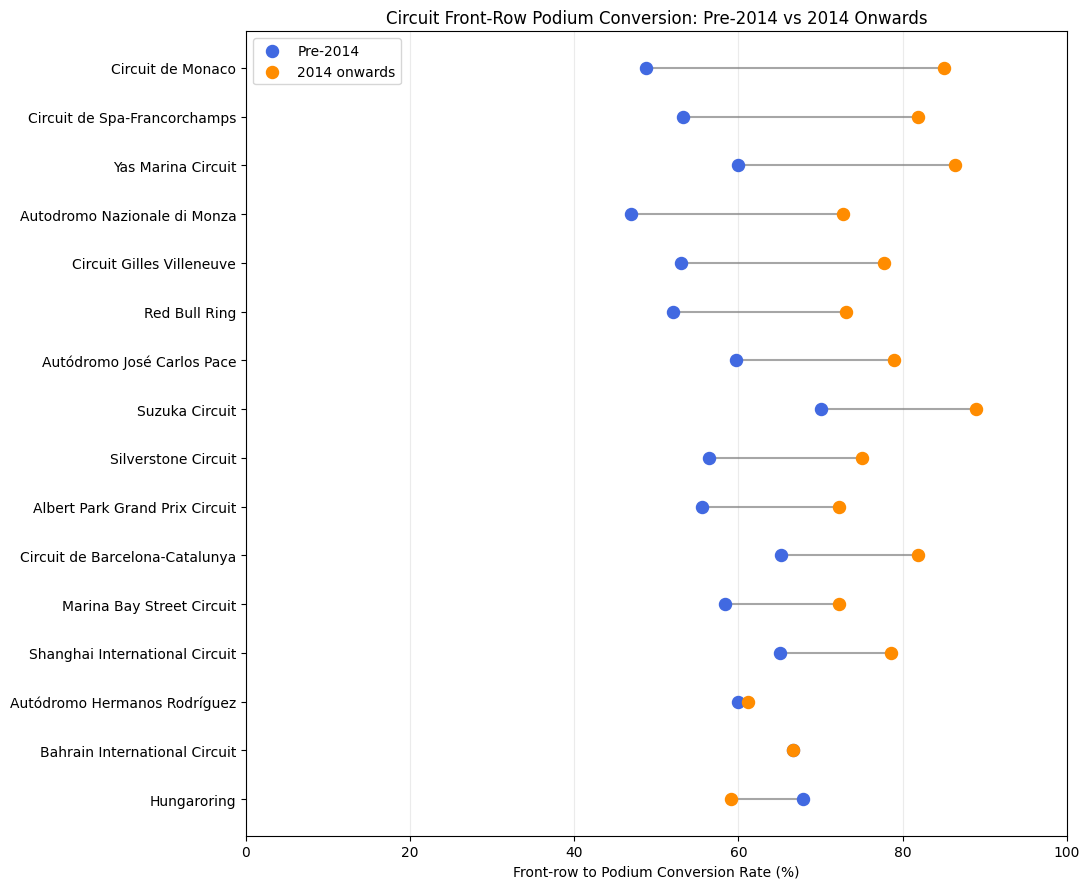

In [64]:


# Sort circuits by the change in conversion rate
plot_df = era_comparison.sort_values('change_pp').copy()

fig, ax = plt.subplots(figsize=(11, 9))

y = np.arange(len(plot_df))

# Plot the conversion rates from both eras
ax.scatter(
    plot_df['Pre-2014'],
    y,
    color='royalblue',
    s=75,
    label='Pre-2014',
    zorder=3
)

ax.scatter(
    plot_df['2014 onwards'],
    y,
    color='darkorange',
    s=75,
    label='2014 onwards',
    zorder=3
)

# Connect each circuit's two observations
for i, (_, row) in enumerate(plot_df.iterrows()):
    ax.plot(
        [row['Pre-2014'], row['2014 onwards']],
        [i, i],
        color='gray',
        linewidth=1.5,
        alpha=0.7
    )

ax.set_yticks(y)
ax.set_yticklabels(
    plot_df.index.get_level_values('circuit_name')
)

ax.set_xlabel('Front-row to Podium Conversion Rate (%)')
ax.set_title(
    'Circuit Front-Row Podium Conversion: Pre-2014 vs 2014 Onwards'
)

ax.set_xlim(0, 100)
ax.grid(axis='x', alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

In [65]:


# Keep only records with known qualifying positions
qualifying_analysis = q1_df.dropna(
    subset=['qualifying_position']
).copy()

# Exclude grid = 0 because it does not represent
# an assigned starting-grid position
qualifying_analysis = qualifying_analysis[
    qualifying_analysis['grid'] > 0
].copy()

# Compare qualifying position and actual grid position
qualifying_analysis['position_changed'] = (
    qualifying_analysis['qualifying_position']
    != qualifying_analysis['grid']
)

print(
    "Drivers with qualifying and valid grid data:",
    len(qualifying_analysis)
)

print(
    "\nDrivers whose qualifying and grid positions differ:",
    qualifying_analysis['position_changed'].sum()
)

print(
    "\nPercentage with different positions:",
    round(
        qualifying_analysis['position_changed'].mean() * 100,
        2
    ),
    "%"
)

# Identify front-row qualifiers and front-row starters
qualifying_analysis['qualified_front_row'] = (
    qualifying_analysis['qualifying_position'].isin([1, 2])
)

qualifying_analysis['started_front_row'] = (
    qualifying_analysis['grid'].isin([1, 2])
)

# Compare qualifying front row vs actual starting front row
print("\nFront-row qualifying vs starting comparison:")

display(
    pd.crosstab(
        qualifying_analysis['qualified_front_row'],
        qualifying_analysis['started_front_row'],
        rownames=['Qualified front row'],
        colnames=['Started front row']
    )
)

# Compare podium conversion rates
comparison = pd.DataFrame({
    'Definition': [
        'Qualified in top 2',
        'Started in grid top 2'
    ],
    'Total drivers': [
        qualifying_analysis['qualified_front_row'].sum(),
        qualifying_analysis['started_front_row'].sum()
    ],
    'Podium finishes': [
        qualifying_analysis.loc[
            qualifying_analysis['qualified_front_row'],
            'podium'
        ].sum(),
        qualifying_analysis.loc[
            qualifying_analysis['started_front_row'],
            'podium'
        ].sum()
    ]
})

# Calculate conversion rates
comparison['Conversion rate (%)'] = (
    comparison['Podium finishes']
    / comparison['Total drivers']
    * 100
)

# Display final comparison
print("\nQualifying vs Grid Podium Conversion Rates:")
display(comparison.round(2))

Drivers with qualifying and valid grid data: 10407

Drivers whose qualifying and grid positions differ: 2422

Percentage with different positions: 23.27 %

Front-row qualifying vs starting comparison:


Started front row,False,True
Qualified front row,,
False,9385,36
True,36,950



Qualifying vs Grid Podium Conversion Rates:


,Definition,Total drivers,Podium finishes,Conversion rate (%)
0,Qualified in top 2,986,680,68.97
1,Started in grid top 2,986,692,70.18


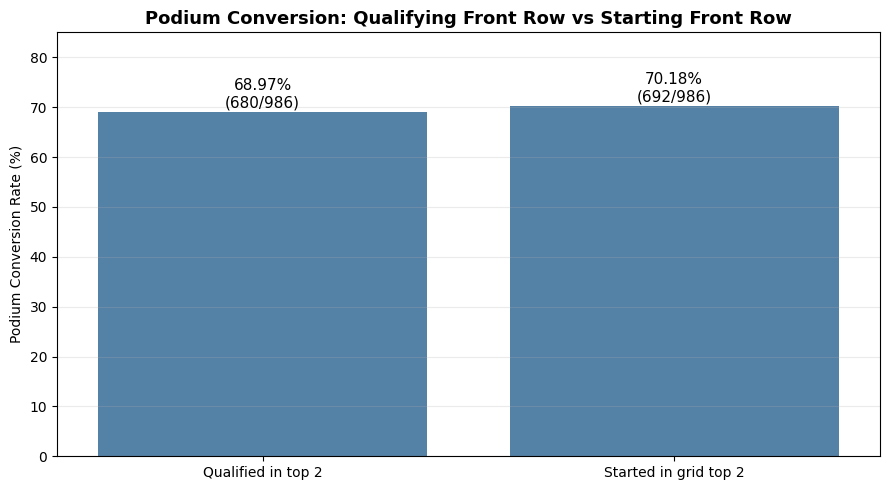

In [66]:


fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=comparison,
    x='Definition',
    y='Conversion rate (%)',
    color='steelblue',
    ax=ax
)

for i, row in comparison.iterrows():
    ax.text(
        i,
        row['Conversion rate (%)'] + 1,
        f"{row['Conversion rate (%)']:.2f}%\n"
        f"({row['Podium finishes']}/{row['Total drivers']})",
        ha='center',
        fontsize=11
    )

ax.set_title(
    'Podium Conversion: Qualifying Front Row vs Starting Front Row',
    fontsize=13,
    fontweight='bold'
)

ax.set_xlabel('')
ax.set_ylabel('Podium Conversion Rate (%)')
ax.set_ylim(0, 85)
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

### Question 1: Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

**Methodology**

We analyzed front-row podium conversion rates using multi-hop joins between `results`, `races`, `circuits`, and `qualifying`. A front-row start was defined as an actual starting-grid position of 1 or 2, while a podium finish was defined as `positionOrder <= 3`.

The analysis compared two periods: before 2014 and from 2014 onward, corresponding to the introduction of the hybrid power-unit era. For the main circuit rankings, we required at least 10 front-row starts per circuit within each period to reduce the influence of very small samples.

**Results**

Before 2014, Circuit de Nevers Magny-Cours had the highest front-row podium conversion rate among eligible circuits, at **80.56% (29/36)**, followed by Istanbul Park at 78.57% (11/14).

From 2014 onward, Suzuka Circuit ranked first with **88.89% (16/18)**, followed by Yas Marina Circuit at 86.36% (19/22) and Circuit de Monaco at 85.00% (17/20).

When comparing the 16 circuits meeting the minimum sample-size threshold in both periods, several changes were observed:

- Monaco increased from 48.76% to 85.00%, a rise of 36.24 percentage points.
- Spa-Francorchamps increased from 53.26% to 81.82%, a rise of 28.56 percentage points.
- Yas Marina increased from 60.00% to 86.36%, a rise of 26.36 percentage points.
- Suzuka increased from 70.00% to 88.89%, remaining first among the 16 common circuits.
- Hungaroring decreased from 67.86% to 59.09%, a decline of 8.77 percentage points.

These findings show that front-row podium conversion rates and circuit rankings differed between the two periods.

**Qualifying Position vs. Starting Grid**

We also compared qualifying positions against actual starting-grid positions using 10,407 records containing both values and a valid grid position.

Of these, 2,422 records (23.27%) had different qualifying and grid positions. Furthermore, 36 drivers qualified in the top two but did not start on the front row, while 36 started on the front row despite qualifying outside the top two.

Drivers qualifying in the top two achieved a podium conversion rate of **68.97% (680/986)**, compared with **70.18% (692/986)** for actual front-row starters.

This difference highlights why qualifying position and starting-grid position should be treated as separate variables.

**Limitations**

Qualifying information was missing for 16,174 of the 26,668 driver–race records, limiting the historical qualifying comparison. Additionally, some circuits had relatively few observations, and the minimum-start threshold does not eliminate sampling uncertainty. Changes between the two eras are descriptive associations and cannot be attributed solely to the introduction of hybrid power units.

**Conclusion**

Front-row podium conversion rates varied considerably across circuits and between eras. Magny-Cours led the eligible pre-2014 circuits, while Suzuka led from 2014 onward. Comparing common circuits showed substantial changes, particularly at Monaco and Spa-Francorchamps. Actual starting-grid position also differed meaningfully from qualifying position, supporting the need to distinguish these variables in Formula 1 analysis.

In [67]:
# Inspect relevant columns
drivers_df = cleaned_datasets['drivers']
circuits_df = cleaned_datasets['circuits']

print("DRIVERS TABLE")
print("Shape:", drivers_df.shape)
print("Columns:", drivers_df.columns.tolist())

display(
    drivers_df[
        ['driverId', 'forename', 'surname', 'nationality']
    ].head(10)
)

print("\nUnique driver nationalities:")
print(sorted(drivers_df['nationality'].dropna().unique()))

print("\nCIRCUITS TABLE")
print("Shape:", circuits_df.shape)

display(
    circuits_df[
        ['circuitId', 'name', 'country']
    ].head(10)
)

print("\nUnique circuit countries:")
print(sorted(circuits_df['country'].dropna().unique()))

DRIVERS TABLE
Shape: (861, 9)
Columns: ['driverId', 'driverRef', 'number', 'code', 'forename', 'surname', 'dob', 'nationality', 'url']


,driverId,forename,surname,nationality
0,1,Lewis,Hamilton,British
1,2,Nick,Heidfeld,German
2,3,Nico,Rosberg,German
3,4,Fernando,Alonso,Spanish
4,5,Heikki,Kovalainen,Finnish
5,6,Kazuki,Nakajima,Japanese
6,7,Sébastien,Bourdais,French
7,8,Kimi,Räikkönen,Finnish
8,9,Robert,Kubica,Polish
9,10,Timo,Glock,German



Unique driver nationalities:
['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']

CIRCUITS TABLE
Shape: (77, 9)


,circuitId,name,country
0,1,Albert Park Grand Prix Circuit,Australia
1,2,Sepang International Circuit,Malaysia
2,3,Bahrain International Circuit,Bahrain
3,4,Circuit de Barcelona-Catalunya,Spain
4,5,Istanbul Park,Turkey
5,6,Circuit de Monaco,Monaco
6,7,Circuit Gilles Villeneuve,Canada
7,8,Circuit de Nevers Magny-Cours,France
8,9,Silverstone Circuit,UK
9,10,Hockenheimring,Germany



Unique circuit countries:
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']


In [68]:
# Map driver nationality to circuit country

nationality_to_country = {
    'American': 'USA',
    'American-Italian': 'USA',
    'Argentine': 'Argentina',
    'Argentine-Italian': 'Argentina',
    'Argentinian': 'Argentina',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Brazilian': 'Brazil',
    'British': 'UK',
    'Canadian': 'Canada',
    'Chilean': 'Chile',
    'Chinese': 'China',
    'Colombian': 'Colombia',
    'Czech': 'Czechia',
    'Danish': 'Denmark',
    'Dutch': 'Netherlands',
    'East German': 'Germany',
    'Finnish': 'Finland',
    'French': 'France',
    'German': 'Germany',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Indonesian': 'Indonesia',
    'Irish': 'Ireland',
    'Italian': 'Italy',
    'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein',
    'Malaysian': 'Malaysia',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand',
    'Polish': 'Poland',
    'Portuguese': 'Portugal',
    'Rhodesian': 'Rhodesia',
    'Russian': 'Russia',
    'South African': 'South Africa',
    'Spanish': 'Spain',
    'Swedish': 'Sweden',
    'Swiss': 'Switzerland',
    'Thai': 'Thailand',
    'Uruguayan': 'Uruguay',
    'Venezuelan': 'Venezuela'
}

# Check if any nationality is missing from the mapping
unmapped = set(
    cleaned_datasets['drivers']['nationality'].dropna().unique()
) - set(nationality_to_country.keys())

print("Unmapped nationalities:", unmapped)

Unmapped nationalities: {'Argentinian '}


In [69]:
# Create a clean copy of the drivers table
drivers_q2 = cleaned_datasets['drivers'].copy()

# Remove leading and trailing whitespace
drivers_q2['nationality'] = (
    drivers_q2['nationality']
    .astype('string')
    .str.strip()
)

# Map nationalities to countries
drivers_q2['home_country'] = (
    drivers_q2['nationality']
    .map(nationality_to_country)
)

# Verify the mapping
unmapped = drivers_q2.loc[
    drivers_q2['home_country'].isna(),
    'nationality'
].dropna().unique()

print("Unmapped nationalities:", unmapped)

print("\nSample mapping:")
display(
    drivers_q2[
        ['forename', 'surname', 'nationality', 'home_country']
    ].head(10)
)

Unmapped nationalities: <StringArray>
[]
Length: 0, dtype: string

Sample mapping:


,forename,surname,nationality,home_country
0,Lewis,Hamilton,British,UK
1,Nick,Heidfeld,German,Germany
2,Nico,Rosberg,German,Germany
3,Fernando,Alonso,Spanish,Spain
4,Heikki,Kovalainen,Finnish,Finland
5,Kazuki,Nakajima,Japanese,Japan
6,Sébastien,Bourdais,French,France
7,Kimi,Räikkönen,Finnish,Finland
8,Robert,Kubica,Polish,Poland
9,Timo,Glock,German,Germany


In [70]:
# Select required columns from each table
results_q2 = cleaned_datasets['results'][
    ['raceId', 'driverId', 'grid', 'positionOrder']
].copy()

races_q2 = cleaned_datasets['races'][
    ['raceId', 'year', 'circuitId']
].copy()

circuits_q2 = cleaned_datasets['circuits'][
    ['circuitId', 'country']
].copy()

drivers_info_q2 = drivers_q2[
    ['driverId', 'nationality', 'home_country']
].copy()

# Rename circuit country to avoid confusion
circuits_q2 = circuits_q2.rename(
    columns={'country': 'race_country'}
)

# Multi-hop joins
q2_df = (
    results_q2
    .merge(
        races_q2,
        on='raceId',
        how='left',
        validate='many_to_one'
    )
    .merge(
        circuits_q2,
        on='circuitId',
        how='left',
        validate='many_to_one'
    )
    .merge(
        drivers_info_q2,
        on='driverId',
        how='left',
        validate='many_to_one'
    )
)

# Create home-race indicator
q2_df['is_home_race'] = (
    q2_df['home_country'] == q2_df['race_country']
)

# Create podium indicator
q2_df['podium'] = q2_df['positionOrder'] <= 3

# Display results
print("Final dataset shape:", q2_df.shape)

print("\nMissing values:")
print(q2_df.isna().sum())

print("\nDuplicate driver-race pairs:")
print(q2_df.duplicated(['raceId', 'driverId']).sum())

print("\nHome vs away race counts:")
print(q2_df['is_home_race'].value_counts(dropna=False))

display(q2_df.head(10))

Final dataset shape: (26668, 11)

Missing values:
raceId           0
driverId         0
grid             0
positionOrder    0
year             0
circuitId        0
race_country     0
nationality      0
home_country     0
is_home_race     0
podium           0
dtype: int64

Duplicate driver-race pairs:
0

Home vs away race counts:
is_home_race
False    24178
True      2490
Name: count, dtype: int64


,raceId,driverId,grid,positionOrder,year,circuitId,race_country,nationality,home_country,is_home_race,podium
0,1,1,18,20,2009,1,Australia,British,UK,False,False
1,1,2,9,10,2009,1,Australia,German,Germany,False,False
2,1,3,5,6,2009,1,Australia,German,Germany,False,False
3,1,4,10,5,2009,1,Australia,Spanish,Spain,False,False
4,1,5,12,19,2009,1,Australia,Finnish,Finland,False,False
5,1,6,11,18,2009,1,Australia,Japanese,Japan,False,False
6,1,7,17,8,2009,1,Australia,French,France,False,False
7,1,8,7,15,2009,1,Australia,Finnish,Finland,False,False
8,1,9,4,14,2009,1,Australia,Polish,Poland,False,False
9,1,10,19,4,2009,1,Australia,German,Germany,False,False


In [71]:
# Keep drivers with valid assigned grid positions
# grid = 0 represents no assigned starting position
q2_valid = q2_df[q2_df['grid'] > 0].copy()

# Calculate overall podium rates for home and away drivers
home_away_summary = (
    q2_valid
    .groupby('is_home_race')
    .agg(
        race_entries=('podium', 'size'),
        podium_finishes=('podium', 'sum'),
        average_grid=('grid', 'mean')
    )
    .reset_index()
)

# Calculate podium percentage
home_away_summary['podium_rate'] = (
    home_away_summary['podium_finishes']
    / home_away_summary['race_entries']
    * 100
)

# Replace True/False with readable labels
home_away_summary['race_type'] = (
    home_away_summary['is_home_race']
    .map({True: 'Home', False: 'Away'})
)

display(
    home_away_summary[
        [
            'race_type',
            'race_entries',
            'podium_finishes',
            'average_grid',
            'podium_rate'
        ]
    ].round(2)
)

,race_type,race_entries,podium_finishes,average_grid,podium_rate
0,Away,22711,3118,11.70,13.73
1,Home,2322,260,13.34,11.20


In [72]:


# Create grid position groups
q2_valid['grid_group'] = pd.cut(
    q2_valid['grid'],
    bins=[0, 3, 10, 15, np.inf],
    labels=[
        'Front (1-3)',
        'Upper midfield (4-10)',
        'Lower midfield (11-15)',
        'Back (16+)'
    ]
)

# Calculate home vs away podium rates within each grid group
grid_comparison = (
    q2_valid
    .groupby(
        ['grid_group', 'is_home_race'],
        observed=True
    )
    .agg(
        race_entries=('podium', 'size'),
        podium_finishes=('podium', 'sum')
    )
    .reset_index()
)

# Calculate podium rates
grid_comparison['podium_rate'] = (
    grid_comparison['podium_finishes']
    / grid_comparison['race_entries']
    * 100
)

# Add readable home/away labels
grid_comparison['race_type'] = (
    grid_comparison['is_home_race']
    .map({True: 'Home', False: 'Away'})
)

print("Home vs Away Podium Rates by Grid Group:")

display(
    grid_comparison[
        [
            'grid_group',
            'race_type',
            'race_entries',
            'podium_finishes',
            'podium_rate'
        ]
    ].round(2)
)

Home vs Away Podium Rates by Grid Group:


,grid_group,race_type,race_entries,podium_finishes,podium_rate
0,Front (1-3),Away,3118,1725,55.32
1,Front (1-3),Home,267,142,53.18
2,Upper midfield (4-10),Away,7232,1189,16.44
3,Upper midfield (4-10),Home,651,96,14.75
4,Lower midfield (11-15),Away,5124,151,2.95
5,Lower midfield (11-15),Home,471,15,3.18
6,Back (16+),Away,7237,53,0.73
7,Back (16+),Home,933,7,0.75


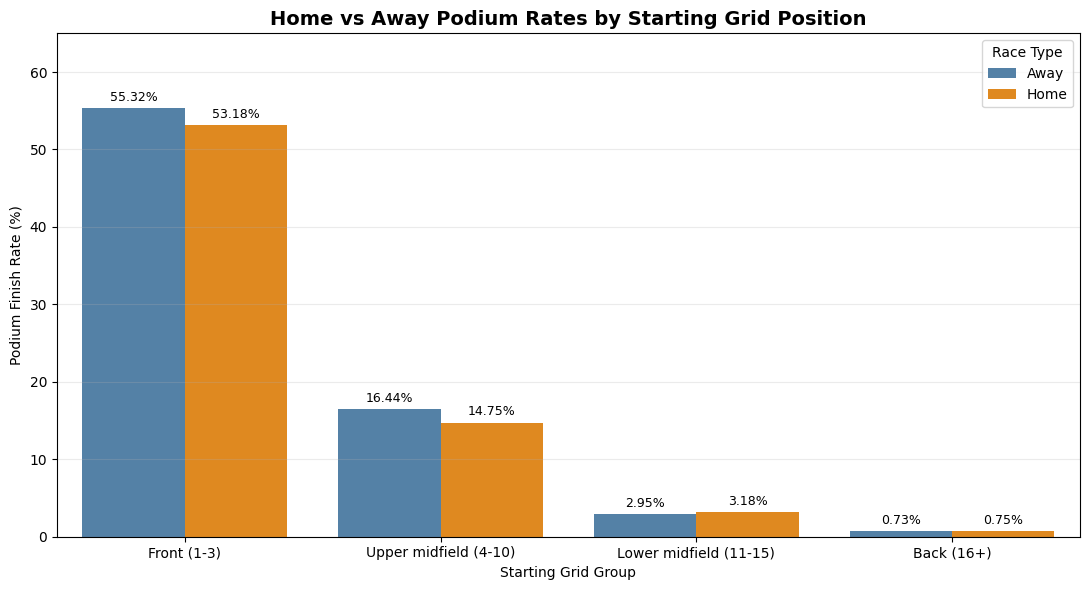

In [73]:


plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=grid_comparison,
    x='grid_group',
    y='podium_rate',
    hue='race_type',
    hue_order=['Away', 'Home'],
    palette=['steelblue', 'darkorange']
)

# Add percentage labels above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=3,
        fontsize=9
    )

plt.title(
    'Home vs Away Podium Rates by Starting Grid Position',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Starting Grid Group')
plt.ylabel('Podium Finish Rate (%)')
plt.ylim(0, 65)
plt.legend(title='Race Type')
plt.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

In [74]:
# Calculate podium rates for each exact grid position
grid_rates = (
    q2_valid
    .groupby(['grid', 'is_home_race'])
    .agg(
        entries=('podium', 'size'),
        podiums=('podium', 'sum')
    )
    .reset_index()
)

grid_rates['podium_rate'] = (
    grid_rates['podiums'] / grid_rates['entries']
)

# Pivot to compare home and away at each grid position
grid_pivot = grid_rates.pivot(
    index='grid',
    columns='is_home_race',
    values='podium_rate'
)

# Keep grid positions represented in BOTH groups
common_grids = grid_pivot.dropna().copy()

# Calculate common weights from the pooled population
grid_weights = (
    q2_valid[
        q2_valid['grid'].isin(common_grids.index)
    ]
    .groupby('grid')
    .size()
)

grid_weights = grid_weights / grid_weights.sum()

# Compute standardized podium rates
standardized_away = (
    common_grids[False] * grid_weights
).sum() * 100

standardized_home = (
    common_grids[True] * grid_weights
).sum() * 100

# Calculate adjusted difference in percentage points
adjusted_difference = standardized_home - standardized_away

standardized_summary = pd.DataFrame({
    'Race Type': ['Away', 'Home'],
    'Standardized Podium Rate (%)': [
        standardized_away,
        standardized_home
    ]
})

print("Number of common grid positions:", len(common_grids))

print("\nGrid-standardized podium rates:")
display(standardized_summary.round(2))

print(
    f"\nHome - Away difference: "
    f"{adjusted_difference:+.2f} percentage points"
)

Number of common grid positions: 32

Grid-standardized podium rates:


,Race Type,Standardized Podium Rate (%)
0,Away,13.55
1,Home,12.95



Home - Away difference: -0.60 percentage points


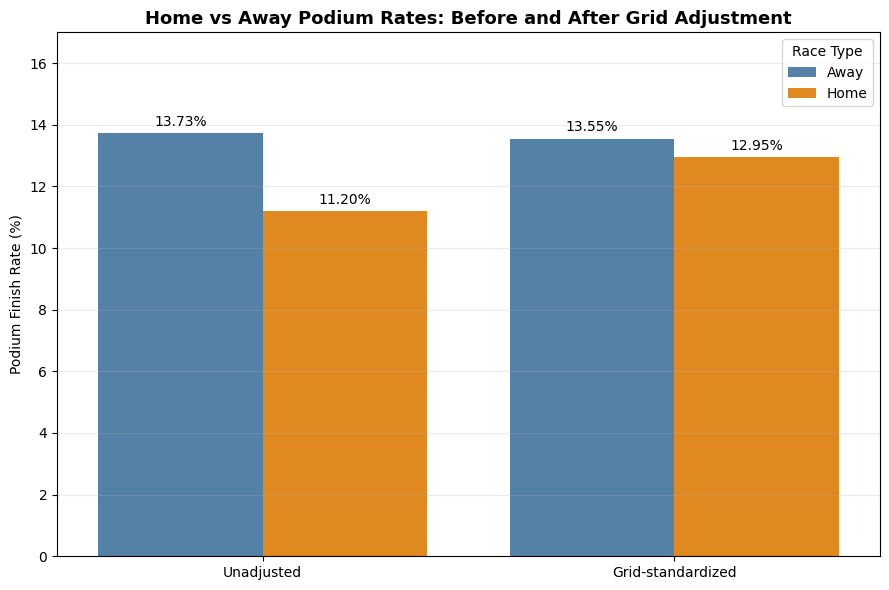

In [75]:


# Prepare unadjusted results
unadjusted = home_away_summary[
    ['race_type', 'podium_rate']
].copy()

unadjusted['Comparison'] = 'Unadjusted'

# Prepare grid-standardized results
adjusted = standardized_summary.rename(
    columns={
        'Race Type': 'race_type',
        'Standardized Podium Rate (%)': 'podium_rate'
    }
).copy()

adjusted['Comparison'] = 'Grid-standardized'

# Combine both results
plot_df = pd.concat(
    [unadjusted, adjusted],
    ignore_index=True
)

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    data=plot_df,
    x='Comparison',
    y='podium_rate',
    hue='race_type',
    order=['Unadjusted', 'Grid-standardized'],
    hue_order=['Away', 'Home'],
    palette=['steelblue', 'darkorange'],
    ax=ax
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=3,
        fontsize=10
    )

ax.set_title(
    'Home vs Away Podium Rates: Before and After Grid Adjustment',
    fontsize=13,
    fontweight='bold'
)

ax.set_xlabel('')
ax.set_ylabel('Podium Finish Rate (%)')
ax.set_ylim(0, 17)
ax.legend(title='Race Type')
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

### Question 2: Do drivers achieve podium finishes more often when racing in their home country after controlling for starting position?

**Methodology**

To investigate the relationship between racing in a driver's home country and achieving a podium finish, we combined four datasets: `results`, `races`, `circuits`, and `drivers`.

The analysis used one observation per driver–race combination. Driver nationalities were mapped to their corresponding countries and compared against circuit countries to determine whether each race was a home or away race. Records with `grid = 0` were excluded because they did not represent valid assigned starting-grid positions.

A podium finish was defined as `positionOrder <= 3`.

We first compared unadjusted podium rates between home and away races. We then controlled for starting position using four grid categories: positions 1–3, 4–10, 11–15, and 16+.

Finally, we performed direct standardization using exact starting-grid positions. We calculated the podium rate separately for home and away drivers at each grid position and applied common weights based on the pooled grid distribution.

**Results**

The unadjusted analysis included 25,033 driver–race observations:

| Race type | Entries | Podium finishes | Average grid | Podium rate |
|---|---:|---:|---:|---:|
| Away | 22,711 | 3,118 | 11.70 | 13.73% |
| Home | 2,322 | 260 | 13.34 | 11.20% |

Before adjustment, home drivers had a podium rate **2.53 percentage points lower** than away drivers. However, home drivers also started farther back on average, suggesting that differences in starting position could partly explain this result.

After grouping drivers by starting position, the home-away differences became smaller and varied between groups.

| Starting grid | Away podium rate | Home podium rate |
|---|---:|---:|
| Positions 1–3 | 55.32% | 53.18% |
| Positions 4–10 | 16.44% | 14.75% |
| Positions 11–15 | 2.95% | 3.18% |
| Positions 16+ | 0.73% | 0.75% |

Drivers starting from the first three grid positions had substantially higher podium rates than drivers starting farther back, regardless of whether they were competing at home or away.

**Grid-Standardized Comparison**

To account more precisely for differences in starting positions, we standardized home and away podium rates using 32 grid positions represented in both groups.

| Race type | Grid-standardized podium rate |
|---|---:|
| Away | 13.55% |
| Home | 12.95% |

After standardization, the home-away difference decreased from **−2.53 to −0.60 percentage points**.

This suggests that differences in starting-grid positions account for a substantial part of the observed unadjusted gap.

**Limitations**

Driver nationality was used as a proxy for home country, which may not fully reflect drivers with multiple nationalities or historical nationality changes.

Although the standardization adjusted for starting-grid position, it did not control for driver skill, constructor performance, or differences between racing eras. Some exact grid positions also contained relatively few home-race observations.

Furthermore, the results are descriptive and do not establish a causal relationship or statistical significance.

**Conclusion**

The analysis did not identify a consistent home-country podium advantage. Home drivers initially showed lower podium rates than away drivers, but the difference became substantially smaller after controlling for exact starting-grid positions.

The findings indicate that starting position is an important factor when comparing home and away podium performance. The remaining difference is small and should not be interpreted as evidence that racing at home directly affects performance.

In [76]:


# Configure Pandas to display all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

# Inspect retirement statuses
status_df = cleaned_datasets['status'].copy()

print("Status table shape:", status_df.shape)
print("Status columns:", status_df.columns.tolist())

# Display all 139 status descriptions
print("\nALL STATUS DESCRIPTIONS:")
display(
    status_df
    .sort_values('statusId')
    .reset_index(drop=True)
)

# Examine status frequencies during 2014–2024
results_q3 = cleaned_datasets['results']
races_q3 = cleaned_datasets['races']

status_frequency = (
    results_q3[['raceId', 'statusId']]
    .merge(
        races_q3[['raceId', 'year']],
        on='raceId',
        how='inner'
    )
    .query('2014 <= year <= 2024')
    .merge(
        status_df,
        on='statusId',
        how='left'
    )
    .groupby(['statusId', 'status'])
    .size()
    .reset_index(name='count')
    .sort_values('count', ascending=False)
    .reset_index(drop=True)
)

print("\nSTATUS FREQUENCIES (2014–2024):")
print("Number of unique statuses:", len(status_frequency))

# Display all statuses and their frequencies
display(status_frequency)

# Also print the full list without truncation
print("\nCOMPLETE STATUS FREQUENCY LIST:")
print(
    status_frequency[
        ['statusId', 'status', 'count']
    ].to_string(index=False)
)

Status table shape: (139, 2)
Status columns: ['statusId', 'status']

ALL STATUS DESCRIPTIONS:


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine
5,6,Gearbox
6,7,Transmission
7,8,Clutch
8,9,Hydraulics
9,10,Electrical



STATUS FREQUENCIES (2014–2024):
Number of unique statuses: 66


,statusId,status,count
0,1,Finished,2403
1,11,+1 Lap,1178
2,12,+2 Laps,208
3,4,Collision,150
4,3,Accident,85
5,5,Engine,81
6,130,Collision damage,59
7,31,Retired,50
8,23,Brakes,49
9,131,Power Unit,42



COMPLETE STATUS FREQUENCY LIST:
 statusId           status  count
        1         Finished   2403
       11           +1 Lap   1178
       12          +2 Laps    208
        4        Collision    150
        3         Accident     85
        5           Engine     81
      130 Collision damage     59
       31          Retired     50
       23           Brakes     49
      131       Power Unit     42
        6          Gearbox     42
       22       Suspension     25
       13          +3 Laps     24
        9       Hydraulics     15
       10       Electrical     14
       54         Withdrew     14
       75       Power loss     13
        2     Disqualified     11
       20         Spun off     11
       36            Wheel     11
       44         Oil leak     10
       25      Overheating      8
       29         Puncture      7
       34   Water pressure      7
       26       Mechanical      7
       14          +4 Laps      6
      101            Turbo      6
       84      

In [77]:
# Display every status used during 2014–2024
pd.set_option('display.max_rows', 100)

display(
    status_frequency[
        ['statusId', 'status', 'count']
    ].sort_values('statusId').reset_index(drop=True)
)

,statusId,status,count
0,1,Finished,2403
1,2,Disqualified,11
2,3,Accident,85
3,4,Collision,150
4,5,Engine,81
5,6,Gearbox,42
6,7,Transmission,3
7,8,Clutch,2
8,9,Hydraulics,15
9,10,Electrical,14


In [78]:
# Question 3: Mechanical-failure classification

# Explicit component or mechanical-system failures
mechanical_statuses = {
    'Engine',
    'Gearbox',
    'Transmission',
    'Clutch',
    'Hydraulics',
    'Electrical',
    'Radiator',
    'Suspension',
    'Brakes',
    'Differential',
    'Overheating',
    'Mechanical',
    'Driveshaft',
    'Steering',
    'Electronics',
    'Exhaust',
    'Oil leak',
    'Water leak',
    'Fuel pump',
    'Oil pressure',
    'Wheel nut',
    'Fuel system',
    'Drivetrain',
    'Battery',
    'Fuel leak',
    'Turbo',
    'Water pump',
    'Spark plugs',
    'Power Unit',
    'ERS',
    'Brake duct',
    'Cooling system',
    'Fuel pressure',
    'Water pressure',
    'Throttle'
}

# Broader potentially mechanical categories
ambiguous_mechanical_statuses = {
    'Technical',
    'Vibrations',
    'Power loss',
    'Rear wing'
}

# Broad classification for sensitivity analysis
broad_mechanical_statuses = (
    mechanical_statuses | ambiguous_mechanical_statuses
)

# Verify descriptions against the actual status table
available_statuses = set(status_df['status'])

print(
    "Unknown strict statuses:",
    mechanical_statuses - available_statuses
)

print(
    "Unknown broad statuses:",
    broad_mechanical_statuses - available_statuses
)

# Display the included status categories
classification_review = status_frequency.copy()

classification_review['classification'] = (
    classification_review['status'].apply(
        lambda s:
        'Primary mechanical'
        if s in mechanical_statuses
        else 'Ambiguous / sensitivity'
        if s in ambiguous_mechanical_statuses
        else 'Excluded'
    )
)

display(
    classification_review[
        ['statusId', 'status', 'count', 'classification']
    ].sort_values('statusId')
)

Unknown strict statuses: set()
Unknown broad statuses: set()


,statusId,status,count,classification
0,1,Finished,2403,Excluded
17,2,Disqualified,11,Excluded
4,3,Accident,85,Excluded
3,4,Collision,150,Excluded
5,5,Engine,81,Primary mechanical
10,6,Gearbox,42,Primary mechanical
36,7,Transmission,3,Primary mechanical
41,8,Clutch,2,Primary mechanical
13,9,Hydraulics,15,Primary mechanical
14,10,Electrical,14,Primary mechanical


In [79]:


# Select relevant columns
results_q3 = cleaned_datasets['results'][
    ['raceId', 'driverId', 'constructorId',
     'grid', 'laps', 'statusId']
].copy()

races_q3 = cleaned_datasets['races'][
    ['raceId', 'year']
].copy()

constructors_q3 = cleaned_datasets['constructors'][
    ['constructorId', 'name']
].rename(columns={'name': 'constructor_name'}).copy()

status_q3 = cleaned_datasets['status'][
    ['statusId', 'status']
].copy()

# Four-table multi-hop join
q3_df = (
    results_q3
    .merge(
        races_q3,
        on='raceId',
        how='left',
        validate='many_to_one'
    )
    .merge(
        constructors_q3,
        on='constructorId',
        how='left',
        validate='many_to_one'
    )
    .merge(
        status_q3,
        on='statusId',
        how='left',
        validate='many_to_one'
    )
)

# Keep the required period
q3_df = q3_df[
    q3_df['year'].between(2014, 2024)
].copy()

# Define the two comparison periods
q3_df['era'] = q3_df['year'].apply(
    lambda year: '2014-2021' if year <= 2021 else '2022-2024'
)

# Mark mechanical failure statuses
q3_df['is_mechanical'] = (
    q3_df['status'].isin(mechanical_statuses)
)

print("Dataset shape:", q3_df.shape)

print("\nMissing values:")
print(q3_df.isna().sum())

print("\nDuplicate driver-race pairs:")
print(q3_df.duplicated(['raceId', 'driverId']).sum())

print("\nMechanical records by era:")
print(q3_df.groupby('era')['is_mechanical'].sum())

# Inspect grid = 0 records
print("\nGrid = 0 status breakdown:")
grid_zero_status = (
    q3_df[q3_df['grid'] == 0]
    .groupby(['statusId', 'status'])
    .agg(
        records=('driverId', 'size'),
        total_laps=('laps', 'sum'),
        max_laps=('laps', 'max')
    )
    .reset_index()
    .sort_values('records', ascending=False)
)

display(grid_zero_status)

print("\nGrid = 0 records:", (q3_df['grid'] == 0).sum())

print(
    "Grid = 0 with laps > 0:",
    ((q3_df['grid'] == 0) & (q3_df['laps'] > 0)).sum()
)

Dataset shape: (4626, 11)

Missing values:
raceId              0
driverId            0
constructorId       0
grid                0
laps                0
statusId            0
year                0
constructor_name    0
status              0
era                 0
is_mechanical       0
dtype: int64

Duplicate driver-race pairs:
0

Mechanical records by era:
era
2014-2021    290
2022-2024     73
Name: is_mechanical, dtype: int64

Grid = 0 status breakdown:


,statusId,status,records,total_laps,max_laps
7,11,+1 Lap,27,1674,71
0,1,Finished,22,1141,78
8,12,+2 Laps,7,413,70
15,130,Collision damage,3,127,66
12,54,Withdrew,3,0,0
1,3,Accident,2,72,38
10,23,Brakes,2,63,63
11,31,Retired,2,50,48
16,131,Power Unit,2,26,25
2,4,Collision,1,54,54



Grid = 0 records: 79
Grid = 0 with laps > 0: 72


In [80]:
# Inspect entries with grid = 0 and zero completed laps
ambiguous_starts = q3_df[
    (q3_df['grid'] == 0) &
    (q3_df['laps'] == 0)
].copy()

print("Ambiguous starting records:", len(ambiguous_starts))

display(
    ambiguous_starts[
        [
            'raceId',
            'driverId',
            'year',
            'constructor_name',
            'grid',
            'laps',
            'statusId',
            'status',
            'is_mechanical'
        ]
    ].sort_values(['year', 'raceId'])
)

Ambiguous starting records: 7


,raceId,driverId,year,constructor_name,grid,laps,statusId,status,is_mechanical
22460,926,822,2015,Williams,0,0,54,Withdrew,False
22482,927,829,2015,Manor Marussia,0,0,69,Fuel system,True
23571,983,8,2017,Ferrari,0,0,84,Battery,True
25166,1065,852,2021,AlphaTauri,0,0,23,Brakes,True
25347,1075,854,2022,Haas F1 Team,0,0,54,Withdrew,False
26038,1113,840,2023,Aston Martin,0,0,54,Withdrew,False
26141,1118,844,2023,Ferrari,0,0,5,Engine,True


In [81]:
# Validate race-start information

position_info = cleaned_datasets['results'][
    ['raceId', 'driverId', 'positionText']
].copy()

q3_df = q3_df.merge(
    position_info,
    on=['raceId', 'driverId'],
    how='left',
    validate='one_to_one'
)

non_start_statuses = {
    'Did not start',
    'Did not qualify',
    'Did not prequalify',
    'Withdrew'
}

q3_df['explicit_non_start'] = (
    q3_df['status'].isin(non_start_statuses)
    | q3_df['positionText'].isin(['W', 'F'])
)

conflicts = q3_df[
    q3_df['explicit_non_start']
    & ((q3_df['grid'] > 0) | (q3_df['laps'] > 0))
]

print("Conflicting starting records:", len(conflicts))

display(
    conflicts[
        ['raceId', 'driverId', 'year',
         'grid', 'laps', 'positionText', 'status']
    ]
)

Conflicting starting records: 25


,raceId,driverId,year,grid,laps,positionText,status
34,901,815,2014,14,0,W,Withdrew
121,905,813,2014,15,0,W,Withdrew
295,913,155,2014,20,0,W,Power Unit
419,926,825,2015,17,0,W,Withdrew
420,926,826,2015,12,0,W,Withdrew
470,929,18,2015,20,0,W,ERS
582,934,831,2015,16,0,W,Gearbox
613,937,807,2015,11,0,W,Power loss
799,948,826,2016,18,0,W,Retired
812,949,20,2016,3,0,W,Engine


In [82]:
# Investigate conflicting race-start records

conflict_summary = (
    conflicts
    .groupby(['era', 'status'], dropna=False)
    .agg(
        records=('driverId', 'size'),
        grid_positive=('grid', lambda x: (x > 0).sum()),
        laps_positive=('laps', lambda x: (x > 0).sum())
    )
    .reset_index()
    .sort_values(['era', 'records'], ascending=[True, False])
)

print("Total conflicting records:", len(conflicts))

print("\nConflicts by status and era:")
display(conflict_summary)

print("\nConflicting records with mechanical statuses:")
display(
    conflicts[
        conflicts['status'].isin(
            broad_mechanical_statuses
        )
    ][
        [
            'year',
            'raceId',
            'driverId',
            'constructor_name',
            'grid',
            'laps',
            'positionText',
            'status'
        ]
    ]
)

print(
    "\nMechanical-status records affected:",
    conflicts['status'].isin(
        mechanical_statuses
    ).sum()
)

Total conflicting records: 25

Conflicts by status and era:


,era,status,records,grid_positive,laps_positive
10,2014-2021,Withdrew,8,8,2
7,2014-2021,Power Unit,3,3,0
0,2014-2021,Driveshaft,1,1,0
1,2014-2021,ERS,1,1,0
2,2014-2021,Engine,1,1,0
3,2014-2021,Exhaust,1,1,0
4,2014-2021,Gearbox,1,1,0
5,2014-2021,Hydraulics,1,1,0
6,2014-2021,Illness,1,1,0
8,2014-2021,Power loss,1,1,0



Conflicting records with mechanical statuses:


,year,raceId,driverId,constructor_name,grid,laps,positionText,status
295,2014,913,155,Caterham,20,0,W,Power Unit
470,2015,929,18,McLaren,20,0,W,ERS
582,2015,934,831,Sauber,16,0,W,Gearbox
613,2015,937,807,Force India,11,0,W,Power loss
812,2016,949,20,Ferrari,3,0,W,Engine
825,2016,949,835,Renault,19,0,W,Hydraulics
1308,2017,972,4,McLaren,15,0,W,Power Unit
2551,2020,1034,807,Racing Point,13,0,W,Power Unit
2617,2020,1037,832,McLaren,7,0,W,Exhaust
2940,2021,1056,844,Ferrari,1,0,W,Driveshaft



Mechanical-status records affected: 11


In [83]:
# Define estimated race starts
q3_df['is_race_start'] = (
    ((q3_df['grid'] > 0) | (q3_df['laps'] > 0))
    & ~q3_df['explicit_non_start']
)

q3_starts = q3_df[q3_df['is_race_start']].copy()

# Apply primary mechanical classification
q3_starts['is_mechanical'] = (
    q3_starts['status'].isin(mechanical_statuses)
)

# Verify uniqueness
assert not q3_starts.duplicated(
    ['raceId', 'driverId']
).any()

# Calculate constructor retirement rates
constructor_retirement = (
    q3_starts
    .groupby(['era', 'constructorId', 'constructor_name'])
    .agg(
        race_starts=('driverId', 'size'),
        mechanical_retirements=('is_mechanical', 'sum')
    )
    .reset_index()
)

constructor_retirement['mechanical_rate'] = (
    constructor_retirement['mechanical_retirements']
    / constructor_retirement['race_starts'] * 100
)

# Calculate overall statistics
overall_retirement = (
    q3_starts
    .groupby('era')
    .agg(
        race_starts=('driverId', 'size'),
        mechanical_retirements=('is_mechanical', 'sum')
    )
    .reset_index()
)

overall_retirement['mechanical_rate'] = (
    overall_retirement['mechanical_retirements']
    / overall_retirement['race_starts'] * 100
)

# Validate totals
for era in overall_retirement['era']:
    group = constructor_retirement[
        constructor_retirement['era'] == era
    ]
    total = overall_retirement[
        overall_retirement['era'] == era
    ].iloc[0]

    assert group['race_starts'].sum() == total['race_starts']
    assert (
        group['mechanical_retirements'].sum()
        == total['mechanical_retirements']
    )

print("Overall retirement statistics:")
display(overall_retirement.round(2))

for era in ['2014-2021', '2022-2024']:
    print(f"\nConstructor rankings: {era}")

    display(
        constructor_retirement[
            constructor_retirement['era'] == era
        ]
        .sort_values('mechanical_rate', ascending=False)
        .round(2)
    )

Overall retirement statistics:


,era,race_starts,mechanical_retirements,mechanical_rate
0,2014-2021,3243,278,8.57
1,2022-2024,1351,70,5.18



Constructor rankings: 2014-2021


,era,constructorId,constructor_name,race_starts,mechanical_retirements,mechanical_rate
12,2014-2021,207,Caterham,33,7,21.21
13,2014-2021,208,Lotus F1,75,12,16.00
3,2014-2021,5,Toro Rosso,242,38,15.70
2,2014-2021,4,Renault,199,25,12.56
0,2014-2021,1,McLaren,315,37,11.75
5,2014-2021,9,Red Bull,318,32,10.06
7,2014-2021,15,Sauber,199,20,10.05
11,2014-2021,206,Marussia,31,3,9.68
17,2014-2021,213,AlphaTauri,77,7,9.09
15,2014-2021,210,Haas F1 Team,240,20,8.33



Constructor rankings: 2022-2024


,era,constructorId,constructor_name,race_starts,mechanical_retirements,mechanical_rate
29,2022-2024,214,Alpine F1 Team,135,14,10.37
24,2022-2024,51,Alfa Romeo,88,9,10.23
28,2022-2024,213,AlphaTauri,88,6,6.82
20,2022-2024,3,Williams,134,7,5.22
21,2022-2024,6,Ferrari,134,6,4.48
26,2022-2024,131,Mercedes,136,6,4.41
30,2022-2024,215,RB F1 Team,48,2,4.17
27,2022-2024,210,Haas F1 Team,135,5,3.70
22,2022-2024,9,Red Bull,136,5,3.68
19,2022-2024,1,McLaren,136,5,3.68


In [84]:
# Sensitivity check for conflicting race-start records

# Current conservative definition
conservative = q3_df[
    q3_df['is_race_start']
].copy()

# Alternative: include records with positive grid or laps
# even if the status indicates a non-start
alternative = q3_df[
    (q3_df['grid'] > 0) | (q3_df['laps'] > 0)
].copy()

def calculate_rates(df):
    return (
        df.assign(
            mechanical=df['status'].isin(mechanical_statuses)
        )
        .groupby('era')
        .agg(
            race_starts=('driverId', 'size'),
            mechanical_retirements=('mechanical', 'sum')
        )
        .assign(
            rate=lambda x:
            x['mechanical_retirements']
            / x['race_starts'] * 100
        )
    )

print("Conservative definition:")
display(calculate_rates(conservative).round(2))

print("\nAlternative definition:")
display(calculate_rates(alternative).round(2))

Conservative definition:


,race_starts,mechanical_retirements,rate
era,,,
2014-2021,3243,278,8.57
2022-2024,1351,70,5.18



Alternative definition:


,race_starts,mechanical_retirements,rate
era,,,
2014-2021,3263,287,8.80
2022-2024,1356,72,5.31


In [85]:
# Compare constructor rankings under both race-start rules

def constructor_rates(df):
    return (
        df.assign(
            mechanical=df['status'].isin(mechanical_statuses)
        )
        .groupby(['era', 'constructorId', 'constructor_name'])
        .agg(
            starts=('driverId', 'size'),
            failures=('mechanical', 'sum')
        )
        .assign(
            rate=lambda x: x['failures'] / x['starts'] * 100
        )
        .reset_index()
    )

for era in ['2014-2021', '2022-2024']:
    print(f"\n{era}")

    for name, dataset in [
        ('Conservative', conservative),
        ('Alternative', alternative)
    ]:
        top = (
            constructor_rates(dataset)
            .query('era == @era')
            .sort_values('rate', ascending=False)
            .head(5)
        )

        print(f"\n{name}:")
        display(
            top[
                ['constructor_name', 'starts', 'failures', 'rate']
            ].round(2)
        )


2014-2021

Conservative:


,constructor_name,starts,failures,rate
12,Caterham,33,7,21.21
13,Lotus F1,75,12,16.00
3,Toro Rosso,242,38,15.70
2,Renault,199,25,12.56
0,McLaren,315,37,11.75



Alternative:


,constructor_name,starts,failures,rate
12,Caterham,34,8,23.53
13,Lotus F1,76,12,15.79
3,Toro Rosso,242,38,15.70
2,Renault,200,26,13.00
0,McLaren,320,40,12.50



2022-2024

Conservative:


,constructor_name,starts,failures,rate
29,Alpine F1 Team,135,14,10.37
24,Alfa Romeo,88,9,10.23
28,AlphaTauri,88,6,6.82
20,Williams,134,7,5.22
21,Ferrari,134,6,4.48



Alternative:


,constructor_name,starts,failures,rate
29,Alpine F1 Team,136,15,11.03
24,Alfa Romeo,88,9,10.23
28,AlphaTauri,88,6,6.82
20,Williams,135,7,5.19
21,Ferrari,135,7,5.19


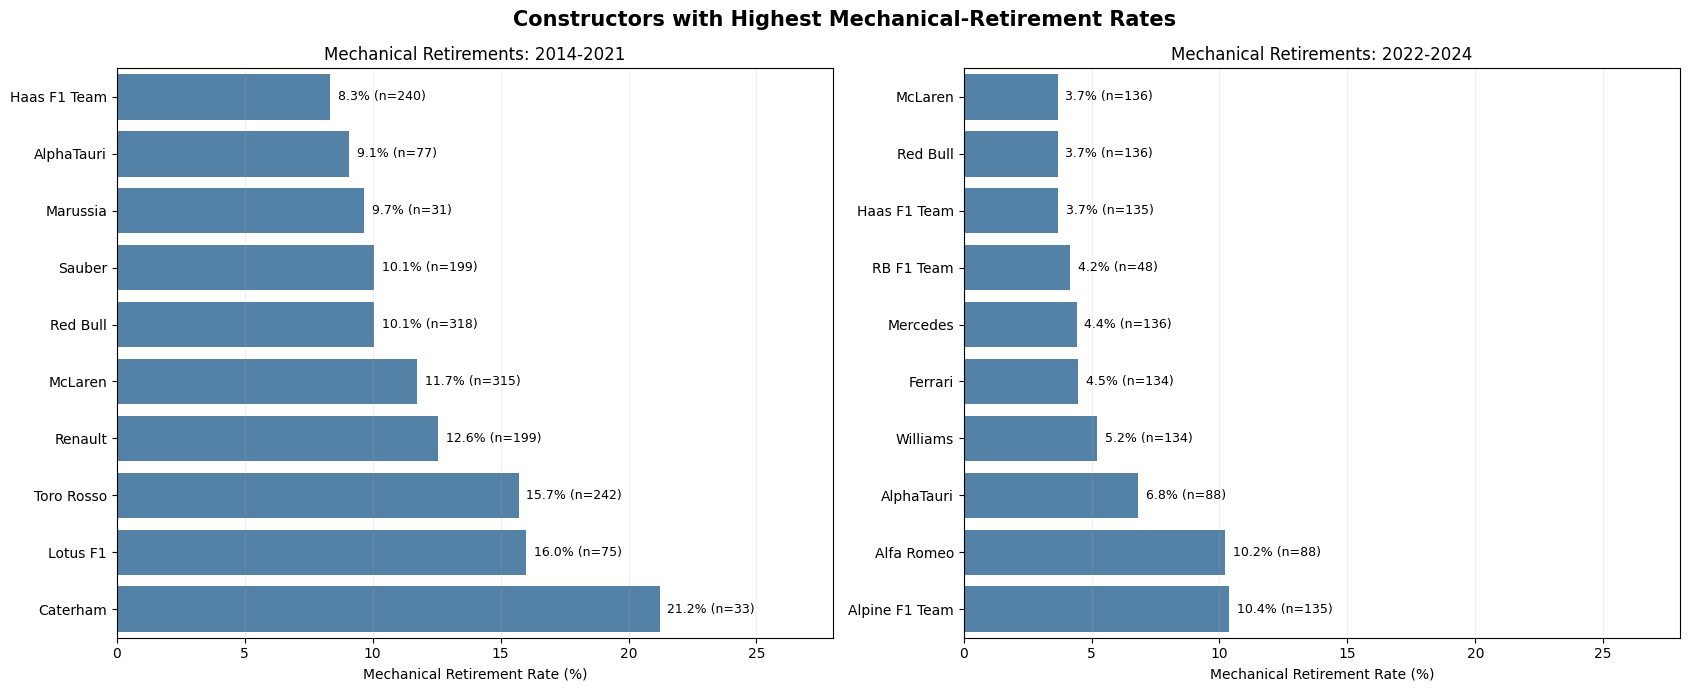

In [86]:


eras = ['2014-2021', '2022-2024']

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

for ax, era in zip(axes, eras):

    top_10 = (
        constructor_retirement[
            constructor_retirement['era'] == era
        ]
        .sort_values(
            'mechanical_rate',
            ascending=False
        )
        .head(10)
        .sort_values('mechanical_rate')
    )

    sns.barplot(
        data=top_10,
        x='mechanical_rate',
        y='constructor_name',
        color='steelblue',
        ax=ax
    )

    for i, (_, row) in enumerate(top_10.iterrows()):
        ax.text(
            row['mechanical_rate'] + 0.3,
            i,
            f"{row['mechanical_rate']:.1f}% "
            f"(n={row['race_starts']})",
            va='center',
            fontsize=9
        )

    ax.set_title(f'Mechanical Retirements: {era}')
    ax.set_xlabel('Mechanical Retirement Rate (%)')
    ax.set_ylabel('')
    ax.set_xlim(0, 28)
    ax.grid(axis='x', alpha=0.2)

plt.suptitle(
    'Constructors with Highest Mechanical-Retirement Rates',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

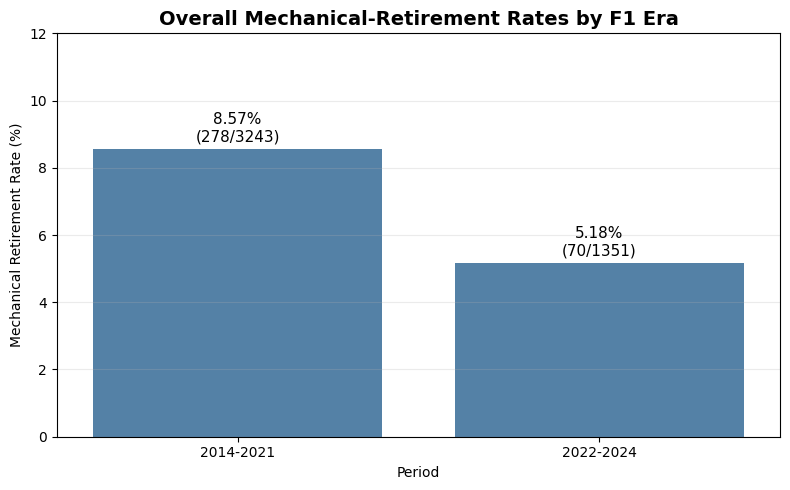

,era,race_starts,mechanical_retirements,mechanical_rate
0,2014-2021,3243,278,8.57
1,2022-2024,1351,70,5.18


In [87]:


# Calculate overall mechanical-retirement rates
overall_retirement = (
    q3_starts
    .groupby('era')
    .agg(
        race_starts=('driverId', 'size'),
        mechanical_retirements=('is_mechanical', 'sum')
    )
    .reset_index()
)

overall_retirement['mechanical_rate'] = (
    overall_retirement['mechanical_retirements']
    / overall_retirement['race_starts']
    * 100
)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=overall_retirement,
    x='era',
    y='mechanical_rate',
    order=['2014-2021', '2022-2024'],
    color='steelblue',
    ax=ax
)

# Add rates and sample sizes above bars
for i, row in overall_retirement.iterrows():
    x = ['2014-2021', '2022-2024'].index(row['era'])

    ax.text(
        x,
        row['mechanical_rate'] + 0.2,
        f"{row['mechanical_rate']:.2f}%\n"
        f"({row['mechanical_retirements']}/"
        f"{row['race_starts']})",
        ha='center',
        fontsize=11
    )

ax.set_title(
    'Overall Mechanical-Retirement Rates by F1 Era',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Period')
ax.set_ylabel('Mechanical Retirement Rate (%)')
ax.set_ylim(0, 12)
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

display(overall_retirement.round(2))

In [88]:
q3_starts['broad_mechanical'] = (
    q3_starts['status'].isin(broad_mechanical_statuses)
)

sensitivity = (
    q3_starts
    .groupby(['era', 'constructorId', 'constructor_name'])
    .agg(
        race_starts=('driverId', 'size'),
        strict_retirements=('is_mechanical', 'sum'),
        broad_retirements=('broad_mechanical', 'sum')
    )
    .reset_index()
)

sensitivity['strict_rate'] = (
    sensitivity['strict_retirements']
    / sensitivity['race_starts'] * 100
)

sensitivity['broad_rate'] = (
    sensitivity['broad_retirements']
    / sensitivity['race_starts'] * 100
)

sensitivity['difference_pp'] = (
    sensitivity['broad_rate']
    - sensitivity['strict_rate']
)

for era in ['2014-2021', '2022-2024']:
    print(f"\nSensitivity analysis: {era}")

    display(
        sensitivity[sensitivity['era'] == era]
        .sort_values('strict_rate', ascending=False)
        .round(2)
    )


Sensitivity analysis: 2014-2021


,era,constructorId,constructor_name,race_starts,strict_retirements,broad_retirements,strict_rate,broad_rate,difference_pp
12,2014-2021,207,Caterham,33,7,7,21.21,21.21,0.00
13,2014-2021,208,Lotus F1,75,12,14,16.00,18.67,2.67
3,2014-2021,5,Toro Rosso,242,38,39,15.70,16.12,0.41
2,2014-2021,4,Renault,199,25,26,12.56,13.07,0.50
0,2014-2021,1,McLaren,315,37,41,11.75,13.02,1.27
5,2014-2021,9,Red Bull,318,32,34,10.06,10.69,0.63
7,2014-2021,15,Sauber,199,20,21,10.05,10.55,0.50
11,2014-2021,206,Marussia,31,3,3,9.68,9.68,0.00
17,2014-2021,213,AlphaTauri,77,7,7,9.09,9.09,0.00
15,2014-2021,210,Haas F1 Team,240,20,20,8.33,8.33,0.00



Sensitivity analysis: 2022-2024


,era,constructorId,constructor_name,race_starts,strict_retirements,broad_retirements,strict_rate,broad_rate,difference_pp
29,2022-2024,214,Alpine F1 Team,135,14,14,10.37,10.37,0.00
24,2022-2024,51,Alfa Romeo,88,9,11,10.23,12.50,2.27
28,2022-2024,213,AlphaTauri,88,6,6,6.82,6.82,0.00
20,2022-2024,3,Williams,134,7,7,5.22,5.22,0.00
21,2022-2024,6,Ferrari,134,6,6,4.48,4.48,0.00
26,2022-2024,131,Mercedes,136,6,6,4.41,4.41,0.00
30,2022-2024,215,RB F1 Team,48,2,2,4.17,4.17,0.00
27,2022-2024,210,Haas F1 Team,135,5,6,3.70,4.44,0.74
22,2022-2024,9,Red Bull,136,5,5,3.68,3.68,0.00
19,2022-2024,1,McLaren,136,5,5,3.68,3.68,0.00


### Question 3: Which constructors have the highest mechanical-retirement rates in 2014–2021 versus 2022–2024?

**Methodology**

We analyzed mechanical-retirement rates using multi-hop joins between four datasets: `results`, `races`, `constructors`, and `status`. The unit of analysis was one driver–race record.

The analysis covered 2014–2024, divided into two periods: 2014–2021 and 2022–2024.

A mechanical retirement was identified using recorded car-component and mechanical-system failure statuses, including engine, gearbox, transmission, hydraulics, brakes, electrical systems, and power-unit failures. Accidents, collisions, regulatory exclusions, and other non-mechanical outcomes were excluded.

To estimate actual race starts, the primary analysis retained observations with a positive starting-grid position or completed laps, while excluding records explicitly identified as non-starts through status descriptions or finishing-position codes.

We identified 25 records with conflicting start information and evaluated the sensitivity of the results to including or excluding them.

For each constructor, the mechanical-retirement rate was calculated as:

**Mechanical-retirement rate (%) = (Mechanical retirements / Estimated race starts) × 100**

**Results: 2014–2021**

Under the conservative race-start definition, Caterham had the highest mechanical-retirement rate at **21.21% (7/33)**, followed by Lotus F1 at 16.00% (12/75) and Toro Rosso at 15.70% (38/242).

Renault and McLaren followed with rates of 12.56% and 11.75%, respectively.

**Results: 2022–2024**

Alpine F1 Team had the highest mechanical-retirement rate at **10.37% (14/135)**, followed closely by Alfa Romeo at 10.23% (9/88).

AlphaTauri ranked third at 6.82%, followed by Williams at 5.22% and Ferrari at 4.48%.

**Overall Comparison**

| Period | Estimated race starts | Mechanical retirements | Retirement rate |
|---|---:|---:|---:|
| 2014–2021 | 3,243 | 278 | 8.57% |
| 2022–2024 | 1,351 | 70 | 5.18% |

The overall mechanical-retirement rate decreased by **3.39 percentage points** between the two periods.

**Sensitivity Analysis**

We tested an alternative race-start rule that included records with positive grid positions or completed laps, even when other fields indicated that the driver did not start.

Under this alternative, overall mechanical-retirement rates increased to 8.80% during 2014–2021 and 5.31% during 2022–2024.

However, the five highest-ranked constructors remained the same, in the same order, under both race-start definitions.

A separate classification sensitivity analysis compared explicit mechanical-component failures against a broader definition including potentially ambiguous failure descriptions. This illustrated that failure classification also influences the estimated rates.

**Limitations**

The dataset does not always establish conclusively whether drivers with zero completed laps actually started the race. The primary race-start rule therefore provides an operational estimate rather than a fully verified historical count.

Mechanical-retirement classification relies on recorded status descriptions, which may not always identify the underlying cause.

Constructor identities are treated as recorded in the dataset, and teams that changed names are not automatically merged.

Finally, differences between the periods are descriptive and cannot be attributed solely to regulation changes.

**Conclusion**

Caterham recorded the highest mechanical-retirement rate during 2014–2021, while Alpine F1 Team ranked highest during 2022–2024 under the primary analysis definition.

Across all constructors, mechanical-retirement rates were lower in the later period. The main constructor rankings remained stable under the two tested race-start definitions, although results remain dependent on the mechanical-failure classification and data quality.

In [89]:
# Inspect existing data structures before feature engineering

print("Available cleaned datasets:")
print(list(cleaned_datasets.keys()))

print("\nResults columns:")
print(cleaned_datasets['results'].columns.tolist())

print("\nRaces columns:")
print(cleaned_datasets['races'].columns.tolist())

print("\nQualifying columns:")
print(cleaned_datasets['qualifying'].columns.tolist())

print("\nCurrent results dataset shape:")
print(cleaned_datasets['results'].shape)

Available cleaned datasets:
['circuits', 'constructors', 'constructor_results', 'constructor_standings', 'drivers', 'driver_standings', 'races', 'results', 'qualifying', 'lap_times', 'pit_stops', 'sprint_results', 'seasons', 'status']

Results columns:
['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId']

Races columns:
['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'time', 'url', 'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date', 'quali_time', 'sprint_date', 'sprint_time']

Qualifying columns:
['qualifyId', 'raceId', 'driverId', 'constructorId', 'number', 'position', 'q1', 'q2', 'q3', 'q1_seconds', 'q2_seconds', 'q3_seconds']

Current results dataset shape:
(26668, 18)


In [90]:


# Select relevant race-result columns
model_results = cleaned_datasets['results'][
    ['raceId', 'driverId', 'constructorId',
     'grid', 'positionOrder']
].copy()

# Select race context
model_races = cleaned_datasets['races'][
    ['raceId', 'year', 'round', 'circuitId', 'date']
].copy()

# Select qualifying information
model_qualifying = cleaned_datasets['qualifying'][
    ['raceId', 'driverId', 'position']
].rename(
    columns={'position': 'qualifying_position'}
).copy()

# Construct base driver-race table
model_df = (
    model_results
    .merge(
        model_races,
        on='raceId',
        how='left',
        validate='many_to_one'
    )
    .merge(
        model_qualifying,
        on=['raceId', 'driverId'],
        how='left',
        validate='many_to_one'
    )
)

# Define target
model_df['podium'] = (
    model_df['positionOrder'] <= 3
).astype(int)

# Verify driver-race uniqueness
assert not model_df.duplicated(
    ['raceId', 'driverId']
).any(), "Duplicate driver-race rows found!"

print("Modeling table shape:", model_df.shape)

print("\nYear range:")
print(model_df['year'].min(), "-", model_df['year'].max())

print("\nMissing values:")
print(model_df.isna().sum())

print("\nPodium distribution:")
print(model_df['podium'].value_counts())

display(model_df.head())

Modeling table shape: (26668, 11)

Year range:
1950 - 2024

Missing values:
raceId                     0
driverId                   0
constructorId              0
grid                       0
positionOrder              0
year                       0
round                      0
circuitId                  0
date                       0
qualifying_position    16174
podium                     0
dtype: int64

Podium distribution:
podium
0    23290
1     3378
Name: count, dtype: int64


,raceId,driverId,constructorId,grid,positionOrder,year,round,circuitId,date,qualifying_position,podium
0,1,1,1,18,20,2009,1,1,2009-03-29,15.0,0
1,1,2,2,9,10,2009,1,1,2009-03-29,11.0,0
2,1,3,3,5,6,2009,1,1,2009-03-29,5.0,0
3,1,4,4,10,5,2009,1,1,2009-03-29,12.0,0
4,1,5,1,12,19,2009,1,1,2009-03-29,14.0,0


In [91]:

# Work on a copy of the modeling table
model_df = model_df.copy()

# Ensure chronological order
model_df['date'] = pd.to_datetime(model_df['date'])

model_df = model_df.sort_values(
    ['date', 'raceId', 'driverId']
).reset_index(drop=True)

# Count previous races for each driver
model_df['driver_previous_races'] = (
    model_df.groupby('driverId').cumcount()
)

# Count previous podiums (exclude current race)
model_df['driver_previous_podiums'] = (
    model_df.groupby('driverId')['podium']
    .transform(lambda x: x.shift(1).fillna(0).cumsum())
)

# Calculate historical podium rate
model_df['driver_prior_podium_rate'] = (
    model_df['driver_previous_podiums']
    / model_df['driver_previous_races'].replace(0, np.nan)
)

# Previous 5 races only
model_df['driver_recent_podium_rate'] = (
    model_df.groupby('driverId')['podium']
    .transform(
        lambda x: x.shift(1).rolling(
            window=5,
            min_periods=1
        ).mean()
    )
)

# Display results
print("Total records:", len(model_df))

print(
    "First driver appearances:",
    (model_df['driver_previous_races'] == 0).sum()
)

print("\nMissing historical rates:")
print(
    model_df[
        [
            'driver_prior_podium_rate',
            'driver_recent_podium_rate'
        ]
    ].isna().sum()
)

print("\nSample engineered features:")

display(
    model_df[
        [
            'year',
            'round',
            'driverId',
            'podium',
            'driver_previous_races',
            'driver_previous_podiums',
            'driver_prior_podium_rate',
            'driver_recent_podium_rate'
        ]
    ].head(15)
)

# Correct leakage checks
assert (
    model_df['driver_previous_podiums']
    <= model_df['driver_previous_races']
).all()

assert (
    model_df['driver_prior_podium_rate']
    .dropna()
    .between(0, 1)
    .all()
)

assert (
    model_df['driver_recent_podium_rate']
    .dropna()
    .between(0, 1)
    .all()
)

# First race must have zero previous podiums
assert (
    model_df.loc[
        model_df['driver_previous_races'] == 0,
        'driver_previous_podiums'
    ] == 0
).all()

print("\nAll basic leakage checks passed!")

Total records: 26668
First driver appearances: 861

Missing historical rates:
driver_prior_podium_rate     861
driver_recent_podium_rate    861
dtype: int64

Sample engineered features:


,year,round,driverId,podium,driver_previous_races,driver_previous_podiums,driver_prior_podium_rate,driver_recent_podium_rate
0,1950,1,579,0,0,0.0,NaN,NaN
1,1950,1,589,0,0,0.0,NaN,NaN
2,1950,1,619,0,0,0.0,NaN,NaN
3,1950,1,627,0,0,0.0,NaN,NaN
4,1950,1,640,0,0,0.0,NaN,NaN
5,1950,1,642,1,0,0.0,NaN,NaN
6,1950,1,660,0,0,0.0,NaN,NaN
7,1950,1,661,0,0,0.0,NaN,NaN
8,1950,1,666,0,0,0.0,NaN,NaN
9,1950,1,669,0,0,0.0,NaN,NaN



All basic leakage checks passed!


In [92]:
# Aggregate constructor results at race level
constructor_race = (
    model_df
    .groupby(
        ['constructorId', 'raceId', 'date'],
        as_index=False
    )
    .agg(
        race_entries=('driverId', 'size'),
        race_podiums=('podium', 'sum')
    )
)

# Sort chronologically
constructor_race = constructor_race.sort_values(
    ['constructorId', 'date', 'raceId']
).reset_index(drop=True)

groups = constructor_race.groupby('constructorId')

# Number of previous races
constructor_race['constructor_previous_races'] = (
    groups.cumcount()
)

# Previous driver entries and podiums
constructor_race['previous_entries'] = (
    groups['race_entries'].transform(
        lambda x: x.cumsum().shift(1).fillna(0)
    )
)

constructor_race['previous_podiums'] = (
    groups['race_podiums'].transform(
        lambda x: x.cumsum().shift(1).fillna(0)
    )
)

# Historical podium rate per driver entry
constructor_race['constructor_prior_podium_rate'] = (
    constructor_race['previous_podiums']
    / constructor_race['previous_entries'].replace(0, np.nan)
)

# Podium rate across previous five constructor races
constructor_race['recent_entries'] = (
    groups['race_entries'].transform(
        lambda x: x.shift(1).rolling(5, min_periods=1).sum()
    )
)

constructor_race['recent_podiums'] = (
    groups['race_podiums'].transform(
        lambda x: x.shift(1).rolling(5, min_periods=1).sum()
    )
)

constructor_race['constructor_recent_podium_rate'] = (
    constructor_race['recent_podiums']
    / constructor_race['recent_entries']
)

# Merge features back to driver-race table
model_df = model_df.merge(
    constructor_race[
        [
            'constructorId',
            'raceId',
            'constructor_previous_races',
            'constructor_prior_podium_rate',
            'constructor_recent_podium_rate'
        ]
    ],
    on=['constructorId', 'raceId'],
    how='left',
    validate='many_to_one'
)

# Validate
assert len(model_df) == 26668

assert model_df[
    'constructor_prior_podium_rate'
].dropna().between(0, 1).all()

assert model_df[
    'constructor_recent_podium_rate'
].dropna().between(0, 1).all()

print("Constructor history features created successfully!")

print("\nMissing values:")
print(
    model_df[
        [
            'constructor_prior_podium_rate',
            'constructor_recent_podium_rate'
        ]
    ].isna().sum()
)

print("\nSample:")
display(
    model_df[
        [
            'year',
            'constructorId',
            'raceId',
            'constructor_previous_races',
            'constructor_prior_podium_rate',
            'constructor_recent_podium_rate'
        ]
    ].tail(15)
)

Constructor history features created successfully!

Missing values:
constructor_prior_podium_rate     345
constructor_recent_podium_rate    345
dtype: int64

Sample:


,year,constructorId,raceId,constructor_previous_races,constructor_prior_podium_rate,constructor_recent_podium_rate
26653,2024,210,1144,189,0.000000,0.0
26654,2024,9,1144,393,0.358779,0.3
26655,2024,6,1144,1099,0.342857,0.6
26656,2024,117,1144,95,0.047619,0.0
26657,2024,214,1144,89,0.033708,0.2
26658,2024,6,1144,1099,0.342857,0.6
26659,2024,1,1144,928,0.263925,0.2
26660,2024,131,1144,316,0.459877,0.2
26661,2024,3,1144,842,0.187575,0.0
26662,2024,215,1144,23,0.000000,0.0


In [93]:
# Validate historical constructor features against actual past races

# Select examples with different amounts of history
examples = constructor_race[
    constructor_race['constructor_previous_races'] > 0
].iloc[[0, 100, 500]].copy()

for _, row in examples.iterrows():

    constructor_id = row['constructorId']
    race_id = row['raceId']
    race_date = row['date']

    # Only previous constructor races
    history = constructor_race[
        (constructor_race['constructorId'] == constructor_id)
        & (
            (constructor_race['date'] < race_date)
            | (
                (constructor_race['date'] == race_date)
                & (constructor_race['raceId'] < race_id)
            )
        )
    ]

    expected_entries = history['race_entries'].sum()
    expected_podiums = history['race_podiums'].sum()

    expected_rate = (
        expected_podiums / expected_entries
        if expected_entries > 0
        else np.nan
    )

    assert np.isclose(
        row['constructor_prior_podium_rate'],
        expected_rate,
        equal_nan=True
    )

    print(
        f"Constructor {constructor_id}, "
        f"Race {race_id}: validated"
    )

print("\nHistorical constructor leakage audit passed!")

Constructor 1, Race 677: validated
Constructor 1, Race 559: validated
Constructor 1, Race 108: validated

Historical constructor leakage audit passed!


In [94]:
# Chronological train / validation / test split

train_df = model_df[model_df['year'] <= 2019].copy()

val_df = model_df[
    model_df['year'].between(2020, 2021)
].copy()

test_df = model_df[
    model_df['year'].between(2022, 2024)
].copy()

# Validate split boundaries
assert train_df['year'].max() < val_df['year'].min()
assert val_df['year'].max() < test_df['year'].min()

# Check no driver-race observation appears in two splits
train_pairs = set(zip(train_df['raceId'], train_df['driverId']))
val_pairs = set(zip(val_df['raceId'], val_df['driverId']))
test_pairs = set(zip(test_df['raceId'], test_df['driverId']))

assert train_pairs.isdisjoint(val_pairs)
assert train_pairs.isdisjoint(test_pairs)
assert val_pairs.isdisjoint(test_pairs)

assert len(train_df) + len(val_df) + len(test_df) == len(model_df)

# Summarize split distributions
split_summary = pd.DataFrame({
    'Split': ['Training', 'Validation', 'Testing'],
    'Records': [len(train_df), len(val_df), len(test_df)],
    'Podiums': [
        train_df['podium'].sum(),
        val_df['podium'].sum(),
        test_df['podium'].sum()
    ],
    'Podium Rate (%)': [
        train_df['podium'].mean() * 100,
        val_df['podium'].mean() * 100,
        test_df['podium'].mean() * 100
    ]
})

display(split_summary.round(2))

,Split,Records,Podiums,Podium Rate (%)
0,Training,24529,3057,12.46
1,Validation,780,117,15.00
2,Testing,1359,204,15.01


In [95]:
# Define candidate model features

numeric_features = [
    'grid',
    'qualifying_position',
    'driver_previous_races',
    'driver_prior_podium_rate',
    'driver_recent_podium_rate',
    'constructor_previous_races',
    'constructor_prior_podium_rate',
    'constructor_recent_podium_rate'
]

categorical_features = [
    'constructorId',
    'circuitId'
]

feature_columns = numeric_features + categorical_features

# Prepare the model input tables
X_train = train_df[feature_columns].copy()
X_val = val_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

# Prepare the prediction targets
y_train = train_df['podium'].copy()
y_val = val_df['podium'].copy()
y_test = test_df['podium'].copy()

# Validate feature consistency
assert X_train.columns.tolist() == X_val.columns.tolist()
assert X_train.columns.tolist() == X_test.columns.tolist()

assert not any(
    feature in feature_columns
    for feature in [
        'positionOrder',
        'podium',
        'points',
        'laps',
        'statusId',
        'milliseconds'
    ]
)

print("Selected features:", len(feature_columns))
print("\nNumeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

print("\nDataset shapes:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nMissing values in training features:")
display(X_train.isna().sum())

Selected features: 10

Numeric features: ['grid', 'qualifying_position', 'driver_previous_races', 'driver_prior_podium_rate', 'driver_recent_podium_rate', 'constructor_previous_races', 'constructor_prior_podium_rate', 'constructor_recent_podium_rate']

Categorical features: ['constructorId', 'circuitId']

Dataset shapes:
X_train: (24529, 10)
X_val: (780, 10)
X_test: (1359, 10)

Missing values in training features:


grid                                  0
qualifying_position               16173
driver_previous_races                 0
driver_prior_podium_rate            847
driver_recent_podium_rate           847
constructor_previous_races            0
constructor_prior_podium_rate       339
constructor_recent_podium_rate      339
constructorId                         0
circuitId                             0
dtype: int64

In [96]:
# Handle special grid = 0 values

for df in [train_df, val_df, test_df]:
    df['pit_lane_or_unassigned_grid'] = (
        df['grid'] == 0
    ).astype(int)

    df['grid_numeric'] = (
        df['grid'].replace(0, np.nan)
    )

# Update numeric feature list
numeric_features = [
    'grid_numeric',
    'pit_lane_or_unassigned_grid',
    'qualifying_position',
    'driver_previous_races',
    'driver_prior_podium_rate',
    'driver_recent_podium_rate',
    'constructor_previous_races',
    'constructor_prior_podium_rate',
    'constructor_recent_podium_rate'
]

categorical_features = [
    'constructorId',
    'circuitId'
]

feature_columns = numeric_features + categorical_features

# Rebuild model inputs
X_train = train_df[feature_columns].copy()
X_val = val_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

print("Total features:", len(feature_columns))

print("\nGrid = 0 counts:")
for name, df in [
    ('Training', train_df),
    ('Validation', val_df),
    ('Testing', test_df)
]:
    print(name, (df['grid'] == 0).sum())

print("\nMissing numeric grid values:")
print(X_train['grid_numeric'].isna().sum())

print("\nUpdated training shape:", X_train.shape)

Total features: 11

Grid = 0 counts:
Training 1578
Validation 17
Testing 40

Missing numeric grid values:
1578

Updated training shape: (24529, 11)


In [97]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import numpy as np

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='median',
        add_indicator=True
    )),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same fitted transformations
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed shapes:")
print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

# Validate outputs
assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_val_processed).all()
assert np.isfinite(X_test_processed).all()

print("\nAll preprocessing checks passed!")

Processed shapes:
Training: (24529, 293)
Validation: (780, 293)
Testing: (1359, 293)

All preprocessing checks passed!


## 3. Feature Selection & Engineering

### 3.1 Objective

The objective of feature engineering is to construct a set of predictors for estimating whether a Formula 1 driver will finish a race on the podium (top three positions).

Predictions are assumed to take place after qualifying and before the race starts. Therefore, only information available before the race is permitted as model input.

The modeling dataset contains **26,668 driver–race observations spanning 1950–2024**, with 3,378 podium finishes and 23,290 non-podium outcomes. Each observation represents a unique combination of `raceId` and `driverId`.

The binary target variable, `podium`, was defined using `positionOrder <= 3`, while `positionOrder` itself was excluded from the model inputs.

### 3.2 Feature Selection and Justification

We selected 11 candidate features representing starting position, qualifying performance, driver experience, historical performance, and race context.

The feature-selection process was guided by the earlier exploratory and data-engineering analyses, together with hypotheses about historical driver and constructor performance.

| Feature | Type | Justification |
|---|---|---|
| `grid_numeric` | Numerical | Starting position is strongly associated with podium probability, as demonstrated in the earlier front-row conversion and grid-controlled analyses. |
| `pit_lane_or_unassigned_grid` | Binary | Distinguishes observations recorded with `grid = 0` from assigned starting-grid positions. |
| `qualifying_position` | Numerical | Represents qualifying performance before the race. Earlier analysis demonstrated that qualifying position and actual starting position can differ. |
| `driver_previous_races` | Numerical | Represents driver experience before the current race. |
| `driver_prior_podium_rate` | Numerical | Captures long-term historical driver performance. |
| `driver_recent_podium_rate` | Numerical | Represents driver form across the previous five races. |
| `constructor_previous_races` | Numerical | Represents constructor experience. |
| `constructor_prior_podium_rate` | Numerical | Captures the constructor's historical podium performance. |
| `constructor_recent_podium_rate` | Numerical | Represents constructor performance over its previous five races. |
| `constructorId` | Categorical | Identifies the competing constructor and allows the model to capture differences between teams. |
| `circuitId` | Categorical | Identifies the race circuit and allows the model to represent circuit-specific differences. |

The earlier grid-position analysis provided direct empirical support for including starting position. In contrast, the historical driver and constructor features were selected primarily based on hypotheses that previous performance and experience may help predict future podium finishes.

Their contribution will be evaluated through feature-group ablation experiments during model development.

### 3.3 Historical Feature Engineering

Historical performance features were engineered chronologically to ensure that the current race outcome could not influence its own predictors.

For each driver, we calculated:

- The number of previous race entries.
- The proportion of previous race entries resulting in podium finishes.
- The podium rate across the driver's previous five race entries.

For constructors, results were first aggregated at the constructor–race level because multiple drivers can represent the same constructor during one race.

We then calculated:

- The number of previous constructor race entries.
- Historical podium finishes divided by previous driver entries.
- Podium finishes divided by driver entries across the previous five constructor races.

The calculations used shifted historical outcomes, excluding the current race's results.

For drivers and constructors without previous race history, historical podium-rate features were initially left missing.

Basic feature-range checks were performed, and a sampled constructor-history audit independently reconstructed historical rates for three constructor–race observations. All three checks passed.

### 3.4 Missing Values and Preprocessing

Missing data was handled using preprocessing transformations fitted exclusively on the training dataset.

Qualifying position was the most incomplete candidate feature. Across the full modeling dataset, 16,174 observations lacked a qualifying position.

This missingness is partly associated with historical differences in qualifying-data availability and must be considered when interpreting model performance.

Records with `grid = 0` were handled separately because zero does not represent a conventional starting-grid position. These values were replaced with missing numerical grid positions, while a binary indicator preserved the original information.

Numerical features were processed using:

- Median imputation for missing values.
- Missing-value indicators to preserve information about missing observations.
- Standard scaling to place features on comparable scales.

Categorical constructor and circuit identifiers were one-hot encoded. Unknown categories in validation and testing were handled without errors.

After preprocessing, the original 11 candidate features were transformed into **293 numerical model-input columns**.

The resulting arrays contained no missing or infinite values.

### 3.5 Chronological Train–Validation–Test Split

A chronological split was used instead of a random split to better reflect the intended prediction scenario: using historical Formula 1 data to predict outcomes in future seasons.

| Dataset | Seasons | Observations | Podium finishes | Podium rate |
|---|---|---:|---:|---:|
| Training | 1950–2019 | 24,529 | 3,057 | 12.46% |
| Validation | 2020–2021 | 780 | 117 | 15.00% |
| Testing | 2022–2024 | 1,359 | 204 | 15.01% |

The training set is used to fit the models and preprocessing transformations.

The validation set is reserved for hyperparameter tuning, model comparison, feature selection, and decision-threshold selection.

The testing set is reserved for final evaluation after model-development decisions have been completed.

Checks confirmed that the three subsets have non-overlapping driver–race observations and follow the intended chronological order.

### 3.6 Data Leakage Prevention

Preventing data leakage was a central consideration throughout feature engineering.

Current-race finishing position, points, completed laps, retirement status, and other post-race outcomes were excluded from the predictor set.

Historical driver and constructor statistics were calculated using previous races only. Constructor outcomes were aggregated by race before historical calculations to prevent one teammate's current-race result from influencing the other teammate's features.

Furthermore, preprocessing transformations were fitted only on training observations and subsequently applied to validation and test data.

These measures help preserve the after-qualifying, pre-race prediction setting.

### 3.7 Limitations and Planned Validation

The dataset covers several decades of Formula 1, during which regulations, race formats, field sizes, and competitive conditions changed. These differences may affect how well models trained on historical observations generalize to recent seasons.

Qualifying data is particularly incomplete in older records. Although missing-value indicators preserve information about data availability, median imputation cannot reconstruct unknown qualifying results.

Historical performance features may also be less informative for new drivers and constructors with limited prior experience.

Additionally, the historical podium features use previous recorded race entries as their basis; these do not always correspond exactly to confirmed race starts.

The proposed features have not all been independently demonstrated to improve predictive performance. Feature-group ablation experiments will therefore be conducted during model development, particularly to assess the contributions of qualifying information and historical performance features.

### 3.8 Summary

This section established a reproducible modeling dataset, engineered historical performance features, and defined a chronological train–validation–test split.

Feature selection combined evidence from earlier exploratory analysis with hypotheses about driver experience, constructor performance, and race context.

Training-only preprocessing was applied to handle missing values, numerical scaling, and categorical encoding, producing 293 processed features.

The resulting datasets are prepared for subsequent model development and evaluation, where the predictive value of the candidate feature groups will be tested empirically.


# 4. Predictive Modeling

## 4.1 Baseline Model: Logistic Regression

Logistic Regression is selected as the baseline classifier for the Formula 1 podium prediction task.

The model estimates the probability of a podium finish using the preprocessed features developed in Part 3.

It provides a computationally efficient and interpretable reference model against which more complex statistical models and a shallow neural network can be evaluated.

The model is trained exclusively on the training split (1950–2019) and initially evaluated on the validation split (2020–2021). The test split (2022–2024) remains untouched until final model selection.


In [98]:

# Part 4.1: Logistic Regression Baseline

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

# Create the baseline model
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=1111
)

# Train using training data only
logistic_model.fit(
    X_train_processed,
    y_train
)

# Predict probabilities on training and validation
train_probs = logistic_model.predict_proba(
    X_train_processed
)[:, 1]

val_probs = logistic_model.predict_proba(
    X_val_processed
)[:, 1]

# Initial decision threshold (not yet optimized)
threshold = 0.5

train_preds = (train_probs >= threshold).astype(int)
val_preds = (val_probs >= threshold).astype(int)

# Reusable evaluation function
def evaluate_model(y_true, y_pred, y_prob):
    return {
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Accuracy": accuracy_score(y_true, y_pred)
    }

# Evaluate both splits
baseline_results = pd.DataFrame(
    {
        "Training": evaluate_model(
            y_train, train_preds, train_probs
        ),
        "Validation": evaluate_model(
            y_val, val_preds, val_probs
        )
    }
).T

print("Logistic Regression Baseline Results")
display(baseline_results.round(4))


Logistic Regression Baseline Results


,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
Training,0.9088,0.5756,0.4819,0.6222,0.3932,0.8946
Validation,0.9254,0.7267,0.6909,0.7379,0.6496,0.9128



### Logistic Regression Baseline Results

The Logistic Regression baseline achieved a validation ROC-AUC of 0.9254 and an average precision (PR-AUC) of 0.7267, indicating strong discrimination between podium and non-podium outcomes.

At the initial decision threshold of 0.5, the model achieved a validation F1 score of 0.6909, precision of 0.7379, and recall of 0.6496.

Validation performance exceeded training performance across the reported metrics. One possible explanation is the variation in data quality, race conditions, and competitive characteristics across historical Formula 1 eras. However, further investigation is required to establish the reasons for this difference.

These results establish the baseline against which more complex statistical and neural-network models will be evaluated.

The decision threshold remains preliminary and will be optimized using validation data only.



## 4.2 Decision Threshold Optimization

The baseline Logistic Regression model initially uses a classification threshold of 0.5.

Because podium finishes represent a minority class, the default threshold may not provide the best balance between precision and recall.

We evaluate a range of probability thresholds using the validation set and select the threshold that maximizes F1.

The test set is excluded from this procedure to avoid using unseen test data for model selection.


In [99]:

# Evaluate Logistic Regression thresholds on validation data

thresholds = np.arange(0.05, 0.951, 0.01)

threshold_results = []

for t in thresholds:
    predictions = (val_probs >= t).astype(int)

    threshold_results.append({
        "Threshold": t,
        "F1": f1_score(y_val, predictions, zero_division=0),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

# Select threshold with highest validation F1
best_idx = threshold_df["F1"].idxmax()
best_threshold = float(threshold_df.loc[best_idx, "Threshold"])

print(f"Best threshold: {best_threshold:.2f}")
print(f"Best validation F1: {threshold_df.loc[best_idx, 'F1']:.4f}")

display(
    threshold_df.sort_values(
        "F1", ascending=False
    ).head(10).round(4)
)


Best threshold: 0.28
Best validation F1: 0.7171


,Threshold,F1,Precision,Recall
23,0.28,0.7171,0.6716,0.7692
22,0.27,0.7087,0.6569,0.7692
24,0.29,0.7068,0.6667,0.7521
21,0.26,0.7027,0.6408,0.7778
26,0.31,0.7020,0.6719,0.7350
29,0.34,0.7000,0.6829,0.7179
27,0.32,0.6996,0.6746,0.7265
28,0.33,0.6996,0.6746,0.7265
25,0.30,0.6992,0.6667,0.7350
33,0.38,0.6949,0.6891,0.7009


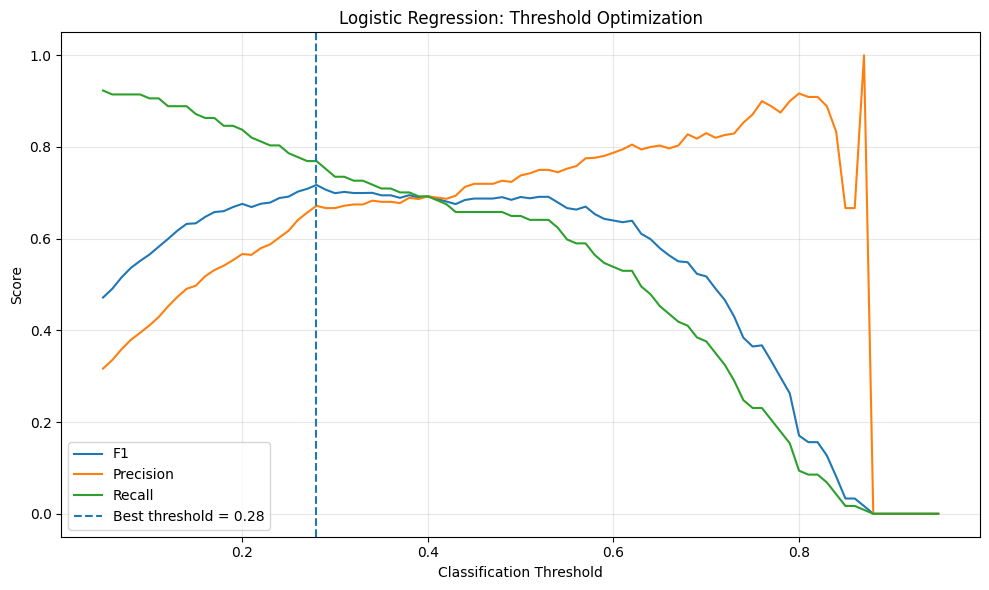

In [100]:

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Logistic Regression: Threshold Optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [101]:

optimized_predictions = (
    val_probs >= best_threshold
).astype(int)

threshold_comparison = pd.DataFrame({
    "Threshold": [0.5, best_threshold],
    "F1": [
        f1_score(y_val, val_preds),
        f1_score(y_val, optimized_predictions)
    ],
    "Precision": [
        precision_score(y_val, val_preds),
        precision_score(y_val, optimized_predictions)
    ],
    "Recall": [
        recall_score(y_val, val_preds),
        recall_score(y_val, optimized_predictions)
    ]
}, index=["Default", "Optimized"])

display(threshold_comparison.round(4))


,Threshold,F1,Precision,Recall
Default,0.50,0.6909,0.7379,0.6496
Optimized,0.28,0.7171,0.6716,0.7692



### Logistic Regression Threshold Optimization: Findings

Threshold optimization was performed on the validation dataset using F1 score as the selection criterion.

The best validation threshold was 0.28, compared with the default threshold of 0.50.

At the default threshold, the baseline achieved an F1 score of 0.6909, precision of 0.7379, and recall of 0.6496.

Using the optimized threshold increased F1 to 0.7171 and recall to 0.7692, while precision decreased to 0.6716.

The results demonstrate the trade-off between precision and recall. The lower threshold identifies a greater proportion of actual podium finishers but also increases false-positive predictions.

The threshold of 0.28 is retained as the validation-selected operating point for Logistic Regression. No test-set information was used during optimization.



## 4.3 Random Forest Classifier

Random Forest is selected as the second statistical machine-learning model.

Unlike Logistic Regression, Random Forest can represent nonlinear relationships and interactions between input features without requiring an explicitly specified linear decision boundary.

The classifier combines multiple decision trees trained on bootstrapped samples and uses their aggregated predictions to estimate podium probabilities.

The model is trained using the same training observations and preprocessed features as Logistic Regression to ensure comparability. Its initial performance is evaluated on the training and validation sets using a default classification threshold of 0.5.


In [102]:

# Part 4.3: Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=3,
    random_state=1111,
    n_jobs=-1
)

# Train on the same dataset as Logistic Regression
random_forest_model.fit(
    X_train_processed,
    y_train
)

# Predict probabilities
rf_train_probs = random_forest_model.predict_proba(
    X_train_processed
)[:, 1]

rf_val_probs = random_forest_model.predict_proba(
    X_val_processed
)[:, 1]

# Initial threshold
rf_threshold = 0.5

rf_train_preds = (
    rf_train_probs >= rf_threshold
).astype(int)

rf_val_preds = (
    rf_val_probs >= rf_threshold
).astype(int)

# Evaluate using our existing function
rf_results = pd.DataFrame({
    "Training": evaluate_model(
        y_train,
        rf_train_preds,
        rf_train_probs
    ),
    "Validation": evaluate_model(
        y_val,
        rf_val_preds,
        rf_val_probs
    )
}).T

print("Random Forest Results")
display(rf_results.round(4))


Random Forest Results


,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
Training,0.9253,0.6500,0.4309,0.7462,0.3029,0.9003
Validation,0.9236,0.6738,0.6948,0.7708,0.6325,0.9167


In [103]:

# Compare validation performance at threshold 0.5

statistical_comparison = pd.DataFrame({
    "Logistic Regression": evaluate_model(
        y_val,
        val_preds,
        val_probs
    ),
    "Random Forest": evaluate_model(
        y_val,
        rf_val_preds,
        rf_val_probs
    )
}).T

print("Statistical Models: Validation Comparison")
display(statistical_comparison.round(4))


Statistical Models: Validation Comparison


,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
Logistic Regression,0.9254,0.7267,0.6909,0.7379,0.6496,0.9128
Random Forest,0.9236,0.6738,0.6948,0.7708,0.6325,0.9167



### Random Forest Results and Statistical Model Comparison

The Random Forest classifier achieved a validation ROC-AUC of 0.9236, average precision (PR-AUC) of 0.6738, and F1 score of 0.6948 at the default classification threshold of 0.5.

Compared with Logistic Regression, Random Forest achieved slightly higher validation F1, precision, and accuracy. However, Logistic Regression produced higher ROC-AUC, PR-AUC, and recall.

The difference in PR-AUC was particularly notable, with Logistic Regression achieving 0.7267 compared with 0.6738 for Random Forest.

Since podium finishes represent the minority class, PR-AUC is considered an important measure of the models' ability to rank podium finishers above other drivers.

These findings suggest that Logistic Regression is currently the stronger overall candidate, although Random Forest threshold optimization is needed before comparing the models at their selected operating points.

The test dataset remains excluded from model development and selection.



## 4.4 Random Forest Threshold Optimization

The Random Forest model initially uses a probability threshold of 0.5.

To determine whether this operating point provides an appropriate balance between precision and recall, classification thresholds from 0.05 to 0.95 are evaluated using the validation set.

The threshold maximizing validation F1 is selected without accessing test-set labels or predictions.


In [104]:

# Random Forest threshold optimization

rf_thresholds = np.arange(0.05, 0.951, 0.01)

rf_threshold_results = []

for t in rf_thresholds:
    predictions = (rf_val_probs >= t).astype(int)

    rf_threshold_results.append({
        "Threshold": t,
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        )
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

rf_best_idx = rf_threshold_df["F1"].idxmax()

rf_best_threshold = float(
    rf_threshold_df.loc[rf_best_idx, "Threshold"]
)

print(f"Best RF threshold: {rf_best_threshold:.2f}")
print(
    f"Best RF validation F1: "
    f"{rf_threshold_df.loc[rf_best_idx, 'F1']:.4f}"
)

display(
    rf_threshold_df.sort_values(
        "F1", ascending=False
    ).head(10).round(4)
)


Best RF threshold: 0.40
Best RF validation F1: 0.7100


,Threshold,F1,Precision,Recall
35,0.40,0.7100,0.7193,0.7009
34,0.39,0.7094,0.7094,0.7094
33,0.38,0.7059,0.6942,0.7179
39,0.44,0.7048,0.7273,0.6838
36,0.41,0.7043,0.7168,0.6923
37,0.42,0.7018,0.7207,0.6838
38,0.43,0.7018,0.7207,0.6838
32,0.37,0.7000,0.6829,0.7179
40,0.45,0.6991,0.7248,0.6752
46,0.51,0.6948,0.7708,0.6325


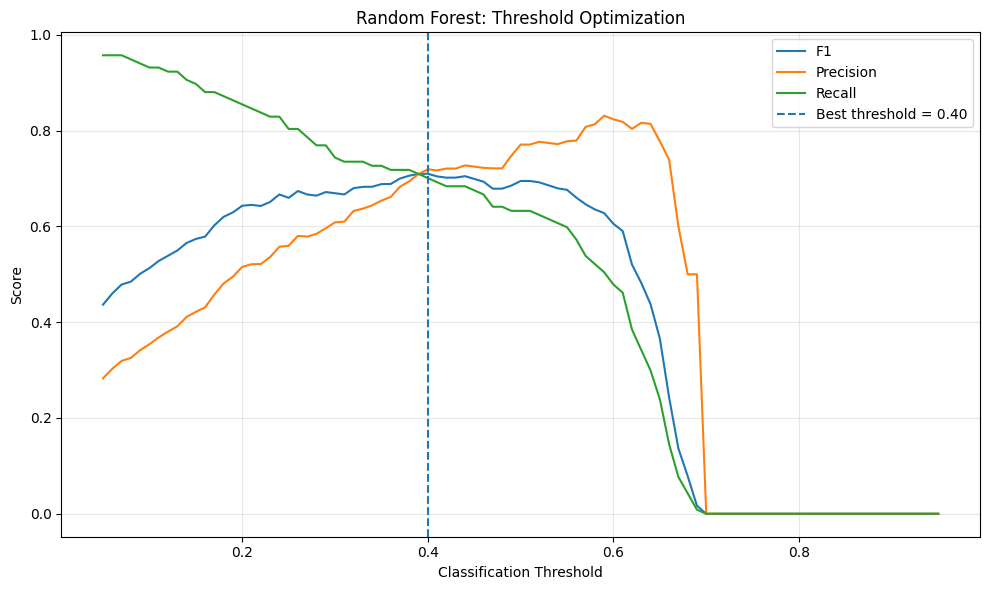

In [105]:

plt.figure(figsize=(10, 6))

plt.plot(
    rf_threshold_df["Threshold"],
    rf_threshold_df["F1"],
    label="F1"
)

plt.plot(
    rf_threshold_df["Threshold"],
    rf_threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    rf_threshold_df["Threshold"],
    rf_threshold_df["Recall"],
    label="Recall"
)

plt.axvline(
    rf_best_threshold,
    linestyle="--",
    label=f"Best threshold = {rf_best_threshold:.2f}"
)

plt.title("Random Forest: Threshold Optimization")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [106]:

# Compare models using validation-selected thresholds

lr_optimized_preds = (
    val_probs >= best_threshold
).astype(int)

rf_optimized_preds = (
    rf_val_probs >= rf_best_threshold
).astype(int)

optimized_comparison = pd.DataFrame({
    "Logistic Regression": evaluate_model(
        y_val,
        lr_optimized_preds,
        val_probs
    ),
    "Random Forest": evaluate_model(
        y_val,
        rf_optimized_preds,
        rf_val_probs
    )
}).T

optimized_comparison["Selected Threshold"] = [
    best_threshold,
    rf_best_threshold
]

print("Optimized Statistical Models: Validation Comparison")

display(optimized_comparison.round(4))


Optimized Statistical Models: Validation Comparison


,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy,Selected Threshold
Logistic Regression,0.9254,0.7267,0.7171,0.6716,0.7692,0.9090,0.28
Random Forest,0.9236,0.6738,0.7100,0.7193,0.7009,0.9141,0.40



### Random Forest Threshold Optimization: Findings

Random Forest threshold optimization was performed using the validation dataset, with F1 score as the optimization criterion.

The optimal threshold was 0.40, compared with the initial threshold of 0.50. This increased validation F1 from 0.6948 to 0.7100 and recall from 0.6325 to 0.7009, while precision decreased from 0.7708 to 0.7193.

After threshold optimization, Logistic Regression achieved a slightly higher F1 score (0.7171 versus 0.7100) and a higher PR-AUC (0.7267 versus 0.6738).

Random Forest maintained higher precision and accuracy, indicating a more conservative operating point relative to Logistic Regression's optimized threshold.

Overall, Logistic Regression remains the stronger candidate based on validation F1 and PR-AUC. However, the final model selection will also consider the shallow neural network and additional experiments.

No test-set information was used during threshold selection.



## 4.5 Shallow Feedforward Neural Network

A shallow feedforward neural network is implemented as the third classifier.

The network contains two hidden layers with 64 and 32 neurons, respectively, using ReLU activation functions. Dropout regularization is applied to reduce overfitting.

The final layer uses sigmoid activation to estimate the probability of a podium finish.

Binary cross-entropy is used as the training loss, with Adam as the optimizer. Early stopping monitors validation loss and restores the weights from the best epoch.

The neural network uses the same preprocessed training and validation observations as the statistical models to ensure a consistent comparison.


In [107]:

# Part 4.5: Shallow Neural Network

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
tf.keras.utils.set_random_seed(1111)

# Convert to dense arrays if the preprocessing output is sparse
def to_dense_float32(X):
    if hasattr(X, "toarray"):
        X = X.toarray()
    return np.asarray(X, dtype=np.float32)

X_train_nn = to_dense_float32(X_train_processed)
X_val_nn = to_dense_float32(X_val_processed)

y_train_nn = np.asarray(y_train).astype(np.float32).ravel()
y_val_nn = np.asarray(y_val).astype(np.float32).ravel()

# Define the model
nn_model = keras.Sequential([
    keras.Input(shape=(X_train_nn.shape[1],)),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")
])

nn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(
            name="pr_auc", curve="PR"
        )
    ]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

# Train using training and validation data only
nn_history = nn_model.fit(
    X_train_nn,
    y_train_nn,
    validation_data=(X_val_nn, y_val_nn),
    epochs=100,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)

nn_model.summary()


2026-10-13 18:59:02.964868: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.3223 - pr_auc: 0.3380 - roc_auc: 0.8077 - val_loss: 0.2506 - val_pr_auc: 0.6689 - val_roc_auc: 0.9138
Epoch 2/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2469 - pr_auc: 0.5191 - roc_auc: 0.8939 - val_loss: 0.2434 - val_pr_auc: 0.7061 - val_roc_auc: 0.9188
Epoch 3/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2413 - pr_auc: 0.5318 - roc_auc: 0.8994 - val_loss: 0.2402 - val_pr_auc: 0.7148 - val_roc_auc: 0.9205
Epoch 4/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2383 - pr_auc: 0.5367 - roc_auc: 0.9027 - val_loss: 0.2388 - val_pr_auc: 0.7155 - val_roc_auc: 0.9205
Epoch 5/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2362 - pr_auc: 0.5385 - roc_auc: 0.9049 - val_loss: 0.2384 - val_pr_auc: 0.7302 - val_roc_auc: 0.9199
Epoch 6/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2332 - pr_auc: 0.5611 - roc_auc: 0.9076 - val_loss: 0.2372 - val_pr_auc: 0.7305 - val_roc_auc: 0.9198
Epoch 7/100
96/96 ━━━━

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,789 (245.27 KB)

 Trainable params: 20,929 (81.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 41,860 (163.52 KB)

In [108]:

# Neural network predicted probabilities

nn_train_probs = nn_model.predict(
    X_train_nn, verbose=0
).ravel()

nn_val_probs = nn_model.predict(
    X_val_nn, verbose=0
).ravel()

# Default classification threshold
nn_threshold = 0.5

nn_train_preds = (
    nn_train_probs >= nn_threshold
).astype(int)

nn_val_preds = (
    nn_val_probs >= nn_threshold
).astype(int)

nn_results = pd.DataFrame({
    "Training": evaluate_model(
        y_train,
        nn_train_preds,
        nn_train_probs
    ),
    "Validation": evaluate_model(
        y_val,
        nn_val_preds,
        nn_val_probs
    )
}).T

print("Shallow Neural Network Results")
display(nn_results.round(4))


Shallow Neural Network Results


,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy
Training,0.9191,0.5997,0.4865,0.6541,0.3873,0.8981
Validation,0.9209,0.7341,0.7064,0.7624,0.6581,0.9179


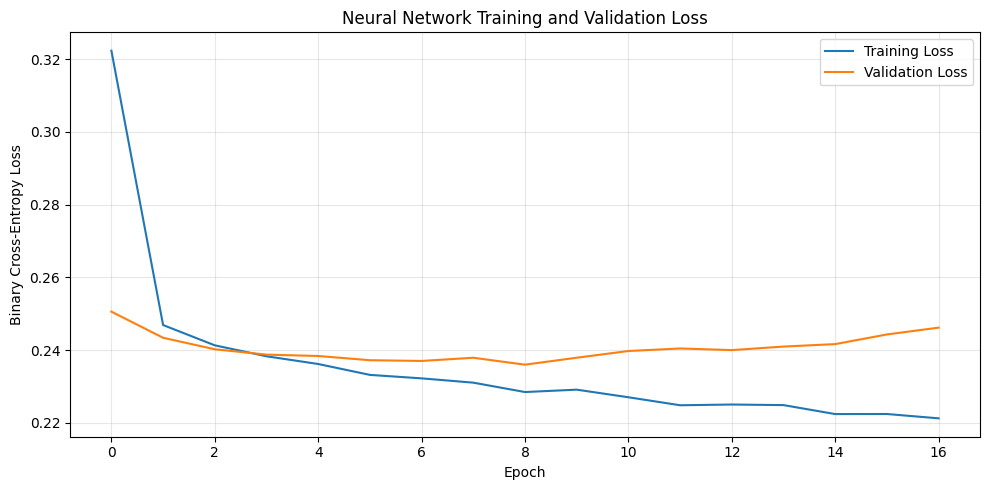

In [109]:

plt.figure(figsize=(10, 5))

plt.plot(
    nn_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    nn_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Neural Network Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Shallow Neural Network Results and Training Analysis

The shallow feedforward neural network achieved a validation ROC-AUC of 0.9209, average precision (PR-AUC) of 0.7341, and F1 score of 0.7064 at the default classification threshold of 0.5.

Compared with the two statistical models, the neural network achieved the highest validation PR-AUC, suggesting slightly stronger precision–recall ranking performance on the validation dataset.

The training-loss curve decreased steadily throughout training, while validation loss reached its minimum at approximately epoch 9 before increasing.

This divergence suggests the onset of overfitting, as the model continued improving its fit to the training data without corresponding improvements in validation loss.

Early stopping terminated training after 17 epochs and restored the weights from the epoch with the lowest validation loss.

These results demonstrate the importance of regularization and early stopping when training neural networks on historical Formula 1 data.

The neural network's classification threshold will be optimized using validation data before final model comparison.



## 4.6 Neural Network Threshold Optimization

The shallow neural network initially uses a probability threshold of 0.5 to classify podium finishes.

To improve the balance between precision and recall, thresholds between 0.05 and 0.95 are evaluated using validation predictions.

The threshold maximizing validation F1 is selected, while the unseen test dataset remains excluded from optimization.


In [110]:

# Neural Network threshold optimization

nn_thresholds = np.arange(0.05, 0.951, 0.01)

nn_threshold_results = []

for t in nn_thresholds:
    predictions = (nn_val_probs >= t).astype(int)

    nn_threshold_results.append({
        "Threshold": t,
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        )
    })

nn_threshold_df = pd.DataFrame(nn_threshold_results)

nn_best_idx = nn_threshold_df["F1"].idxmax()

nn_best_threshold = float(
    nn_threshold_df.loc[nn_best_idx, "Threshold"]
)

print(f"Best NN threshold: {nn_best_threshold:.2f}")
print(
    f"Best NN validation F1: "
    f"{nn_threshold_df.loc[nn_best_idx, 'F1']:.4f}"
)

display(
    nn_threshold_df.sort_values(
        "F1", ascending=False
    ).head(10).round(4)
)


Best NN threshold: 0.29
Best NN validation F1: 0.7068


,Threshold,F1,Precision,Recall
24,0.29,0.7068,0.6667,0.7521
46,0.51,0.7064,0.7624,0.6581
47,0.52,0.7064,0.7624,0.6581
44,0.49,0.7064,0.7624,0.6581
45,0.50,0.7064,0.7624,0.6581
23,0.28,0.7040,0.6617,0.7521
48,0.53,0.7005,0.7600,0.6496
42,0.47,0.6968,0.7404,0.6581
43,0.48,0.6968,0.7404,0.6581
25,0.30,0.6964,0.6615,0.7350


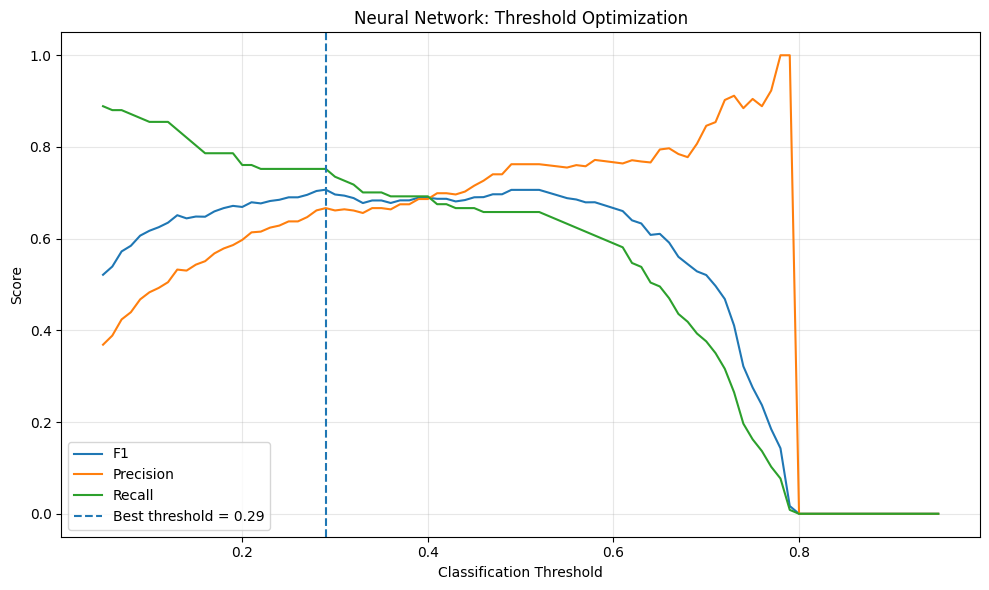

In [111]:

plt.figure(figsize=(10, 6))

plt.plot(
    nn_threshold_df["Threshold"],
    nn_threshold_df["F1"],
    label="F1"
)

plt.plot(
    nn_threshold_df["Threshold"],
    nn_threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    nn_threshold_df["Threshold"],
    nn_threshold_df["Recall"],
    label="Recall"
)

plt.axvline(
    nn_best_threshold,
    linestyle="--",
    label=f"Best threshold = {nn_best_threshold:.2f}"
)

plt.title("Neural Network: Threshold Optimization")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [112]:

# Use each model's validation-selected threshold

lr_final_val_preds = (
    val_probs >= best_threshold
).astype(int)

rf_final_val_preds = (
    rf_val_probs >= rf_best_threshold
).astype(int)

nn_final_val_preds = (
    nn_val_probs >= nn_best_threshold
).astype(int)

all_models_comparison = pd.DataFrame({
    "Logistic Regression": evaluate_model(
        y_val, lr_final_val_preds, val_probs
    ),
    "Random Forest": evaluate_model(
        y_val, rf_final_val_preds, rf_val_probs
    ),
    "Shallow Neural Network": evaluate_model(
        y_val, nn_final_val_preds, nn_val_probs
    )
}).T

all_models_comparison["Selected Threshold"] = [
    best_threshold,
    rf_best_threshold,
    nn_best_threshold
]

print("Optimized Model Comparison - Validation")

display(all_models_comparison.round(4))


Optimized Model Comparison - Validation


,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy,Selected Threshold
Logistic Regression,0.9254,0.7267,0.7171,0.6716,0.7692,0.9090,0.28
Random Forest,0.9236,0.6738,0.7100,0.7193,0.7009,0.9141,0.40
Shallow Neural Network,0.9209,0.7341,0.7068,0.6667,0.7521,0.9064,0.29



### Neural Network Threshold Optimization and Model Comparison

Threshold optimization identified 0.29 as the F1-maximizing operating point for the shallow neural network on the validation dataset.

The optimized threshold increased F1 only slightly, from 0.7064 to 0.7068. Recall increased from 0.6581 to 0.7521, while precision decreased from 0.7624 to 0.6667.

This result indicates that the neural network supports different precision–recall trade-offs with nearly identical F1 performance.

Following threshold optimization, Logistic Regression achieved the highest validation F1 (0.7171), followed by Random Forest (0.7100) and the shallow neural network (0.7068).

Logistic Regression also achieved the highest ROC-AUC (0.9254), while the neural network achieved the highest average precision (0.7341).

These findings demonstrate that no single model dominates every evaluation metric.

For the current experiment, F1 is used as the primary threshold-selection metric, with PR-AUC and ROC-AUC serving as complementary threshold-independent evaluation measures.

All model training and threshold selection were performed without accessing the test dataset.



## 4.7 Logistic Regression Hyperparameter Experiment

To investigate whether regularization strength affects prediction performance, several values of the Logistic Regression hyperparameter C are evaluated.

The experiment uses identical training and validation observations and the same preprocessed feature set as the baseline model.

For each configuration, the model is trained on the training dataset and evaluated using validation ROC-AUC, average precision, and F1.

The previously selected baseline configuration is retained as a reference, while the test dataset remains excluded from hyperparameter selection.


In [113]:

# Logistic Regression regularization experiment

from sklearn.linear_model import LogisticRegression

c_values = [0.01, 0.1, 1.0, 10.0]

lr_tuning_results = []
lr_tuned_models = {}

for c in c_values:

    model = LogisticRegression(
        C=c,
        max_iter=2000,
        random_state=1111
    )

    model.fit(X_train_processed, y_train)

    probabilities = model.predict_proba(
        X_val_processed
    )[:, 1]

    predictions = (
        probabilities >= best_threshold
    ).astype(int)

    scores = evaluate_model(
        y_val,
        predictions,
        probabilities
    )

    lr_tuning_results.append({
        "C": c,
        "ROC-AUC": scores["ROC-AUC"],
        "PR-AUC": scores["PR-AUC"],
        "F1": scores["F1"],
        "Precision": scores["Precision"],
        "Recall": scores["Recall"]
    })

    lr_tuned_models[c] = model

lr_tuning_df = pd.DataFrame(lr_tuning_results)

display(lr_tuning_df.round(4))


,C,ROC-AUC,PR-AUC,F1,Precision,Recall
0,0.01,0.9258,0.7195,0.6853,0.6418,0.7350
1,0.10,0.9266,0.7275,0.7036,0.6544,0.7607
2,1.00,0.9254,0.7267,0.7171,0.6716,0.7692
3,10.00,0.9217,0.7266,0.7171,0.6716,0.7692



### Logistic Regression Regularization Experiment: Findings

Four regularization settings (C = 0.01, 0.1, 1.0, and 10.0) were evaluated using the same training and validation datasets.

The classification threshold was fixed at 0.28 to isolate the effect of regularization strength.

The results showed that C = 0.1 achieved the highest ROC-AUC (0.9266) and average precision (0.7275), while C = 1.0 and C = 10.0 achieved the highest F1 score (0.7171).

Since F1 was selected as the primary threshold-based performance metric, C = 1.0 was retained. This configuration achieved the highest observed F1 while applying stronger regularization than the equally performing C = 10.0 configuration.

The experiment suggests that increasing model complexity through weaker regularization does not necessarily improve validation performance.

These conclusions are limited to the tested configurations and validation period. The test dataset was not used for hyperparameter selection.



## 4.8 Feature-Group Ablation Experiments

Feature-group ablation is conducted to investigate how different categories of pre-race information contribute to podium prediction.

The experiment removes one feature group at a time and retrains the Logistic Regression model using the remaining features.

Performance is compared against the full-feature baseline using validation ROC-AUC, average precision, and F1.

This analysis measures each feature group's predictive contribution within the selected model and dataset. It does not establish causal relationships between features and race outcomes.


In [114]:

# Inspect the feature columns prepared in Part 3

print("Original feature columns:")
print(X_train.columns.tolist())

print("\nNumber of original features:")
print(X_train.shape[1])

print("\nProcessed feature matrix shape:")
print(X_train_processed.shape)

# Inspect preprocessing pipeline if available
print("\nPreprocessor:")
print(preprocessor)


Original feature columns:
['grid_numeric', 'pit_lane_or_unassigned_grid', 'qualifying_position', 'driver_previous_races', 'driver_prior_podium_rate', 'driver_recent_podium_rate', 'constructor_previous_races', 'constructor_prior_podium_rate', 'constructor_recent_podium_rate', 'constructorId', 'circuitId']

Number of original features:
11

Processed feature matrix shape:
(24529, 293)

Preprocessor:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['grid_numeric', 'pit_lane_or_unassigned_grid',
                                  'qualifying_position',
                                  'driver_previous_races',
                                  'driver_prior_podi

In [115]:

# Define feature groups for ablation

feature_groups = {
    "Grid": [
        "grid_numeric",
        "pit_lane_or_unassigned_grid"
    ],

    "Qualifying": [
        "qualifying_position"
    ],

    "Driver Form": [
        "driver_previous_races",
        "driver_prior_podium_rate",
        "driver_recent_podium_rate"
    ],

    "Constructor Form": [
        "constructor_previous_races",
        "constructor_prior_podium_rate",
        "constructor_recent_podium_rate"
    ],

    "Identity / Circuit": [
        "constructorId",
        "circuitId"
    ]
}

# Verify that our groups cover every feature
all_grouped_features = [
    feature
    for group in feature_groups.values()
    for feature in group
]

assert set(all_grouped_features) == set(X_train.columns)

assert len(all_grouped_features) == len(set(all_grouped_features))

print("Feature groups successfully defined.")

for group_name, columns in feature_groups.items():
    print(f"{group_name}: {len(columns)} features")


Feature groups successfully defined.
Grid: 2 features
Qualifying: 1 features
Driver Form: 3 features
Constructor Form: 3 features
Identity / Circuit: 2 features


In [116]:

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

ablation_results = []

# Full-feature baseline
baseline_scores = evaluate_model(
    y_val,
    (val_probs >= best_threshold).astype(int),
    val_probs
)

ablation_results.append({
    "Removed Group": "None (Full Model)",
    "Remaining Features": X_train.shape[1],
    "ROC-AUC": baseline_scores["ROC-AUC"],
    "PR-AUC": baseline_scores["PR-AUC"],
    "F1": baseline_scores["F1"]
})

# Remove one group at a time
for group_name, removed_columns in feature_groups.items():

    remaining_columns = [
        col for col in X_train.columns
        if col not in removed_columns
    ]

    # Clone preprocessing components to avoid modifying
    # the original fitted preprocessor
    transformers = []

    for name, transformer, columns in preprocessor.transformers:
        if name == "remainder":
            continue

        selected_columns = [
            col for col in columns
            if col in remaining_columns
        ]

        if selected_columns:
            transformers.append(
                (name, clone(transformer), selected_columns)
            )

    ablation_preprocessor = ColumnTransformer(
        transformers=transformers
    )

    # Fit preprocessing on training data only
    X_train_ablation = (
        ablation_preprocessor.fit_transform(
            X_train[remaining_columns]
        )
    )

    X_val_ablation = (
        ablation_preprocessor.transform(
            X_val[remaining_columns]
        )
    )

    # Train the same Logistic Regression configuration
    ablation_model = LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=1111
    )

    ablation_model.fit(X_train_ablation, y_train)

    # Evaluate using the fixed baseline threshold
    probabilities = ablation_model.predict_proba(
        X_val_ablation
    )[:, 1]

    predictions = (
        probabilities >= best_threshold
    ).astype(int)

    scores = evaluate_model(
        y_val,
        predictions,
        probabilities
    )

    ablation_results.append({
        "Removed Group": group_name,
        "Remaining Features": len(remaining_columns),
        "ROC-AUC": scores["ROC-AUC"],
        "PR-AUC": scores["PR-AUC"],
        "F1": scores["F1"]
    })

ablation_df = pd.DataFrame(ablation_results)

# Calculate the performance change relative to the full model
for metric in ["ROC-AUC", "PR-AUC", "F1"]:
    ablation_df[f"{metric} Drop"] = (
        ablation_df.loc[0, metric] - ablation_df[metric]
    )

display(ablation_df.round(4))


,Removed Group,Remaining Features,ROC-AUC,PR-AUC,F1,ROC-AUC Drop,PR-AUC Drop,F1 Drop
0,None (Full Model),11,0.9254,0.7267,0.7171,0.0000,0.0000,0.0000
1,Grid,9,0.9207,0.7055,0.6911,0.0047,0.0213,0.0261
2,Qualifying,10,0.9217,0.7194,0.6984,0.0037,0.0073,0.0187
3,Driver Form,8,0.9214,0.6817,0.6992,0.0039,0.0450,0.0179
4,Constructor Form,8,0.9244,0.7367,0.6914,0.0009,-0.0100,0.0257
5,Identity / Circuit,9,0.9253,0.7126,0.6929,0.0001,0.0141,0.0242


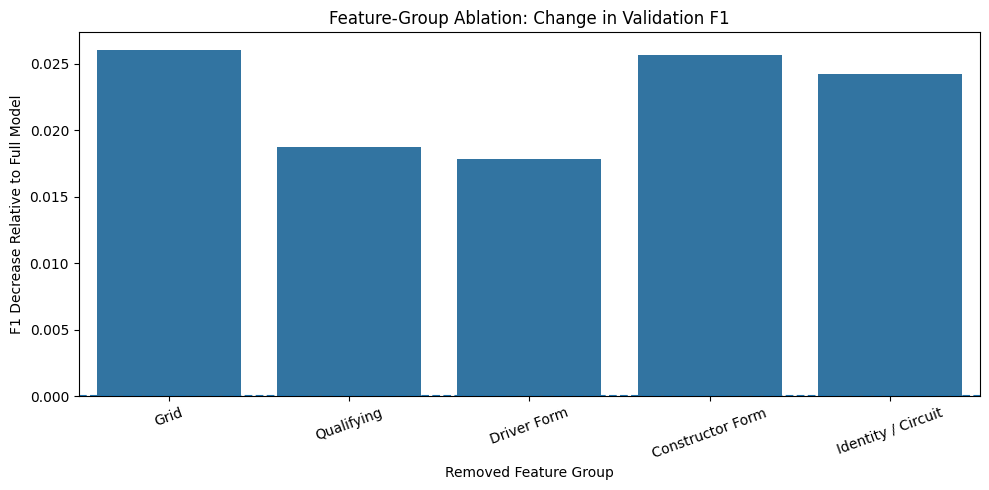

In [117]:

# Plot the change in F1 after removing each feature group

ablation_plot = ablation_df[
    ablation_df["Removed Group"] != "None (Full Model)"
].copy()

plt.figure(figsize=(10, 5))

sns.barplot(
    data=ablation_plot,
    x="Removed Group",
    y="F1 Drop"
)

plt.axhline(0, linestyle="--")

plt.title("Feature-Group Ablation: Change in Validation F1")
plt.xlabel("Removed Feature Group")
plt.ylabel("F1 Decrease Relative to Full Model")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()



### Feature-Group Ablation: Findings

Feature-group ablation was conducted using Logistic Regression with C = 1.0 and a fixed classification threshold of 0.28.

Each experiment removed one group of original features, refitted the preprocessing pipeline on the training data, and retrained the classifier.

Removing grid features resulted in the largest decrease in validation F1, from 0.7171 to 0.6911. This suggests that starting-grid information contributes substantially to podium classification performance.

Removing constructor-form features produced the second-largest F1 reduction, reaching 0.6914. However, average precision increased from 0.7267 to 0.7367, indicating that the ranking and threshold-based classification metrics do not always respond identically.

Removing driver-form features reduced average precision to 0.6817, the largest PR-AUC decrease among the ablation experiments.

Qualifying and identity/circuit features also contributed positively to F1, as removing either group reduced validation performance.

Overall, the full-feature model achieved the highest validation F1 among the tested configurations.

These results support retaining the complete feature set for the current F1-oriented modeling objective. However, feature ablation measures predictive dependence rather than causal relationships, and the findings are specific to the tested model, threshold, and validation period.



## 4.9 Preprocessing-Order Experiment 1: Imputation and Scaling

This experiment evaluates whether changing the order of median imputation and standard scaling affects Logistic Regression performance.

Two preprocessing configurations are compared:

- Order A: Median imputation followed by StandardScaler.
- Order B: StandardScaler followed by median imputation.

Missingness indicators are retained consistently for both configurations.

Both preprocessing pipelines are fitted exclusively on training data, and the same training and validation observations, feature columns, model hyperparameters, and classification threshold are used.

Because median imputation and standard scaling may produce mathematically equivalent transformations under certain conditions, the experiment also compares the resulting feature matrices directly.


In [118]:

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder

numerical_features = [
    "grid_numeric",
    "pit_lane_or_unassigned_grid",
    "qualifying_position",
    "driver_previous_races",
    "driver_prior_podium_rate",
    "driver_recent_podium_rate",
    "constructor_previous_races",
    "constructor_prior_podium_rate",
    "constructor_recent_podium_rate"
]

categorical_features = ["constructorId", "circuitId"]

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Order A: impute first, then scale
order_a_numeric = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median"
    )),
    ("scaler", StandardScaler())
])

# Order B: scale first (NaNs preserved), then impute
order_b_numeric = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", SimpleImputer(
        strategy="median"
    ))
])

def build_order_preprocessor(numeric_pipeline):
    return ColumnTransformer([
        ("numeric", numeric_pipeline, numerical_features),

        ("missing", MissingIndicator(
            features="all"
        ), numerical_features),

        ("categorical", clone(
            categorical_pipeline
        ), categorical_features)
    ])

preprocessing_orders = {
    "Impute -> Scale": build_order_preprocessor(
        order_a_numeric
    ),
    "Scale -> Impute": build_order_preprocessor(
        order_b_numeric
    )
}

order_results = []
order_matrices = {}

for order_name, order_preprocessor in preprocessing_orders.items():

    X_tr = order_preprocessor.fit_transform(X_train)
    X_va = order_preprocessor.transform(X_val)

    model = LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=1111
    )

    model.fit(X_tr, y_train)

    probabilities = model.predict_proba(X_va)[:, 1]
    predictions = (
        probabilities >= best_threshold
    ).astype(int)

    scores = evaluate_model(y_val, predictions, probabilities)

    order_results.append({
        "Preprocessing Order": order_name,
        "ROC-AUC": scores["ROC-AUC"],
        "PR-AUC": scores["PR-AUC"],
        "F1": scores["F1"]
    })

    order_matrices[order_name] = X_va

order_results_df = pd.DataFrame(order_results)

display(order_results_df.round(4))

difference = np.max(np.abs(
    order_matrices["Impute -> Scale"]
    - order_matrices["Scale -> Impute"]
))

print(
    "Maximum absolute difference between feature matrices:",
    difference
)


,Preprocessing Order,ROC-AUC,PR-AUC,F1
0,Impute -> Scale,0.9253,0.7258,0.7092
1,Scale -> Impute,0.9253,0.7277,0.7120


Maximum absolute difference between feature matrices: 1.0923135489201914



### Preprocessing-Order Experiment 1: Findings

Two numerical preprocessing orders were evaluated using Logistic Regression with identical training and validation observations.

The first configuration applied median imputation before standard scaling, while the second applied standard scaling before median imputation.

Both configurations produced similar validation performance. Imputation followed by scaling achieved ROC-AUC = 0.9253, average precision = 0.7258, and F1 = 0.7092.

Scaling followed by imputation achieved ROC-AUC = 0.9253, average precision = 0.7277, and F1 = 0.7120.

The maximum absolute difference between the transformed feature matrices was approximately 1.0923, confirming that preprocessing order affected the resulting feature representations.

This difference can arise because scaling statistics are estimated from different observed distributions depending on whether imputation occurs beforehand.

Although scaling before imputation achieved slightly higher F1 and average precision, the differences were small. Therefore, the experiment does not establish a substantial performance advantage for either order.

All preprocessing operations were fitted using training data only, and the test dataset remained untouched.



## 4.10 Preprocessing-Order Experiment 2: Imputation and Quantile Transformation

This experiment investigates whether the order of median imputation and nonlinear quantile transformation influences podium prediction performance.

Two configurations are compared:

- Order A: Median imputation followed by quantile transformation.
- Order B: Quantile transformation followed by median imputation.

Unlike standard scaling, quantile transformation uses the empirical distribution of the training data to transform numerical features.

Applying imputation before quantile transformation may alter the estimated distribution because imputed values contribute to the fitted quantiles.

Both configurations retain identical missingness indicators, categorical preprocessing, training and validation observations, and Logistic Regression hyperparameters.

The comparison uses validation ROC-AUC, average precision, and F1 at a fixed threshold of 0.28.


In [119]:

from sklearn.preprocessing import QuantileTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

# Quantile transformation configuration
def make_quantile_transformer():
    return QuantileTransformer(
        n_quantiles=1000,
        output_distribution="normal",
        random_state=1111
    )

# Order A: Imputation -> Quantile transformation
quantile_order_a = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("quantile", make_quantile_transformer())
])

# Order B: Quantile transformation -> Imputation
quantile_order_b = Pipeline([
    ("quantile", make_quantile_transformer()),
    ("imputer", SimpleImputer(strategy="median"))
])

quantile_orders = {
    "Impute -> Quantile": quantile_order_a,
    "Quantile -> Impute": quantile_order_b
}

quantile_results = []
quantile_matrices = {}

for order_name, numeric_pipeline in quantile_orders.items():

    experiment_preprocessor = ColumnTransformer([
        ("numeric", clone(numeric_pipeline), numerical_features),

        ("missing", MissingIndicator(
            features="all"
        ), numerical_features),

        ("categorical", clone(
            categorical_pipeline
        ), categorical_features)
    ])

    # Fit preprocessing only on training data
    X_tr = experiment_preprocessor.fit_transform(X_train)
    X_va = experiment_preprocessor.transform(X_val)

    # Train the same Logistic Regression configuration
    model = LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=1111
    )

    model.fit(X_tr, y_train)

    probabilities = model.predict_proba(X_va)[:, 1]

    predictions = (
        probabilities >= best_threshold
    ).astype(int)

    scores = evaluate_model(
        y_val,
        predictions,
        probabilities
    )

    quantile_results.append({
        "Preprocessing Order": order_name,
        "ROC-AUC": scores["ROC-AUC"],
        "PR-AUC": scores["PR-AUC"],
        "F1": scores["F1"],
        "Precision": scores["Precision"],
        "Recall": scores["Recall"]
    })

    quantile_matrices[order_name] = X_va

quantile_results_df = pd.DataFrame(
    quantile_results
)

display(quantile_results_df.round(4))

max_difference = np.max(np.abs(
    quantile_matrices["Impute -> Quantile"]
    - quantile_matrices["Quantile -> Impute"]
))

print(
    "Maximum absolute feature-matrix difference:",
    max_difference
)


,Preprocessing Order,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Impute -> Quantile,0.9064,0.6819,0.6877,0.6397,0.7436
1,Quantile -> Impute,0.9013,0.6802,0.6880,0.6466,0.7350


Maximum absolute feature-matrix difference: 0.9275677439938601


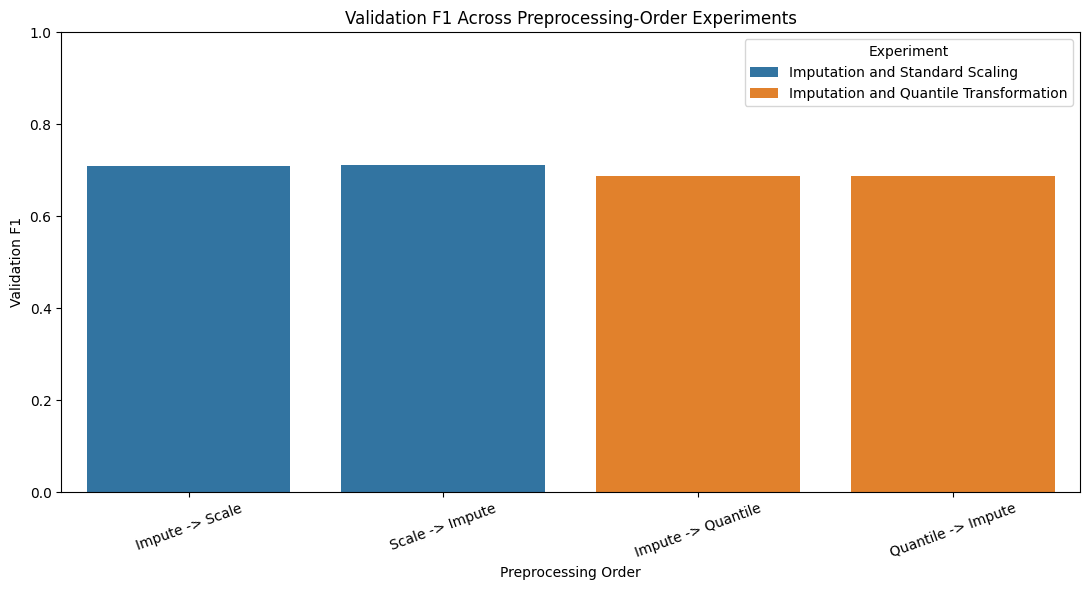

In [120]:

# Compare F1 across preprocessing-order experiments

order1_plot = order_results_df[
    ["Preprocessing Order", "F1"]
].copy()

order1_plot["Experiment"] = (
    "Imputation and Standard Scaling"
)

order2_plot = quantile_results_df[
    ["Preprocessing Order", "F1"]
].copy()

order2_plot["Experiment"] = (
    "Imputation and Quantile Transformation"
)

combined_order_results = pd.concat(
    [order1_plot, order2_plot],
    ignore_index=True
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=combined_order_results,
    x="Preprocessing Order",
    y="F1",
    hue="Experiment"
)

plt.title(
    "Validation F1 Across Preprocessing-Order Experiments"
)

plt.xlabel("Preprocessing Order")
plt.ylabel("Validation F1")

plt.xticks(rotation=20)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()



### Preprocessing-Order Experiments: Findings

Two preprocessing-order experiments were conducted to investigate the effects of transformation sequence on Logistic Regression performance.

The first experiment compared median imputation and standard scaling in both orders. Scaling before imputation achieved slightly higher validation F1 (0.7120 versus 0.7092) and average precision (0.7277 versus 0.7258).

The second experiment compared median imputation and quantile transformation. Both orders achieved similar validation F1 scores of approximately 0.688, with imputation before quantile transformation producing higher ROC-AUC and average precision.

The experiments confirmed that changing preprocessing order can affect transformed feature values. However, the resulting performance differences between orders were relatively small.

Standard-scaling configurations outperformed quantile-based configurations under the tested conditions.

The original Part 3 preprocessing pipeline achieved a validation F1 of 0.7171 and is retained for the final model comparison. Differences in missingness-indicator handling between the original and experimental pipelines mean that direct comparisons cannot be attributed solely to operation order.

These experiments were conducted using training and validation data only. The unseen test dataset was not used for preprocessing selection.


In [121]:

# Final consistency checks before test evaluation

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Test shape:", X_test_processed.shape)

assert (
    X_train_processed.shape[1]
    == X_val_processed.shape[1]
    == X_test_processed.shape[1]
), "Feature dimensions do not match."

assert len(X_train_processed) == len(y_train)
assert len(X_val_processed) == len(y_val)
assert len(X_test_processed) == len(y_test)

assert not np.isnan(X_train_processed).any()
assert not np.isnan(X_val_processed).any()
assert not np.isnan(X_test_processed).any()

print("All feature consistency checks passed.")


Training shape: (24529, 293)
Validation shape: (780, 293)
Test shape: (1359, 293)
All feature consistency checks passed.



## 4.11 Final Evaluation on the Unseen Test Set

After completing model training, hyperparameter experiments, threshold optimization, and feature-group ablation, the three classifiers are evaluated on the unseen test dataset covering the 2022–2024 Formula 1 seasons.

The same modeling rows and preprocessed features are used across all three models to ensure a fair comparison.

Model configurations and classification thresholds were selected using training and validation data only. The test dataset was not used during model selection.

The final evaluation reports ROC-AUC, average precision (PR-AUC), F1, precision, recall, and accuracy.

Logistic Regression is the primary selected model based on validation F1, while Random Forest and the shallow neural network are also evaluated to provide a complete comparison.


In [122]:

# Final test evaluation
# No further tuning after this step

# Convert test features for the neural network
X_test_nn = to_dense_float32(X_test_processed)

# Generate test probabilities
lr_test_probs = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

rf_test_probs = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

nn_test_probs = nn_model.predict(
    X_test_nn,
    verbose=0
).ravel()

# Apply validation-selected thresholds
lr_test_preds = (
    lr_test_probs >= best_threshold
).astype(int)

rf_test_preds = (
    rf_test_probs >= rf_best_threshold
).astype(int)

nn_test_preds = (
    nn_test_probs >= nn_best_threshold
).astype(int)

# Evaluate all three models
test_results = pd.DataFrame({
    "Logistic Regression": evaluate_model(
        y_test,
        lr_test_preds,
        lr_test_probs
    ),
    "Random Forest": evaluate_model(
        y_test,
        rf_test_preds,
        rf_test_probs
    ),
    "Shallow Neural Network": evaluate_model(
        y_test,
        nn_test_preds,
        nn_test_probs
    )
}).T

test_results["Selected Threshold"] = [
    best_threshold,
    rf_best_threshold,
    nn_best_threshold
]

print("Final Unseen Test Results (2022–2024)")

display(test_results.round(4))


Final Unseen Test Results (2022–2024)


,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy,Selected Threshold
Logistic Regression,0.9362,0.7023,0.6801,0.5768,0.8284,0.8830,0.28
Random Forest,0.9327,0.6868,0.6570,0.6476,0.6667,0.8955,0.40
Shallow Neural Network,0.9326,0.6938,0.6485,0.6034,0.7010,0.8859,0.29


In [123]:

# Compare validation and test performance

validation_results = all_models_comparison.copy()

comparison_metrics = [
    "ROC-AUC",
    "PR-AUC",
    "F1",
    "Precision",
    "Recall",
    "Accuracy"
]

comparison_rows = []

for model_name in test_results.index:
    comparison_rows.append({
        "Model": model_name,
        "Validation F1": validation_results.loc[
            model_name, "F1"
        ],
        "Test F1": test_results.loc[
            model_name, "F1"
        ],
        "Validation PR-AUC": validation_results.loc[
            model_name, "PR-AUC"
        ],
        "Test PR-AUC": test_results.loc[
            model_name, "PR-AUC"
        ],
        "Validation ROC-AUC": validation_results.loc[
            model_name, "ROC-AUC"
        ],
        "Test ROC-AUC": test_results.loc[
            model_name, "ROC-AUC"
        ]
    })

validation_test_comparison = pd.DataFrame(
    comparison_rows
)

display(validation_test_comparison.round(4))


,Model,Validation F1,Test F1,Validation PR-AUC,Test PR-AUC,Validation ROC-AUC,Test ROC-AUC
0,Logistic Regression,0.7171,0.6801,0.7267,0.7023,0.9254,0.9362
1,Random Forest,0.7100,0.6570,0.6738,0.6868,0.9236,0.9327
2,Shallow Neural Network,0.7068,0.6485,0.7341,0.6938,0.9209,0.9326



### Final Test Evaluation: Findings

The three classifiers were evaluated on the unseen 2022–2024 test dataset using the model configurations and classification thresholds selected from training and validation data.

Logistic Regression achieved the highest test ROC-AUC (0.9362), average precision (0.7023), F1 score (0.6801), and recall (0.8284).

Random Forest achieved the highest precision (0.6476) and accuracy (0.8955), but its test F1 score was lower at 0.6570.

The shallow neural network achieved an F1 score of 0.6485 and average precision of 0.6938, remaining competitive but not outperforming Logistic Regression.

All three models experienced reductions in F1 between validation and test evaluation. Logistic Regression decreased from 0.7171 to 0.6801, Random Forest from 0.7100 to 0.6570, and the neural network from 0.7068 to 0.6485.

In contrast, ROC-AUC increased slightly on the test set for all three classifiers. This indicates that ranking performance and threshold-dependent classification performance changed differently across evaluation periods.

The results support retaining Logistic Regression as the selected model under the validation-defined F1 criterion. Its performance on the unseen test set provides evidence of generalization to later Formula 1 seasons, although performance variation across eras remains a limitation.

No model configurations or classification thresholds were modified using test-set results.



## 4.12 Final Model Evaluation Visualizations

ROC and precision–recall curves are generated for all three classifiers using the unseen test dataset.

ROC curves illustrate the relationship between true-positive rate and false-positive rate across decision thresholds.

Precision–recall curves are particularly relevant because podium finishes constitute the minority class.

Confusion matrices are also examined to show the numbers of correctly and incorrectly classified podium and non-podium outcomes at the validation-selected thresholds.


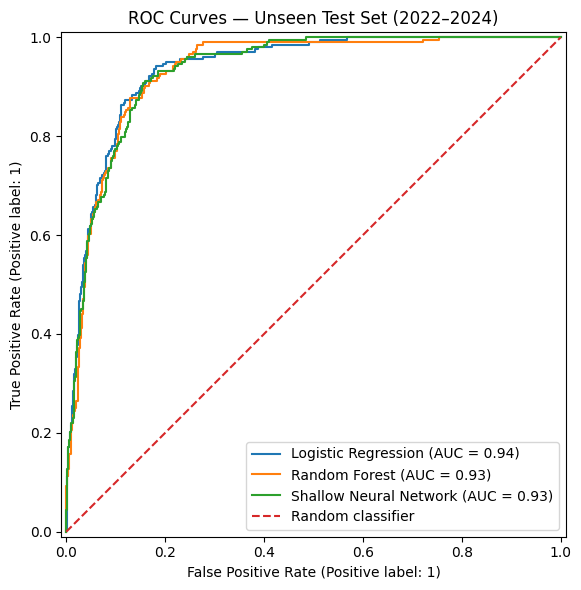

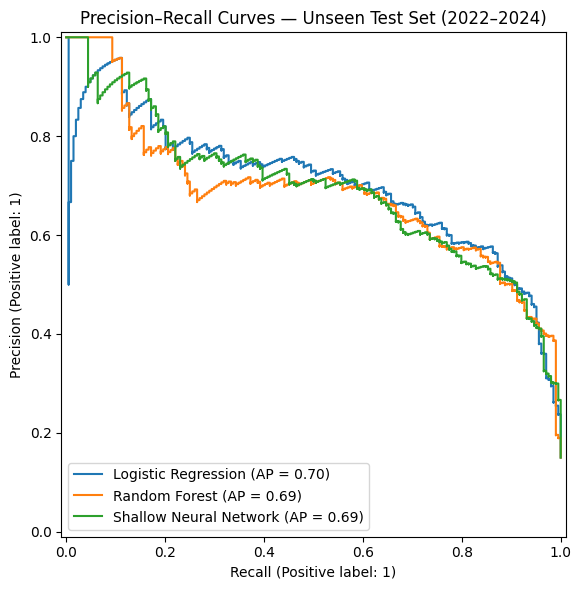

In [124]:

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

test_probabilities = {
    "Logistic Regression": lr_test_probs,
    "Random Forest": rf_test_probs,
    "Shallow Neural Network": nn_test_probs
}

# ROC curves
fig, ax = plt.subplots(figsize=(9, 6))

for model_name, probabilities in test_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name,
        ax=ax
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random classifier"
)

ax.set_title("ROC Curves — Unseen Test Set (2022–2024)")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

# Precision-recall curves
fig, ax = plt.subplots(figsize=(9, 6))

for model_name, probabilities in test_probabilities.items():
    PrecisionRecallDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name,
        ax=ax
    )

ax.set_title(
    "Precision–Recall Curves — Unseen Test Set (2022–2024)"
)

plt.tight_layout()
plt.show()


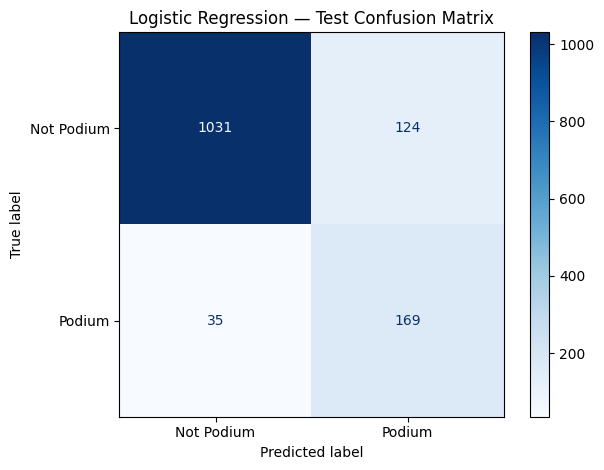

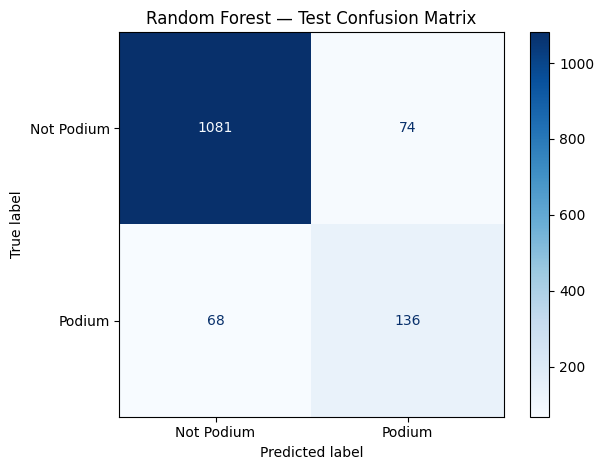

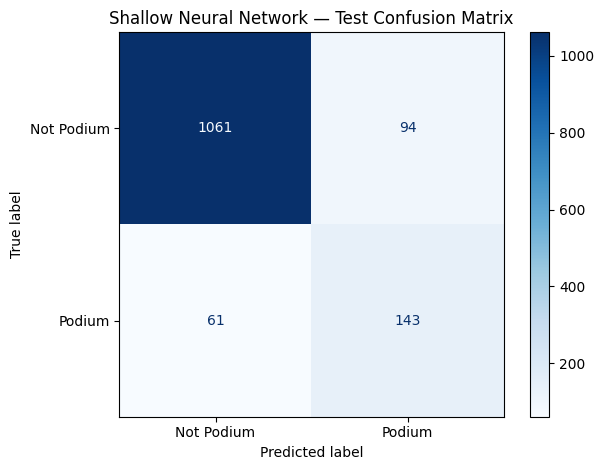

In [125]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

test_predictions = {
    "Logistic Regression": lr_test_preds,
    "Random Forest": rf_test_preds,
    "Shallow Neural Network": nn_test_preds
}

for model_name, predictions in test_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Podium", "Podium"]
    )

    display_cm.plot(cmap="Blues", values_format="d")

    plt.title(
        f"{model_name} — Test Confusion Matrix"
    )

    plt.tight_layout()
    plt.show()



### Evaluation Curve and Confusion Matrix Analysis

The ROC curves demonstrate that all three classifiers achieve strong discrimination between podium and non-podium outcomes on the unseen test dataset, with ROC-AUC values above 0.93.

Logistic Regression achieved the highest ROC-AUC (0.9362) and average precision (0.7023), although the differences between the models were relatively small.

The confusion matrices reveal important differences in classification behavior.

Logistic Regression correctly identified 169 of the 204 actual podium finishers, with 35 false negatives and 124 false positives. This resulted in the highest recall (0.8284) among the three models.

Random Forest produced fewer false positives (74), but missed more actual podium finishers (68). This resulted in higher precision but lower recall.

The shallow neural network achieved intermediate results, with 143 true positives, 94 false positives, and 61 false negatives.

These results illustrate the trade-off between detecting more podium finishers and minimizing incorrect podium predictions.

Because F1 was selected as the primary threshold-based metric during validation, Logistic Regression remains the selected classifier. Its test F1 score of 0.6801 exceeded Random Forest (0.6570) and the shallow neural network (0.6485).

The evaluation was conducted using thresholds and model configurations determined before accessing the test labels.



## 4.13 Predictive Modeling: Conclusion

Three supervised learning models were developed for binary Formula 1 podium prediction: Logistic Regression, Random Forest, and a shallow feedforward neural network.

All three models were trained using the same chronological training split and preprocessed feature representation. Hyperparameter selection and classification threshold optimization were performed using training and validation data, while the 2022–2024 seasons were reserved for final testing.

Logistic Regression with C = 1.0 and a classification threshold of 0.28 was selected based on validation F1. It achieved a test ROC-AUC of 0.9362, average precision of 0.7023, F1 score of 0.6801, precision of 0.5768, and recall of 0.8284.

Random Forest achieved higher test precision and accuracy but lower F1 and recall. The shallow neural network remained competitive, particularly in average precision, but did not outperform Logistic Regression under the selected evaluation criterion.

Feature-group ablation demonstrated that all five tested feature groups contributed positively to validation F1. Removing starting-grid information produced the largest F1 reduction, while historical driver form made the largest contribution to average precision under the tested ablations.

Two preprocessing-order experiments showed that the sequence of imputation and transformation can affect feature representations, although changes in validation performance were relatively small. Standard-scaling approaches outperformed quantile-based transformations in the tested configurations.

Overall, the results demonstrate that a relatively simple linear classifier can perform competitively against more complex models when supported by historical performance features and appropriate preprocessing.

The evaluation also reveals limitations. Model performance varies across historical periods, threshold selection affects the balance between precision and recall, and some early shared-drive records remain subject to labeling uncertainty.

The reported associations and predictive contributions should not be interpreted as causal relationships.
